# Thuật toán xạ ảnh Karmarkar

**Notebook thuyết minh và kiểm chứng theo BC 4.1–4.5.**

Nguồn [BC]: `BC - Mục 4 - Karmarkar.pdf`, 27 trang PDF, trang in 33–59.
Đặc tả: `Karmarkar_Codex_MasterSpec.pdf`, phiên bản 3.0, 33 trang.
Tên nguồn có hậu tố `(1)` trong MasterSpec chỉ bản 27 trang; dự án dùng file cùng nội dung/phân trang hiện có trong thư mục cha.

Nhãn **[BC]** chỉ nội dung báo cáo; **[GD]** là hợp đồng tính toán; **[DX]** là phần kỹ thuật/thực nghiệm bổ sung.
Mỗi block NBxx ghi mục BC, công thức/hình liên quan và block Cxx trong MasterSpec.

Chạy từ kernel của môi trường đã `pip install -e '.[dev]'`, rồi **Restart Kernel → Run All**.
Không cần nhập tương tác hoặc cài thư viện trong cell. Các phép lặp là kết quả của solver tự cài;
nghiệm đóng chỉ làm đối chiếu, HiGHS chỉ nằm ở phần thực nghiệm độc lập.

Mạch đọc: **hình học → cơ sở toán học → thuật toán → ví dụ → nhận xét → thực nghiệm [DX]**.
Hai tệp Markdown trong `docs/` giải thích giả thiết và ánh xạ từng mục.


# Cách đọc notebook nếu bạn chưa biết code

Bạn **không cần đọc hiểu từng dòng Python**. Mỗi mục được sắp theo thứ tự sau:

1. **Mục đích:** mục này giúp trả lời câu hỏi gì.
2. **Cách hiểu đơn giản:** ý tưởng được diễn đạt bằng lời thường.
3. **Loại nội dung:** cho biết đây là lý thuyết, cài đặt, vẽ hình, kiểm tra hay thực nghiệm.
4. **Input:** dữ liệu được đưa vào chương trình.
5. **Máy sẽ làm gì:** việc đoạn code thực hiện.
6. **Output:** bảng, con số hoặc hình nhận được.
7. **Bạn chỉ cần nhìn:** điểm quan trọng nhất trong kết quả.

Ô nền xám chứa code là phần dành cho người muốn xem cách cài đặt. Nếu chỉ muốn học ý tưởng,
bạn có thể **đọc phần ghi chú trước code, xem kết quả bên dưới rồi đọc “Kết luận dễ hiểu”**.

## Một số từ thường gặp

| Từ trong notebook | Hiểu đơn giản |
|---|---|
| Điểm khả thi | Một phương án không vi phạm điều kiện của bài toán |
| Hàm mục tiêu | Con số ta muốn làm nhỏ nhất |
| Vòng lặp | Một lần thuật toán tính từ điểm hiện tại sang điểm mới |
| Tọa độ | Các con số dùng để mô tả vị trí của một điểm |
| Xạ ảnh | Đổi cách nhìn để điểm hiện tại nằm ở vị trí dễ tính hơn |
| Phép chiếu | Loại bỏ phần chuyển động có thể làm sai các điều kiện |
| Residual / sai số ràng buộc | Mức lệch nhỏ do máy tính làm tròn số |
| Benchmark | Chạy thử nhiều bài để xem chương trình hoạt động ra sao |
| Solver | Chương trình thực hiện các vòng lặp để tìm phương án tốt dần |

Các ký hiệu như `D`, `B`, `p`, `d`, `Phi` chỉ là tên trung gian. Khi gặp chúng lần đầu,
hãy tập trung vào phần **“Cách hiểu đơn giản”**; phần công thức có thể đọc sau.


## A. Chuẩn bị chương trình — chưa phải phần thuật toán

**Phần này giúp bạn hiểu:** Biết máy đang dùng thư viện nào, các nút điều chỉnh được đặt ra sao và kết quả sẽ được lưu ở đâu.

Nếu gặp công thức khó, hãy đọc phần diễn giải bằng lời và nhìn hình/kết quả trước.

### NB01 · 🛠️ CÀI ĐẶT / TỔ CHỨC · Dẫn nhập, trang 33–34

> **Vị trí trong tài liệu:** BC Dẫn nhập, trang 33–34; MasterSpec C01/C12, §5.2 (NB01).

**Mục đích / Vì sao cần (nói ngắn gọn):** Chuẩn bị môi trường, dữ liệu hoặc nơi lưu kết quả để các phần sau chạy ổn định và có thể kiểm tra lại.

**Cách hiểu đơn giản:** Ghi lại phiên bản Python và thư viện, giống như ghi tên máy móc đã dùng để người khác chạy lại đúng môi trường.

**Loại nội dung:** Phần này phục vụ chương trình và việc lưu kết quả, không phải bước toán học của Karmarkar.

**Input — dữ liệu đưa vào (tên dùng trong code/PDF):** Python và các thư viện.  
*Hiểu đơn giản:* File, thư viện hoặc tùy chọn chương trình cần có sẵn trước khi tính toán.

**Đang làm gì — máy sẽ xử lý:** Đọc phiên bản thư viện thực tế.

**Output — kết quả nhận được (tên dùng trong code/PDF):** bảng phiên bản.  
*Hiểu đơn giản:* Một bảng, thư mục hoặc thông báo xác nhận rằng phần chuẩn bị đã hoàn tất.

**Input/Output:** đã được tách riêng ở hai dòng trên để dễ theo dõi.

**Nếu chỉ nhớ một ý:** Ghi lại phiên bản Python và thư viện, giống như ghi tên máy móc đã dùng để người khác chạy lại đúng môi trường.

<details><summary>Dấu hiệu kỹ thuật để kiểm tra — có thể bỏ qua ở lần đọc đầu</summary>

**Lý do kỹ thuật của bước này:** Để người khác tái lập môi trường.

**Cần nhìn kết quả nào:** Phiên bản được lấy từ môi trường đang chạy, không nhập tay.

</details>

🧑‍💻 **Nếu bạn không học code:** có thể bỏ qua ô code ngay bên dưới, xem kết quả rồi đọc phần kết luận.

In [1]:
# NB01 | BC Dẫn nhập, trang 33–34 | MasterSpec C01/C12, section 5.2
from pathlib import Path
from dataclasses import replace
from io import BytesIO
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
from karmarkar import *
from karmarkar import plotting as plots
from karmarkar.io import load_config, environment_manifest, write_json, plain
from karmarkar.reporting import show_step_table, example_history, methods_table, export_example_artifacts, audit_project
from karmarkar.experiments import dataset_cases, run_benchmark, solve_reference_with_highs
ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
assert (ROOT / 'pyproject.toml').is_file(), 'Run from project root or notebooks/'
display(pd.DataFrame(environment_manifest()['versions'].items(), columns=['Thư viện','Phiên bản']))


,Thư viện,Phiên bản
0,numpy,2.4.4
1,scipy,1.17.1
2,matplotlib,3.10.8
3,pandas,3.0.2
4,pytest,9.2.0
5,nbformat,5.11.1
6,nbclient,0.11.0


#### Kết luận dễ hiểu sau NB01

**Điều cần nhớ:** Ghi lại phiên bản Python và thư viện, giống như ghi tên máy móc đã dùng để người khác chạy lại đúng môi trường.

<details><summary>Ghi chú kỹ thuật — chỉ cần mở khi muốn xem sâu hơn</summary>

**Dấu hiệu kiểm tra:** Phiên bản được lấy từ môi trường đang chạy, không nhập tay.

Phiên bản là một phần của bằng chứng thực thi; kết quả thời gian phụ thuộc máy và thư viện.

</details>

### NB02 · 🛠️ CÀI ĐẶT / TỔ CHỨC · 4.3.1

> **Vị trí trong tài liệu:** BC 4.3.1; MasterSpec C01/C12, §5.2 (NB02).

**Mục đích / Vì sao cần (nói ngắn gọn):** Chuẩn bị môi trường, dữ liệu hoặc nơi lưu kết quả để các phần sau chạy ổn định và có thể kiểm tra lại.

**Cách hiểu đơn giản:** Đọc các nút điều chỉnh của chương trình: bước đi lớn bao nhiêu, dừng ở mức nào và cho phép chạy tối đa bao nhiêu vòng.

**Loại nội dung:** Phần này phục vụ chương trình và việc lưu kết quả, không phải bước toán học của Karmarkar.

**Input — dữ liệu đưa vào (tên dùng trong code/PDF):** configs/default.yaml.  
*Hiểu đơn giản:* File, thư viện hoặc tùy chọn chương trình cần có sẵn trước khi tính toán.

**Đang làm gì — máy sẽ xử lý:** Đọc cấu hình YAML.

**Output — kết quả nhận được (tên dùng trong code/PDF):** SolverConfig và seed.  
*Hiểu đơn giản:* Một bảng, thư mục hoặc thông báo xác nhận rằng phần chuẩn bị đã hoàn tất.

**Input/Output:** đã được tách riêng ở hai dòng trên để dễ theo dõi.

**Nếu chỉ nhớ một ý:** Đọc các nút điều chỉnh của chương trình: bước đi lớn bao nhiêu, dừng ở mức nào và cho phép chạy tối đa bao nhiêu vòng.

<details><summary>Dấu hiệu kỹ thuật để kiểm tra — có thể bỏ qua ở lần đọc đầu</summary>

**Lý do kỹ thuật của bước này:** Không đổi alpha hoặc tolerance ngầm giữa các bước.

**Cần nhìn kết quả nào:** alpha=0.25; epsilon là ngưỡng của w=cᵀu, khác z=2w.

</details>

🧑‍💻 **Nếu bạn không học code:** có thể bỏ qua ô code ngay bên dưới, xem kết quả rồi đọc phần kết luận.

In [2]:
# NB02 | BC 4.3.1 | MasterSpec C01/C12, section 5.2
config, raw_config = load_config(ROOT / 'configs/default.yaml')
display(pd.DataFrame(plain(config).items(), columns=['Tùy chọn','Giá trị']))
print('seed =', raw_config['seed'], '; epsilon áp dụng cho w=z/2')


,Tùy chọn,Giá trị
0,alpha,0.25
1,epsilon,0.000001
2,max_iter,1000
3,feas_tol,0.0
4,positive_tol,0.0
5,projection_abs_tol,0.0
6,projection_rel_tol,0.0
7,potential_tol,0.0
8,svd_rtol,0.0
9,svd_atol,0.0


seed = 20261028 ; epsilon áp dụng cho w=z/2


#### Kết luận dễ hiểu sau NB02

**Điều cần nhớ:** Đọc các nút điều chỉnh của chương trình: bước đi lớn bao nhiêu, dừng ở mức nào và cho phép chạy tối đa bao nhiêu vòng.

<details><summary>Ghi chú kỹ thuật — chỉ cần mở khi muốn xem sâu hơn</summary>

**Dấu hiệu kiểm tra:** alpha=0.25; epsilon là ngưỡng của w=cᵀu, khác z=2w.

Các lần chạy thay cấu hình sẽ dùng `replace(config, ...)` để cấu hình gốc giữ nguyên và thay đổi hiển thị rõ.

</details>

### NB03 · 🛠️ CÀI ĐẶT / TỔ CHỨC · 4.5.3 [DX]

> **Vị trí trong tài liệu:** BC 4.5.3 [DX]; MasterSpec C12, §5.2 (NB03).

**Mục đích / Vì sao cần (nói ngắn gọn):** Chuẩn bị môi trường, dữ liệu hoặc nơi lưu kết quả để các phần sau chạy ổn định và có thể kiểm tra lại.

**Cách hiểu đơn giản:** Chuẩn bị các ngăn để chương trình cất hình, bảng và lịch sử tính toán; mục này chưa giải bài toán.

**Loại nội dung:** Phần này phục vụ chương trình và việc lưu kết quả, không phải bước toán học của Karmarkar.

**Input — dữ liệu đưa vào (tên dùng trong code/PDF):** ROOT.  
*Hiểu đơn giản:* File, thư viện hoặc tùy chọn chương trình cần có sẵn trước khi tính toán.

**Đang làm gì — máy sẽ xử lý:** Tạo thư mục đầu ra.

**Output — kết quả nhận được (tên dùng trong code/PDF):** OUT/figures, OUT/tables, OUT/traces.  
*Hiểu đơn giản:* Một bảng, thư mục hoặc thông báo xác nhận rằng phần chuẩn bị đã hoàn tất.

**Input/Output:** đã được tách riêng ở hai dòng trên để dễ theo dõi.

**Nếu chỉ nhớ một ý:** Chuẩn bị các ngăn để chương trình cất hình, bảng và lịch sử tính toán; mục này chưa giải bài toán.

<details><summary>Dấu hiệu kỹ thuật để kiểm tra — có thể bỏ qua ở lần đọc đầu</summary>

**Lý do kỹ thuật của bước này:** Lưu hình/bảng vào đường dẫn tương đối, tái lập được.

**Cần nhìn kết quả nào:** Ba thư mục tồn tại.

</details>

🧑‍💻 **Nếu bạn không học code:** có thể bỏ qua ô code ngay bên dưới, xem kết quả rồi đọc phần kết luận.

In [3]:
# NB03 | BC 4.5.3 [DX] | MasterSpec C12, section 5.2
OUT = ROOT / 'outputs'
for folder in ['figures','tables','traces']:
    (OUT / folder).mkdir(parents=True, exist_ok=True)
display(pd.DataFrame({'Thư mục': ['outputs/'+s for s in ['figures','tables','traces']], 'Tồn tại':[True]*3}))


,Thư mục,Tồn tại
0,outputs/figures,True
1,outputs/tables,True
2,outputs/traces,True


#### Kết luận dễ hiểu sau NB03

**Điều cần nhớ:** Chuẩn bị các ngăn để chương trình cất hình, bảng và lịch sử tính toán; mục này chưa giải bài toán.

<details><summary>Ghi chú kỹ thuật — chỉ cần mở khi muốn xem sâu hơn</summary>

**Dấu hiệu kiểm tra:** Ba thư mục tồn tại.

Thư mục được tạo bởi chương trình; không phụ thuộc đường dẫn cá nhân trên máy người viết.

</details>

### NB04 · 🎨 VẼ HÌNH · Cách đọc hình; 4.1

> **Vị trí trong tài liệu:** BC Cách đọc hình; 4.1; MasterSpec C10/C12, §5.2 (NB04).

**Mục đích / Vì sao cần (nói ngắn gọn):** Biến các con số thành hình để người đọc nhìn ra ý chính mà không phải đọc công thức.

**Cách hiểu đơn giản:** Quy định màu sắc và cách hiện hình để các hình sau dùng cùng một ngôn ngữ thị giác.

**Loại nội dung:** Phần này dùng code để tạo hình minh họa. Bạn có thể bỏ qua code và xem hình.

**Input — dữ liệu đưa vào (tên dùng trong code/PDF):** Palette và Matplotlib Figure.  
*Hiểu đơn giản:* Các điểm hoặc số liệu đã được tính ở bước trước; chúng được đưa vào để đặt lên hình.

**Đang làm gì — máy sẽ xử lý:** Thiết lập màu và hàm hiển thị hình.

**Output — kết quả nhận được (tên dùng trong code/PDF):** PNG/SVG cùng hình hiển thị.  
*Hiểu đơn giản:* Một hình minh họa. Bạn chỉ cần quan sát hình và đọc chú thích, không cần đọc lệnh vẽ.

**Input/Output:** đã được tách riêng ở hai dòng trên để dễ theo dõi.

**Nếu chỉ nhớ một ý:** Quy định màu sắc và cách hiện hình để các hình sau dùng cùng một ngôn ngữ thị giác.

<details><summary>Dấu hiệu kỹ thuật để kiểm tra — có thể bỏ qua ở lần đọc đầu</summary>

**Lý do kỹ thuật của bước này:** Miền, hướng và điểm dùng một quy ước xuyên suốt.

**Cần nhìn kết quả nào:** Chú giải màu, không lẫn tọa độ gốc với hệ xạ ảnh.

</details>

🧑‍💻 **Nếu bạn không học code:** có thể bỏ qua ô code ngay bên dưới, xem kết quả rồi đọc phần kết luận.

In [4]:
# NB04 | BC Cách đọc hình; 4.1 | MasterSpec C10/C12, section 5.2
display(pd.DataFrame(plots.set_style().items(), columns=['Vai trò','Màu']))
def show(fig, stem=None):
    # [BC Figures 4.1-4.8 | MasterSpec C10] Display exact saved figure.
    if stem:
        plots.save_figure(fig, OUT / 'figures', stem)
    buffer = BytesIO()
    fig.savefig(buffer, format='png', bbox_inches='tight')
    display(Image(data=buffer.getvalue()))
    plt.close(fig)


,Vai trò,Màu
0,feasible,#dceef7
1,current,#174a73
2,next,#d34a35
3,ball,#2675bf
4,direction,#087f78
5,warning,#b26200


#### Kết luận dễ hiểu sau NB04

**Điều cần nhớ:** Quy định màu sắc và cách hiện hình để các hình sau dùng cùng một ngôn ngữ thị giác.

<details><summary>Ghi chú kỹ thuật — chỉ cần mở khi muốn xem sâu hơn</summary>

**Dấu hiệu kiểm tra:** Chú giải màu, không lẫn tọa độ gốc với hệ xạ ảnh.

Xanh nhạt là miền khả thi; xanh đậm là điểm hiện tại; đỏ là điểm tiếp; xanh lục là hướng.

</details>

### NB05 · 🛠️ CÀI ĐẶT / TỔ CHỨC · Dẫn nhập; 4.1–4.5

> **Vị trí trong tài liệu:** BC Dẫn nhập; 4.1–4.5; MasterSpec C12, §5.2 (NB05).

**Mục đích / Vì sao cần (nói ngắn gọn):** Chuẩn bị môi trường, dữ liệu hoặc nơi lưu kết quả để các phần sau chạy ổn định và có thể kiểm tra lại.

**Cách hiểu đơn giản:** Cho biết notebook đi theo phần nào của báo cáo và phần nào là thử nghiệm do chương trình bổ sung.

**Loại nội dung:** Phần này phục vụ chương trình và việc lưu kết quả, không phải bước toán học của Karmarkar.

**Input — dữ liệu đưa vào (tên dùng trong code/PDF):** Năm mục BC.  
*Hiểu đơn giản:* File, thư viện hoặc tùy chọn chương trình cần có sẵn trước khi tính toán.

**Đang làm gì — máy sẽ xử lý:** Hiển thị bản đồ nguồn.

**Output — kết quả nhận được (tên dùng trong code/PDF):** bảng nguồn và phạm vi.  
*Hiểu đơn giản:* Một bảng, thư mục hoặc thông báo xác nhận rằng phần chuẩn bị đã hoàn tất.

**Input/Output:** đã được tách riêng ở hai dòng trên để dễ theo dõi.

**Nếu chỉ nhớ một ý:** Cho biết notebook đi theo phần nào của báo cáo và phần nào là thử nghiệm do chương trình bổ sung.

<details><summary>Dấu hiệu kỹ thuật để kiểm tra — có thể bỏ qua ở lần đọc đầu</summary>

**Lý do kỹ thuật của bước này:** Phần thực nghiệm là bổ sung, không đổi cấu trúc báo cáo.

**Cần nhìn kết quả nào:** 4.4 là ví dụ; 4.5 là nhận xét, không phải benchmark có sẵn.

</details>

🧑‍💻 **Nếu bạn không học code:** có thể bỏ qua ô code ngay bên dưới, xem kết quả rồi đọc phần kết luận.

In [5]:
# NB05 | BC Dẫn nhập; 4.1–4.5 | MasterSpec C12, section 5.2
display(pd.DataFrame({'Mục':['4.1','4.2','4.3','4.4','4.5','[DX]'], 'Nội dung':['Quan sát hình học','Cơ sở toán học','Thuật toán','Ví dụ hình học/Karmarkar','Nhận xét và giới hạn','Mã máy/thực nghiệm bổ sung']}))


,Mục,Nội dung
0,4.1,Quan sát hình học
1,4.2,Cơ sở toán học
2,4.3,Thuật toán
3,4.4,Ví dụ hình học/Karmarkar
4,4.5,Nhận xét và giới hạn
5,[DX],Mã máy/thực nghiệm bổ sung


#### Kết luận dễ hiểu sau NB05

**Điều cần nhớ:** Cho biết notebook đi theo phần nào của báo cáo và phần nào là thử nghiệm do chương trình bổ sung.

<details><summary>Ghi chú kỹ thuật — chỉ cần mở khi muốn xem sâu hơn</summary>

**Dấu hiệu kiểm tra:** 4.4 là ví dụ; 4.5 là nhận xét, không phải benchmark có sẵn.

Báo cáo nguồn chưa có số liệu chạy máy. Các bảng thực nghiệm cuối notebook phải do chương trình thực sự chạy.

</details>

## B. Nhìn bài toán bằng hình vẽ — BC 4.1

**Phần này giúp bạn hiểu:** Nhận ra vùng nào được phép chọn và vì sao đỉnh A là phương án tốt nhất, chưa cần dùng thuật toán Karmarkar.

Nếu gặp công thức khó, hãy đọc phần diễn giải bằng lời và nhìn hình/kết quả trước.

### NB06 · 📘 Ý TƯỞNG / THUẬT TOÁN · 4.1.1; (4.1)

> **Vị trí trong tài liệu:** BC 4.1.1; (4.1); MasterSpec C03/C10, §5.2 (NB06).

**Mục đích / Vì sao cần (nói ngắn gọn):** Giải thích hoặc thực hiện một bước giúp Karmarkar tìm phương án tốt dần mà vẫn tuân thủ các điều kiện.

**Cách hiểu đơn giản:** Tô tất cả điểm thỏa ba điều kiện; vùng còn lại chính là các phương án được phép chọn.

**Loại nội dung:** Phần này giúp hiểu thuật toán làm gì. Code chỉ là cách máy thực hiện ý tưởng đó.

**Input — dữ liệu đưa vào (tên dùng trong code/PDF):** Lưới (x1,x2).  
*Hiểu đơn giản:* Bài toán, điểm hiện tại và các nút điều chỉnh mà bước thuật toán này cần.

**Đang làm gì — máy sẽ xử lý:** Xác định miền bằng lưới và ràng buộc.

**Output — kết quả nhận được (tên dùng trong code/PDF):** mặt nạ khả thi.  
*Hiểu đơn giản:* Một hướng đi, điểm mới hoặc các con số trung gian để tiếp tục vòng Karmarkar.

**Input/Output:** đã được tách riêng ở hai dòng trên để dễ theo dõi.

**Nếu chỉ nhớ một ý:** Tô tất cả điểm thỏa ba điều kiện; vùng còn lại chính là các phương án được phép chọn.

<details><summary>Dấu hiệu kỹ thuật để kiểm tra — có thể bỏ qua ở lần đọc đầu</summary>

**Lý do kỹ thuật của bước này:** Hiểu miền trước khi tính hướng đi.

**Cần nhìn kết quả nào:** Chỉ các điểm x1,x2≥0, x1+x2≤2 được chọn.

</details>

🧑‍💻 **Nếu bạn không học code:** có thể bỏ qua ô code ngay bên dưới, xem kết quả rồi đọc phần kết luận.

In [6]:
# NB06 | BC 4.1.1; (4.1) | MasterSpec C03/C10, section 5.2
grid = np.linspace(-.25,2.25,101)
X1,X2 = np.meshgrid(grid,grid)
mask = (X1>=0)&(X2>=0)&(X1+X2<=2)
display(pd.DataFrame({'Tổng điểm':[mask.size], 'Điểm khả thi':[int(mask.sum())]}))


,Tổng điểm,Điểm khả thi
0,10201,3317


#### Kết luận dễ hiểu sau NB06

**Điều cần nhớ:** Tô tất cả điểm thỏa ba điều kiện; vùng còn lại chính là các phương án được phép chọn.

<details><summary>Ghi chú kỹ thuật — chỉ cần mở khi muốn xem sâu hơn</summary>

**Dấu hiệu kiểm tra:** Chỉ các điểm x1,x2≥0, x1+x2≤2 được chọn.

Mặt nạ là phép giao các nửa mặt phẳng; hình ở cell tiếp theo biểu diễn chính miền liên tục đó.

</details>

### NB07 · 🎨 VẼ HÌNH · 4.1.1; Hình 4.1

> **Vị trí trong tài liệu:** BC 4.1.1; Hình 4.1; MasterSpec C10, §5.2 (NB07).

**Mục đích / Vì sao cần (nói ngắn gọn):** Biến các con số thành hình để người đọc nhìn ra ý chính mà không phải đọc công thức.

**Cách hiểu đơn giản:** Vẽ vùng được phép và cho thấy muốn giảm giá trị mục tiêu thì phải đi dần sang bên phải.

**Loại nội dung:** Phần này dùng code để tạo hình minh họa. Bạn có thể bỏ qua code và xem hình.

**Input — dữ liệu đưa vào (tên dùng trong code/PDF):** z=0.6,1.4.  
*Hiểu đơn giản:* Các điểm hoặc số liệu đã được tính ở bước trước; chúng được đưa vào để đặt lên hình.

**Đang làm gì — máy sẽ xử lý:** Vẽ miền, hai đường mức và −∇z.

**Output — kết quả nhận được (tên dùng trong code/PDF):** figure_4_1.  
*Hiểu đơn giản:* Một hình minh họa. Bạn chỉ cần quan sát hình và đọc chú thích, không cần đọc lệnh vẽ.

**Input/Output:** đã được tách riêng ở hai dòng trên để dễ theo dõi.

**Nếu chỉ nhớ một ý:** Vẽ vùng được phép và cho thấy muốn giảm giá trị mục tiêu thì phải đi dần sang bên phải.

<details><summary>Dấu hiệu kỹ thuật để kiểm tra — có thể bỏ qua ở lần đọc đầu</summary>

**Lý do kỹ thuật của bước này:** Xác định đúng dấu hướng giảm.

**Cần nhìn kết quả nào:** Đường mức x1=1.4 và 0.6; hướng giảm sang phải.

</details>

🧑‍💻 **Nếu bạn không học code:** có thể bỏ qua ô code ngay bên dưới, xem kết quả rồi đọc phần kết luận.

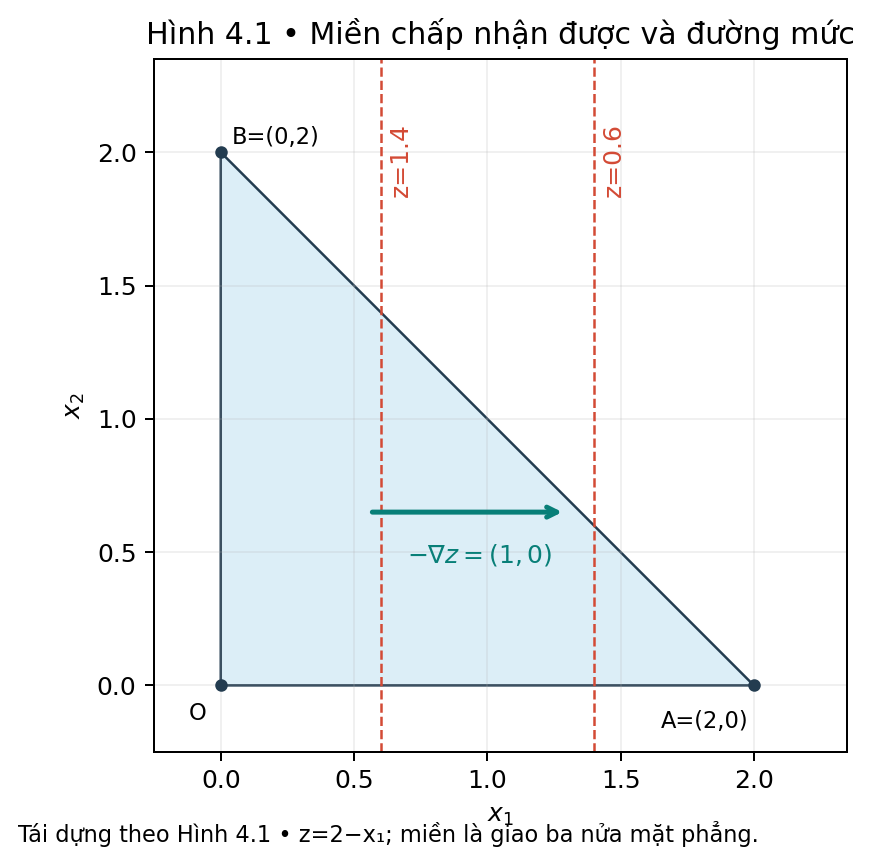

In [7]:
# NB07 | BC 4.1.1; Hình 4.1 | MasterSpec C10, section 5.2
show(plots.plot_figure_4_1(), 'figure_4_1')


#### Kết luận dễ hiểu sau NB07

**Điều cần nhớ:** Vẽ vùng được phép và cho thấy muốn giảm giá trị mục tiêu thì phải đi dần sang bên phải.

<details><summary>Ghi chú kỹ thuật — chỉ cần mở khi muốn xem sâu hơn</summary>

**Dấu hiệu kiểm tra:** Đường mức x1=1.4 và 0.6; hướng giảm sang phải.

Đường mức cuối còn tiếp xúc miền đi qua A. Mũi tên biểu diễn giảm z, không phải phép lặp Karmarkar trong hệ mới.

</details>

### NB08 · 📘 Ý TƯỞNG / THUẬT TOÁN · 4.1.1; 4.4.2; Bảng 4.1

> **Vị trí trong tài liệu:** BC 4.1.1; 4.4.2; Bảng 4.1; MasterSpec C09, §5.2 (NB08).

**Mục đích / Vì sao cần (nói ngắn gọn):** Giải thích hoặc thực hiện một bước giúp Karmarkar tìm phương án tốt dần mà vẫn tuân thủ các điều kiện.

**Cách hiểu đơn giản:** Thử ba góc của tam giác để thấy góc A cho giá trị nhỏ nhất bằng 0.

**Loại nội dung:** Phần này giúp hiểu thuật toán làm gì. Code chỉ là cách máy thực hiện ý tưởng đó.

**Input — dữ liệu đưa vào (tên dùng trong code/PDF):** O,A,B.  
*Hiểu đơn giản:* Bài toán, điểm hiện tại và các nút điều chỉnh mà bước thuật toán này cần.

**Đang làm gì — máy sẽ xử lý:** Tính mục tiêu tại ba đỉnh.

**Output — kết quả nhận được (tên dùng trong code/PDF):** bảng x1,x2,z.  
*Hiểu đơn giản:* Một hướng đi, điểm mới hoặc các con số trung gian để tiếp tục vòng Karmarkar.

**Input/Output:** đã được tách riêng ở hai dòng trên để dễ theo dõi.

**Nếu chỉ nhớ một ý:** Thử ba góc của tam giác để thấy góc A cho giá trị nhỏ nhất bằng 0.

<details><summary>Dấu hiệu kỹ thuật để kiểm tra — có thể bỏ qua ở lần đọc đầu</summary>

**Lý do kỹ thuật của bước này:** Tạo mốc kiểm tra độc lập với solver.

**Cần nhìn kết quả nào:** z(O),z(A),z(B)=2,0,2.

</details>

🧑‍💻 **Nếu bạn không học code:** có thể bỏ qua ô code ngay bên dưới, xem kết quả rồi đọc phần kết luận.

In [8]:
# NB08 | BC 4.1.1; 4.4.2; Bảng 4.1 | MasterSpec C09, section 5.2
vertices = pd.DataFrame({'vertex':['O','A','B'],'x1':[0.,2.,0.],'x2':[0.,0.,2.]})
vertices['z'] = 2-vertices.x1
display(vertices)
assert vertices.z.tolist()==[2,0,2]


,vertex,x1,x2,z
0,O,0.0,0.0,2.0
1,A,2.0,0.0,0.0
2,B,0.0,2.0,2.0


#### Kết luận dễ hiểu sau NB08

**Điều cần nhớ:** Thử ba góc của tam giác để thấy góc A cho giá trị nhỏ nhất bằng 0.

<details><summary>Ghi chú kỹ thuật — chỉ cần mở khi muốn xem sâu hơn</summary>

**Dấu hiệu kiểm tra:** z(O),z(A),z(B)=2,0,2.

Nghiệm hình học duy nhất là A=(2,0), z*=0. Đây là kết quả của bài toán hai biến cụ thể.

</details>

### NB09 · ✅ KIỂM TRA · 4.1.2; (4.44)

> **Vị trí trong tài liệu:** BC 4.1.2; (4.44); MasterSpec C09, §5.2 (NB09).

**Mục đích / Vì sao cần (nói ngắn gọn):** Phát hiện sớm kết quả sai bằng cách so với một điều kiện hoặc kết quả đã biết.

**Cách hiểu đơn giản:** Thêm một con số biểu diễn phần còn dư để biến tam giác hai chiều thành ba trọng số có tổng bằng 1.

**Loại nội dung:** Phần này xác nhận kết quả đã tính đúng hoặc phát hiện dữ liệu sai.

**Input — dữ liệu đưa vào (tên dùng trong code/PDF):** Ba điểm gốc.  
*Hiểu đơn giản:* Kết quả vừa tính cùng điều kiện đúng dùng làm mốc so sánh.

**Đang làm gì — máy sẽ xử lý:** Thêm biến bù và thử đổi tọa độ hai chiều.

**Output — kết quả nhận được (tên dùng trong code/PDF):** điểm gốc.  
*Hiểu đơn giản:* Sai số, bảng so sánh hoặc thông báo đạt/không đạt để biết bước trước có chạy đúng không.

**Input/Output:** đã được tách riêng ở hai dòng trên để dễ theo dõi.

**Nếu chỉ nhớ một ý:** Thêm một con số biểu diễn phần còn dư để biến tam giác hai chiều thành ba trọng số có tổng bằng 1.

<details><summary>Dấu hiệu kỹ thuật để kiểm tra — có thể bỏ qua ở lần đọc đầu</summary>

**Lý do kỹ thuật của bước này:** Hiểu nguồn gốc tọa độ thứ ba.

**Cần nhìn kết quả nào:** Round-trip đúng và sum(u)=1.

</details>

🧑‍💻 **Nếu bạn không học code:** có thể bỏ qua ô code ngay bên dưới, xem kết quả rồi đọc phần kết luận.

In [9]:
# NB09 | BC 4.1.2; (4.44) | MasterSpec C09, section 5.2
points = [(0.,0.),(2.,0.),(.5,.5)]
display(pd.DataFrame([{'x':x,'u':original_to_u(*x),'đổi_ngược':u_to_original(original_to_u(*x))} for x in points]))
for x in points:
    np.testing.assert_allclose(u_to_original(original_to_u(*x)),x)


,x,u,đổi_ngược
0,"(0.0, 0.0)","[0.0, 0.0, 1.0]","[0.0, 0.0]"
1,"(2.0, 0.0)","[1.0, 0.0, 0.0]","[2.0, 0.0]"
2,"(0.5, 0.5)","[0.25, 0.25, 0.5]","[0.5, 0.5]"


#### Kết luận dễ hiểu sau NB09

**Điều cần nhớ:** Thêm một con số biểu diễn phần còn dư để biến tam giác hai chiều thành ba trọng số có tổng bằng 1.

<details><summary>Ghi chú kỹ thuật — chỉ cần mở khi muốn xem sâu hơn</summary>

**Dấu hiệu kiểm tra:** Round-trip đúng và sum(u)=1.

u3=s/2 biểu diễn phần dư. Đây là chuẩn hóa tuyến tính kèm biến bù, khác phép xạ ảnh lặp lại mỗi vòng.

</details>

### NB10 · 🎨 VẼ HÌNH · 4.1.2; Hình 4.2

> **Vị trí trong tài liệu:** BC 4.1.2; Hình 4.2; MasterSpec C10, §5.2 (NB10).

**Mục đích / Vì sao cần (nói ngắn gọn):** Biến các con số thành hình để người đọc nhìn ra ý chính mà không phải đọc công thức.

**Cách hiểu đơn giản:** Đặt hai hình cạnh nhau để thấy đây vẫn là cùng một miền, chỉ thay cách ghi tọa độ.

**Loại nội dung:** Phần này dùng code để tạo hình minh họa. Bạn có thể bỏ qua code và xem hình.

**Input — dữ liệu đưa vào (tên dùng trong code/PDF):** Tam giác gốc và Δ3.  
*Hiểu đơn giản:* Các điểm hoặc số liệu đã được tính ở bước trước; chúng được đưa vào để đặt lên hình.

**Đang làm gì — máy sẽ xử lý:** Vẽ hai cách biểu diễn cùng miền.

**Output — kết quả nhận được (tên dùng trong code/PDF):** figure_4_2.  
*Hiểu đơn giản:* Một hình minh họa. Bạn chỉ cần quan sát hình và đọc chú thích, không cần đọc lệnh vẽ.

**Input/Output:** đã được tách riêng ở hai dòng trên để dễ theo dõi.

**Nếu chỉ nhớ một ý:** Đặt hai hình cạnh nhau để thấy đây vẫn là cùng một miền, chỉ thay cách ghi tọa độ.

<details><summary>Dấu hiệu kỹ thuật để kiểm tra — có thể bỏ qua ở lần đọc đầu</summary>

**Lý do kỹ thuật của bước này:** Theo dõi tương ứng O↔e3, A↔e1, B↔e2.

**Cần nhìn kết quả nào:** Điểm tâm trong hệ chuẩn là e/3.

</details>

🧑‍💻 **Nếu bạn không học code:** có thể bỏ qua ô code ngay bên dưới, xem kết quả rồi đọc phần kết luận.

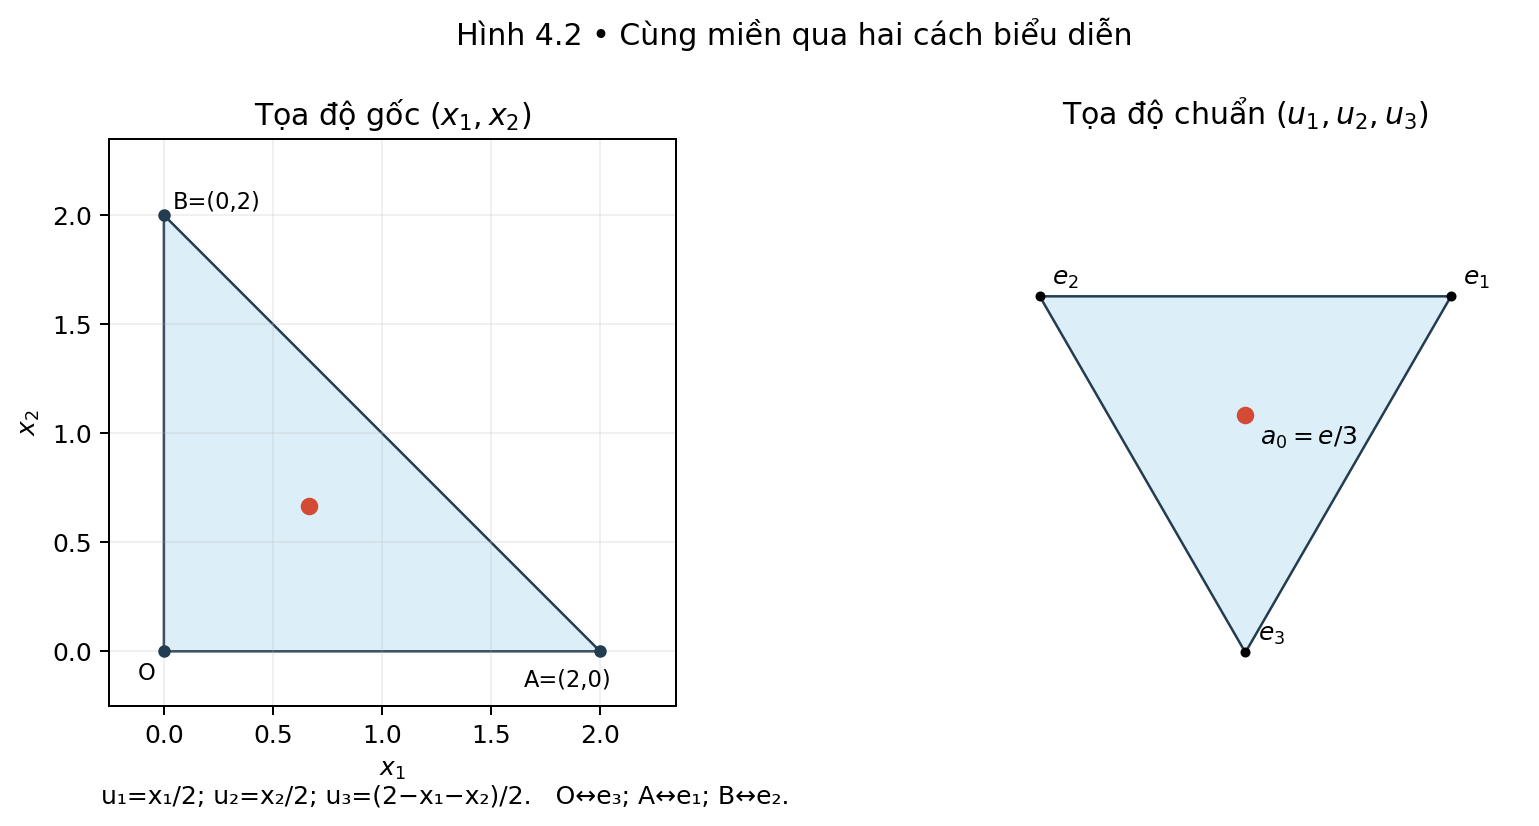

In [10]:
# NB10 | BC 4.1.2; Hình 4.2 | MasterSpec C10, section 5.2
show(plots.plot_figure_4_2(), 'figure_4_2')


#### Kết luận dễ hiểu sau NB10

**Điều cần nhớ:** Đặt hai hình cạnh nhau để thấy đây vẫn là cùng một miền, chỉ thay cách ghi tọa độ.

<details><summary>Ghi chú kỹ thuật — chỉ cần mở khi muốn xem sâu hơn</summary>

**Dấu hiệu kiểm tra:** Điểm tâm trong hệ chuẩn là e/3.

Tam giác trên giấy có thể khác hướng, nhưng sự tương ứng giữa đỉnh và tọa độ phải giữ đúng.

</details>

### NB11 · 📘 Ý TƯỞNG / THUẬT TOÁN · 4.1.3

> **Vị trí trong tài liệu:** BC 4.1.3; MasterSpec C10, §5.2 (NB11).

**Mục đích / Vì sao cần (nói ngắn gọn):** Giải thích hoặc thực hiện một bước giúp Karmarkar tìm phương án tốt dần mà vẫn tuân thủ các điều kiện.

**Cách hiểu đơn giản:** Tóm tắt toàn bộ một vòng Karmarkar bằng năm hành động dễ nhớ trước khi đi vào chi tiết.

**Loại nội dung:** Phần này giúp hiểu thuật toán làm gì. Code chỉ là cách máy thực hiện ý tưởng đó.

**Input — dữ liệu đưa vào (tên dùng trong code/PDF):** Điểm.  
*Hiểu đơn giản:* Bài toán, điểm hiện tại và các nút điều chỉnh mà bước thuật toán này cần.

**Đang làm gì — máy sẽ xử lý:** Hiển thị năm nhịp hình học.

**Output — kết quả nhận được (tên dùng trong code/PDF):** đổi ngược.  
*Hiểu đơn giản:* Một hướng đi, điểm mới hoặc các con số trung gian để tiếp tục vòng Karmarkar.

**Input/Output:** đã được tách riêng ở hai dòng trên để dễ theo dõi.

**Nếu chỉ nhớ một ý:** Tóm tắt toàn bộ một vòng Karmarkar bằng năm hành động dễ nhớ trước khi đi vào chi tiết.

<details><summary>Dấu hiệu kỹ thuật để kiểm tra — có thể bỏ qua ở lần đọc đầu</summary>

**Lý do kỹ thuật của bước này:** Nối trực giác với sáu bước điều phối của Thuật toán 4.1.

**Cần nhìn kết quả nào:** Phân biệt thao tác hình học với bước kiểm tra/dừng.

</details>

🧑‍💻 **Nếu bạn không học code:** có thể bỏ qua ô code ngay bên dưới, xem kết quả rồi đọc phần kết luận.

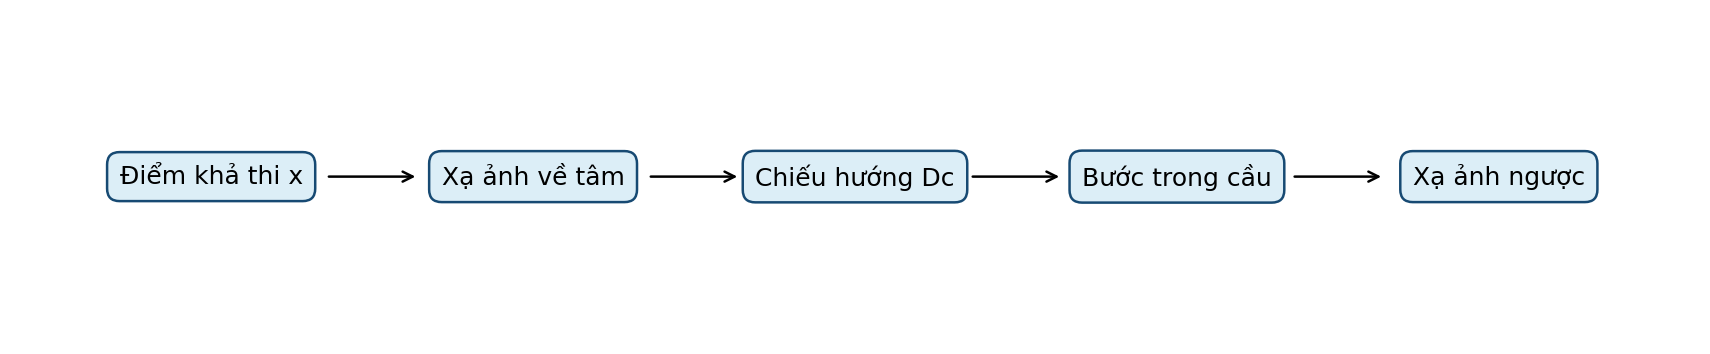

In [11]:
# NB11 | BC 4.1.3 | MasterSpec C10, section 5.2
fig,ax=plt.subplots(figsize=(12,2.3))
labels=['Điểm khả thi x','Xạ ảnh về tâm','Chiếu hướng Dc','Bước trong cầu','Xạ ảnh ngược']
for j,label in enumerate(labels):
    ax.text(j,.5,label,ha='center',va='center',bbox=dict(boxstyle='round,pad=.5',fc='#dceef7',ec='#174a73'))
    if j<4:
        ax.annotate('',(j+.65,.5),(j+.35,.5),arrowprops={'arrowstyle':'->'})
ax.set(xlim=(-.6,4.6),ylim=(0,1));ax.axis('off')
show(fig,'overview_4_1_3')


#### Kết luận dễ hiểu sau NB11

**Điều cần nhớ:** Tóm tắt toàn bộ một vòng Karmarkar bằng năm hành động dễ nhớ trước khi đi vào chi tiết.

<details><summary>Ghi chú kỹ thuật — chỉ cần mở khi muốn xem sâu hơn</summary>

**Dấu hiệu kiểm tra:** Phân biệt thao tác hình học với bước kiểm tra/dừng.

Năm thao tác này là lõi hình học; phần điều phối bổ sung đánh giá hàm thế, mục tiêu và trạng thái dừng.

</details>

## C. Các công cụ Karmarkar cần dùng — BC 4.2

**Phần này giúp bạn hiểu:** Hiểu bằng hình dung ba việc: đổi cách nhìn, giữ hướng đi không phá điều kiện và giới hạn bước để điểm mới vẫn an toàn. Không cần thuộc công thức ở lần đọc đầu.

Nếu gặp công thức khó, hãy đọc phần diễn giải bằng lời và nhìn hình/kết quả trước.

### NB12 · 📘 Ý TƯỞNG / THUẬT TOÁN · 4.2.1; (4.2)–(4.6)

> **Vị trí trong tài liệu:** BC 4.2.1; (4.2)–(4.6); MasterSpec C01/C02, §5.2 (NB12).

**Mục đích / Vì sao cần (nói ngắn gọn):** Giải thích hoặc thực hiện một bước giúp Karmarkar tìm phương án tốt dần mà vẫn tuân thủ các điều kiện.

**Cách hiểu đơn giản:** Đóng gói bài toán theo đúng định dạng chương trình cần: ma trận điều kiện và các hệ số mục tiêu.

**Loại nội dung:** Phần này giúp hiểu thuật toán làm gì. Code chỉ là cách máy thực hiện ý tưởng đó.

**Input — dữ liệu đưa vào (tên dùng trong code/PDF):** A shape (0,3), c.  
*Hiểu đơn giản:* Bài toán, điểm hiện tại và các nút điều chỉnh mà bước thuật toán này cần.

**Đang làm gì — máy sẽ xử lý:** Tạo dữ liệu chuẩn của ví dụ.

**Output — kết quả nhận được (tên dùng trong code/PDF):** CanonicalLP.  
*Hiểu đơn giản:* Một hướng đi, điểm mới hoặc các con số trung gian để tiếp tục vòng Karmarkar.

**Input/Output:** đã được tách riêng ở hai dòng trên để dễ theo dõi.

**Nếu chỉ nhớ một ý:** Đóng gói bài toán theo đúng định dạng chương trình cần: ma trận điều kiện và các hệ số mục tiêu.

<details><summary>Dấu hiệu kỹ thuật để kiểm tra — có thể bỏ qua ở lần đọc đầu</summary>

**Lý do kỹ thuật của bước này:** Không nhầm A rỗng với mảng một chiều.

**Cần nhìn kết quả nào:** m=0 hợp lệ; u có ba tọa độ.

</details>

🧑‍💻 **Nếu bạn không học code:** có thể bỏ qua ô code ngay bên dưới, xem kết quả rồi đọc phần kết luận.

In [12]:
# NB12 | BC 4.2.1; (4.2)–(4.6) | MasterSpec C01/C02, section 5.2
problem = report_example_lp()
center,r,R = simplex_geometry(3)
display(pd.DataFrame({'A.shape':[problem.A.shape],'c':[problem.c], 'n':[3],'m':[0],'a0':[center]}))


,A.shape,c,n,m,a0
0,"(0, 3)","[0.0, 1.0, 1.0]",3,0,"[0.3333333333333333, 0.3333333333333333, 0.333..."


#### Kết luận dễ hiểu sau NB12

**Điều cần nhớ:** Đóng gói bài toán theo đúng định dạng chương trình cần: ma trận điều kiện và các hệ số mục tiêu.

<details><summary>Ghi chú kỹ thuật — chỉ cần mở khi muốn xem sâu hơn</summary>

**Dấu hiệu kiểm tra:** m=0 hợp lệ; u có ba tọa độ.

Điều kiện tổng bằng 1 được thêm riêng vào B; A không chứa lại hàng eᵀ.

</details>

### NB13 · ✅ KIỂM TRA · 4.2.1; (4.7)–(4.8)

> **Vị trí trong tài liệu:** BC 4.2.1; (4.7)–(4.8); MasterSpec C02, §5.2 (NB13).

**Mục đích / Vì sao cần (nói ngắn gọn):** Phát hiện sớm kết quả sai bằng cách so với một điều kiện hoặc kết quả đã biết.

**Cách hiểu đơn giản:** Kiểm tra bài toán có đủ điều kiện để áp dụng thuật toán hay chưa, giống bước kiểm tra đầu vào trước khi khởi động máy.

**Loại nội dung:** Phần này xác nhận kết quả đã tính đúng hoặc phát hiện dữ liệu sai.

**Input — dữ liệu đưa vào (tên dùng trong code/PDF):** problem, config.  
*Hiểu đơn giản:* Kết quả vừa tính cùng điều kiện đúng dùng làm mốc so sánh.

**Đang làm gì — máy sẽ xử lý:** Kiểm tra giả thiết dạng chuẩn.

**Output — kết quả nhận được (tên dùng trong code/PDF):** ValidationReport.  
*Hiểu đơn giản:* Sai số, bảng so sánh hoặc thông báo đạt/không đạt để biết bước trước có chạy đúng không.

**Input/Output:** đã được tách riêng ở hai dòng trên để dễ theo dõi.

**Nếu chỉ nhớ một ý:** Kiểm tra bài toán có đủ điều kiện để áp dụng thuật toán hay chưa, giống bước kiểm tra đầu vào trước khi khởi động máy.

<details><summary>Dấu hiệu kỹ thuật để kiểm tra — có thể bỏ qua ở lần đọc đầu</summary>

**Lý do kỹ thuật của bước này:** Không dùng định lý khi chưa kiểm tra tiền điều kiện.

**Cần nhìn kết quả nào:** Nonnegativity PROVEN và zero witness (1,0,0) khả thi.

</details>

🧑‍💻 **Nếu bạn không học code:** có thể bỏ qua ô code ngay bên dưới, xem kết quả rồi đọc phần kết luận.

In [13]:
# NB13 | BC 4.2.1; (4.7)–(4.8) | MasterSpec C02, section 5.2
validation = validate_canonical(problem,config)
display(pd.DataFrame(plain(validation).items(),columns=['Kiểm tra','Giá trị']))


,Kiểm tra,Giá trị
0,errors,[]
1,warnings,[]
2,nonnegative,PROVEN
3,zero_optimum_known,True
4,n,3
5,m,0
6,rank_A,0


#### Kết luận dễ hiểu sau NB13

**Điều cần nhớ:** Kiểm tra bài toán có đủ điều kiện để áp dụng thuật toán hay chưa, giống bước kiểm tra đầu vào trước khi khởi động máy.

<details><summary>Ghi chú kỹ thuật — chỉ cần mở khi muốn xem sâu hơn</summary>

**Dấu hiệu kiểm tra:** Nonnegativity PROVEN và zero witness (1,0,0) khả thi.

c≥0 chứng minh cᵀu≥0 trên đơn giác; một nghiệm khả thi với mục tiêu 0 xác lập ngữ cảnh tối ưu 0 trong sai số kiểm tra đã công bố.

</details>

### NB14 · ✅ KIỂM TRA · 4.2.1; 4.3.1

> **Vị trí trong tài liệu:** BC 4.2.1; 4.3.1; MasterSpec C02, §5.2 (NB14).

**Mục đích / Vì sao cần (nói ngắn gọn):** Phát hiện sớm kết quả sai bằng cách so với một điều kiện hoặc kết quả đã biết.

**Cách hiểu đơn giản:** Cố tình đưa dữ liệu sai để chắc chắn chương trình báo lỗi rõ ràng thay vì âm thầm cho kết quả sai.

**Loại nội dung:** Phần này xác nhận kết quả đã tính đúng hoặc phát hiện dữ liệu sai.

**Input — dữ liệu đưa vào (tên dùng trong code/PDF):** Sai shape, Ae≠0, NaN.  
*Hiểu đơn giản:* Kết quả vừa tính cùng điều kiện đúng dùng làm mốc so sánh.

**Đang làm gì — máy sẽ xử lý:** Thử ba dữ liệu sai.

**Output — kết quả nhận được (tên dùng trong code/PDF):** báo lỗi.  
*Hiểu đơn giản:* Sai số, bảng so sánh hoặc thông báo đạt/không đạt để biết bước trước có chạy đúng không.

**Input/Output:** đã được tách riêng ở hai dòng trên để dễ theo dõi.

**Nếu chỉ nhớ một ý:** Cố tình đưa dữ liệu sai để chắc chắn chương trình báo lỗi rõ ràng thay vì âm thầm cho kết quả sai.

<details><summary>Dấu hiệu kỹ thuật để kiểm tra — có thể bỏ qua ở lần đọc đầu</summary>

**Lý do kỹ thuật của bước này:** Lỗi phải được trả rõ thay vì tiếp tục tính log hoặc nghịch đảo.

**Cần nhìn kết quả nào:** Cả ba đều INVALID_INPUT.

</details>

🧑‍💻 **Nếu bạn không học code:** có thể bỏ qua ô code ngay bên dưới, xem kết quả rồi đọc phần kết luận.

In [14]:
# NB14 | BC 4.2.1; 4.3.1 | MasterSpec C02, section 5.2
bad_cases = [CanonicalLP(np.zeros(3),np.ones(3),'shape'), CanonicalLP(np.array([[1.,0.,0.]]),np.ones(3),'Ae'), CanonicalLP(np.empty((0,3)),np.array([0.,np.nan,1.]),'NaN')]
display(pd.DataFrame([{'case':p.name,'status':solve_karmarkar(p).status.value,'issues':validate_canonical(p,config).errors} for p in bad_cases]))


,case,status,issues
0,shape,invalid_input,"[A must have shape (m,n), including (0,n)]"
1,Ae,invalid_input,[A@e != 0: center is not feasible; canonical p...
2,NaN,invalid_input,"[A,c must contain only finite values]"


#### Kết luận dễ hiểu sau NB14

**Điều cần nhớ:** Cố tình đưa dữ liệu sai để chắc chắn chương trình báo lỗi rõ ràng thay vì âm thầm cho kết quả sai.

<details><summary>Ghi chú kỹ thuật — chỉ cần mở khi muốn xem sâu hơn</summary>

**Dấu hiệu kiểm tra:** Cả ba đều INVALID_INPUT.

Từ chối dữ liệu sai là một phần của thuật toán phần mềm; không tự chuẩn hóa LP tổng quát chưa được hỗ trợ.

</details>

### NB15 · 📘 Ý TƯỞNG / THUẬT TOÁN · 4.2.2; (4.9)–(4.12)

> **Vị trí trong tài liệu:** BC 4.2.2; (4.9)–(4.12); MasterSpec C03, §5.2 (NB15).

**Mục đích / Vì sao cần (nói ngắn gọn):** Giải thích hoặc thực hiện một bước giúp Karmarkar tìm phương án tốt dần mà vẫn tuân thủ các điều kiện.

**Cách hiểu đơn giản:** Tính tâm và hai khoảng cách an toàn của tam giác chuẩn; chúng giúp giới hạn bước đi để không ra ngoài miền.

**Loại nội dung:** Phần này giúp hiểu thuật toán làm gì. Code chỉ là cách máy thực hiện ý tưởng đó.

**Input — dữ liệu đưa vào (tên dùng trong code/PDF):** n=2,3,4.  
*Hiểu đơn giản:* Bài toán, điểm hiện tại và các nút điều chỉnh mà bước thuật toán này cần.

**Đang làm gì — máy sẽ xử lý:** Tính trọng tâm và hai bán kính.

**Output — kết quả nhận được (tên dùng trong code/PDF):** a0,r,R,R/r.  
*Hiểu đơn giản:* Một hướng đi, điểm mới hoặc các con số trung gian để tiếp tục vòng Karmarkar.

**Input/Output:** đã được tách riêng ở hai dòng trên để dễ theo dõi.

**Nếu chỉ nhớ một ý:** Tính tâm và hai khoảng cách an toàn của tam giác chuẩn; chúng giúp giới hạn bước đi để không ra ngoài miền.

<details><summary>Dấu hiệu kỹ thuật để kiểm tra — có thể bỏ qua ở lần đọc đầu</summary>

**Lý do kỹ thuật của bước này:** n là số tọa độ của đơn giác, không phải số chiều hình vẽ.

**Cần nhìn kết quả nào:** R/r=n−1.

</details>

🧑‍💻 **Nếu bạn không học code:** có thể bỏ qua ô code ngay bên dưới, xem kết quả rồi đọc phần kết luận.

In [15]:
# NB15 | BC 4.2.2; (4.9)–(4.12) | MasterSpec C03, section 5.2
display(pd.DataFrame([{'n':n,'a0':simplex_geometry(n)[0],'r':simplex_geometry(n)[1],'R':simplex_geometry(n)[2],'R/r':simplex_geometry(n)[2]/simplex_geometry(n)[1]} for n in [2,3,4]]))


,n,a0,r,R,R/r
0,2,"[0.5, 0.5]",0.707107,0.707107,1.0
1,3,"[0.3333333333333333, 0.3333333333333333, 0.333...",0.408248,0.816497,2.0
2,4,"[0.25, 0.25, 0.25, 0.25]",0.288675,0.866025,3.0


#### Kết luận dễ hiểu sau NB15

**Điều cần nhớ:** Tính tâm và hai khoảng cách an toàn của tam giác chuẩn; chúng giúp giới hạn bước đi để không ra ngoài miền.

<details><summary>Ghi chú kỹ thuật — chỉ cần mở khi muốn xem sâu hơn</summary>

**Dấu hiệu kiểm tra:** R/r=n−1.

Bán kính được đo theo metric Euclid trong siêu phẳng tổng tọa độ bằng 1; quả cầu nhỏ bảo đảm không chạm mặt xi=0.

</details>

### NB16 · 🎨 VẼ HÌNH · 4.2.2; Hình 4.3

> **Vị trí trong tài liệu:** BC 4.2.2; Hình 4.3; MasterSpec C03/C10, §5.2 (NB16).

**Mục đích / Vì sao cần (nói ngắn gọn):** Biến các con số thành hình để người đọc nhìn ra ý chính mà không phải đọc công thức.

**Cách hiểu đơn giản:** Vẽ tam giác cùng hai đường tròn để nhìn trực tiếp vùng bước đi an toàn quanh tâm.

**Loại nội dung:** Phần này dùng code để tạo hình minh họa. Bạn có thể bỏ qua code và xem hình.

**Input — dữ liệu đưa vào (tên dùng trong code/PDF):** Δ3, r=1/√6, R=√(2/3).  
*Hiểu đơn giản:* Các điểm hoặc số liệu đã được tính ở bước trước; chúng được đưa vào để đặt lên hình.

**Đang làm gì — máy sẽ xử lý:** Vẽ hai đường tròn theo embedding trực chuẩn.

**Output — kết quả nhận được (tên dùng trong code/PDF):** figure_4_3.  
*Hiểu đơn giản:* Một hình minh họa. Bạn chỉ cần quan sát hình và đọc chú thích, không cần đọc lệnh vẽ.

**Input/Output:** đã được tách riêng ở hai dòng trên để dễ theo dõi.

**Nếu chỉ nhớ một ý:** Vẽ tam giác cùng hai đường tròn để nhìn trực tiếp vùng bước đi an toàn quanh tâm.

<details><summary>Dấu hiệu kỹ thuật để kiểm tra — có thể bỏ qua ở lần đọc đầu</summary>

**Lý do kỹ thuật của bước này:** Giữ đúng tỷ lệ khoảng cách r và R.

**Cần nhìn kết quả nào:** R/r=2; vòng trong tiếp xúc cả ba cạnh.

</details>

🧑‍💻 **Nếu bạn không học code:** có thể bỏ qua ô code ngay bên dưới, xem kết quả rồi đọc phần kết luận.

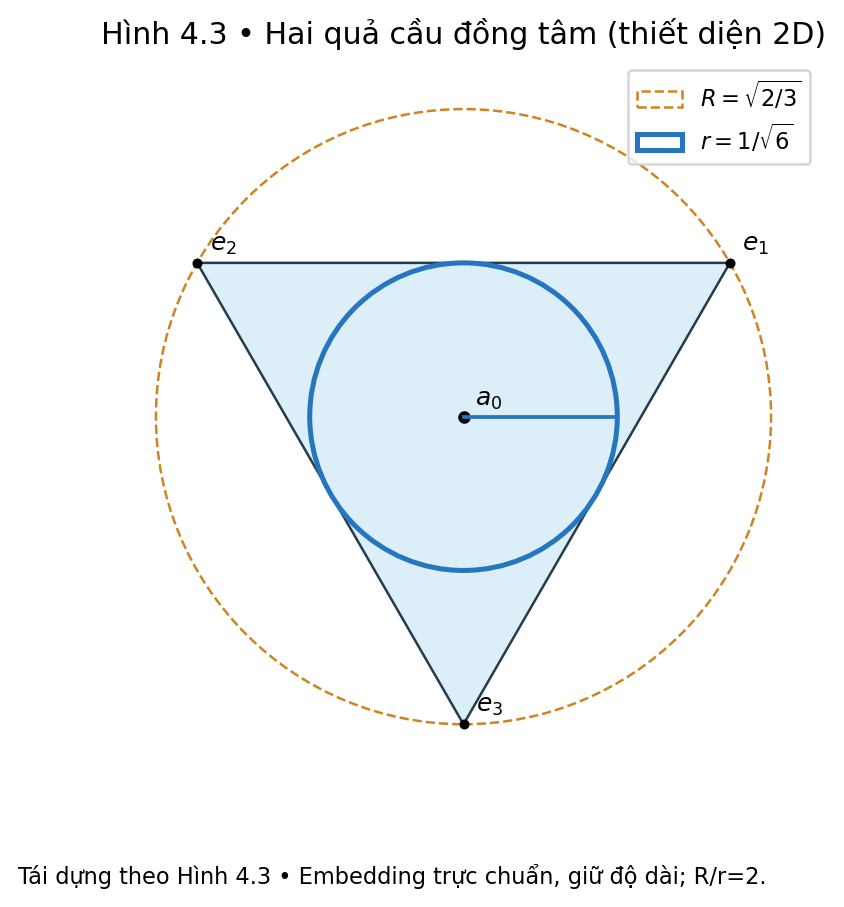

In [16]:
# NB16 | BC 4.2.2; Hình 4.3 | MasterSpec C03/C10, section 5.2
show(plots.plot_figure_4_3(), 'figure_4_3')


#### Kết luận dễ hiểu sau NB16

**Điều cần nhớ:** Vẽ tam giác cùng hai đường tròn để nhìn trực tiếp vùng bước đi an toàn quanh tâm.

<details><summary>Ghi chú kỹ thuật — chỉ cần mở khi muốn xem sâu hơn</summary>

**Dấu hiệu kiểm tra:** R/r=2; vòng trong tiếp xúc cả ba cạnh.

Một mặt của đơn giác cách tâm r; mọi đỉnh cách tâm R. Hình dùng đẳng cự nên tỷ lệ có ý nghĩa toán học.

</details>

### NB17 · ✅ KIỂM TRA · 4.2.3; (4.13)–(4.14)

> **Vị trí trong tài liệu:** BC 4.2.3; (4.13)–(4.14); MasterSpec C05, §5.2 (NB17).

**Mục đích / Vì sao cần (nói ngắn gọn):** Phát hiện sớm kết quả sai bằng cách so với một điều kiện hoặc kết quả đã biết.

**Cách hiểu đơn giản:** Cho thấy hướng giảm tự nhiên có thể làm hỏng điều kiện, nên chưa thể dùng ngay hướng đó.

**Loại nội dung:** Phần này xác nhận kết quả đã tính đúng hoặc phát hiện dữ liệu sai.

**Input — dữ liệu đưa vào (tên dùng trong code/PDF):** B=eᵀ, v=(0,1,2).  
*Hiểu đơn giản:* Kết quả vừa tính cùng điều kiện đúng dùng làm mốc so sánh.

**Đang làm gì — máy sẽ xử lý:** Tạo B,v và kiểm tra Bv.

**Output — kết quả nhận được (tên dùng trong code/PDF):** Bv.  
*Hiểu đơn giản:* Sai số, bảng so sánh hoặc thông báo đạt/không đạt để biết bước trước có chạy đúng không.

**Input/Output:** đã được tách riêng ở hai dòng trên để dễ theo dõi.

**Nếu chỉ nhớ một ý:** Cho thấy hướng giảm tự nhiên có thể làm hỏng điều kiện, nên chưa thể dùng ngay hướng đó.

<details><summary>Dấu hiệu kỹ thuật để kiểm tra — có thể bỏ qua ở lần đọc đầu</summary>

**Lý do kỹ thuật của bước này:** Vectơ mục tiêu thường không bảo toàn đẳng thức.

**Cần nhìn kết quả nào:** Bv khác 0, nên cần phép chiếu.

</details>

🧑‍💻 **Nếu bạn không học code:** có thể bỏ qua ô code ngay bên dưới, xem kết quả rồi đọc phần kết luận.

In [17]:
# NB17 | BC 4.2.3; (4.13)–(4.14) | MasterSpec C05, section 5.2
B_demo=np.ones((1,3)); v_demo=np.array([0.,1.,2.])
display({'B':B_demo,'v':v_demo,'B@v':B_demo@v_demo})


{'B': array([[1., 1., 1.]]), 'v': array([0., 1., 2.]), 'B@v': array([3.])}

#### Kết luận dễ hiểu sau NB17

**Điều cần nhớ:** Cho thấy hướng giảm tự nhiên có thể làm hỏng điều kiện, nên chưa thể dùng ngay hướng đó.

<details><summary>Ghi chú kỹ thuật — chỉ cần mở khi muốn xem sâu hơn</summary>

**Dấu hiệu kiểm tra:** Bv khác 0, nên cần phép chiếu.

Hướng d phải nằm trong Ker B để eᵀd=0 và Ad=0; lấy ngay −v có thể phá vỡ ràng buộc.

</details>

### NB18 · 🎨 VẼ HÌNH · 4.2.3; (4.15)–(4.17); Hình 4.4

> **Vị trí trong tài liệu:** BC 4.2.3; (4.15)–(4.17); Hình 4.4; MasterSpec C05/C10, §5.2 (NB18).

**Mục đích / Vì sao cần (nói ngắn gọn):** Biến các con số thành hình để người đọc nhìn ra ý chính mà không phải đọc công thức.

**Cách hiểu đơn giản:** Giữ lại phần của hướng giảm vẫn tôn trọng điều kiện; có thể hình dung như chiếu một mũi tên xuống đường được phép đi.

**Loại nội dung:** Phần này dùng code để tạo hình minh họa. Bạn có thể bỏ qua code và xem hình.

**Input — dữ liệu đưa vào (tên dùng trong code/PDF):** B,v.  
*Hiểu đơn giản:* Các điểm hoặc số liệu đã được tính ở bước trước; chúng được đưa vào để đặt lên hình.

**Đang làm gì — máy sẽ xử lý:** Chiếu v và minh họa trực giao.

**Output — kết quả nhận được (tên dùng trong code/PDF):** p và residuals.  
*Hiểu đơn giản:* Một hình minh họa. Bạn chỉ cần quan sát hình và đọc chú thích, không cần đọc lệnh vẽ.

**Input/Output:** đã được tách riêng ở hai dòng trên để dễ theo dõi.

**Nếu chỉ nhớ một ý:** Giữ lại phần của hướng giảm vẫn tôn trọng điều kiện; có thể hình dung như chiếu một mũi tên xuống đường được phép đi.

<details><summary>Dấu hiệu kỹ thuật để kiểm tra — có thể bỏ qua ở lần đọc đầu</summary>

**Lý do kỹ thuật của bước này:** Loại thành phần vuông góc với không gian hướng.

**Cần nhìn kết quả nào:** Bp≈0; v−p trực giao không gian kernel.

</details>

🧑‍💻 **Nếu bạn không học code:** có thể bỏ qua ô code ngay bên dưới, xem kết quả rồi đọc phần kết luận.

{'p': array([-1.00000000e+00,  1.48114718e-17,  1.00000000e+00]),
 'B@p': array([1.11022302e-16]),
 'rank': 1,
 'null_dim': 2,
 'svd_cutoff': 1.7320508075688773e-14,
 'singular_values': array([1.73205081]),
 'equality_residual': 1.1102230246251565e-16,
 'orthogonality_residual': 1.7772239894833365e-16,
 'p_orthogonal_remainder': 2.220446049250313e-16}

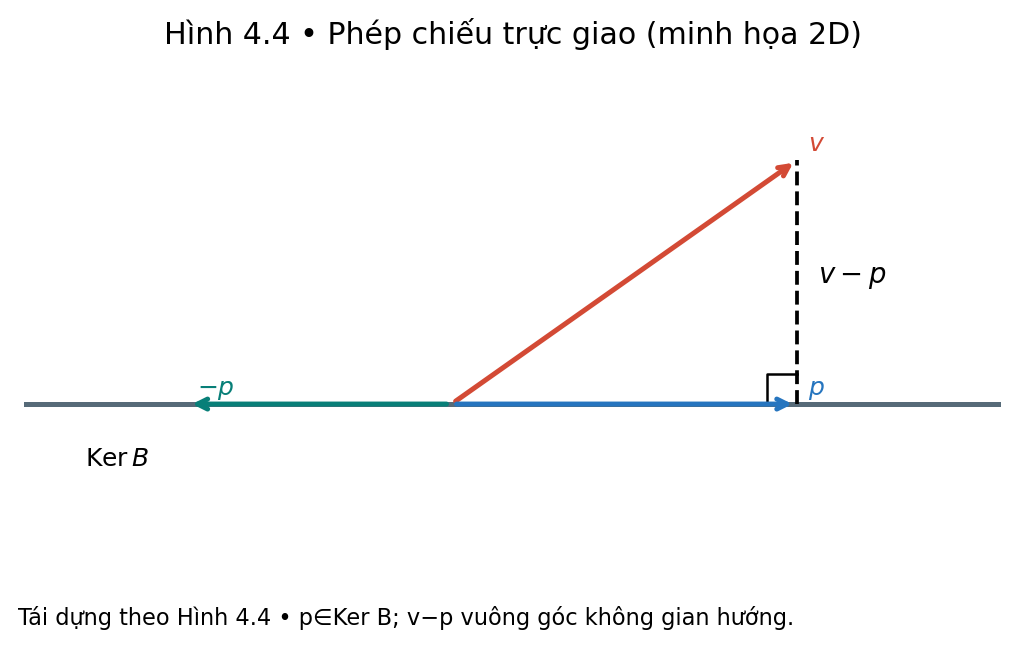

In [18]:
# NB18 | BC 4.2.3; (4.15)–(4.17); Hình 4.4 | MasterSpec C05/C10, section 5.2
p_demo, projection_info=project_to_kernel(B_demo,v_demo)
display({'p':p_demo,'B@p':B_demo@p_demo,**projection_info})
show(plots.plot_figure_4_4(),'figure_4_4')


#### Kết luận dễ hiểu sau NB18

**Điều cần nhớ:** Giữ lại phần của hướng giảm vẫn tôn trọng điều kiện; có thể hình dung như chiếu một mũi tên xuống đường được phép đi.

<details><summary>Ghi chú kỹ thuật — chỉ cần mở khi muốn xem sâu hơn</summary>

**Dấu hiệu kiểm tra:** Bp≈0; v−p trực giao không gian kernel.

Hình 4.4 là sơ đồ 2D; số v,p vừa in là ví dụ 3D. Hướng đơn vị giảm hàm tuyến tính phụ là −p/‖p‖ khi p khác 0.

</details>

### NB19 · ✅ KIỂM TRA · 4.2.3; trang in 41

> **Vị trí trong tài liệu:** BC 4.2.3; trang in 41; MasterSpec C05, §5.2 (NB19).

**Mục đích / Vì sao cần (nói ngắn gọn):** Phát hiện sớm kết quả sai bằng cách so với một điều kiện hoặc kết quả đã biết.

**Cách hiểu đơn giản:** Thử trường hợp có điều kiện trùng nhau để chắc chắn phép chiếu vẫn chạy ổn định.

**Loại nội dung:** Phần này xác nhận kết quả đã tính đúng hoặc phát hiện dữ liệu sai.

**Input — dữ liệu đưa vào (tên dùng trong code/PDF):** B có hàng lặp.  
*Hiểu đơn giản:* Kết quả vừa tính cùng điều kiện đúng dùng làm mốc so sánh.

**Đang làm gì — máy sẽ xử lý:** Thử SVD với hàng ràng buộc phụ thuộc.

**Output — kết quả nhận được (tên dùng trong code/PDF):** rank,nullity,residual.  
*Hiểu đơn giản:* Sai số, bảng so sánh hoặc thông báo đạt/không đạt để biết bước trước có chạy đúng không.

**Input/Output:** đã được tách riêng ở hai dòng trên để dễ theo dõi.

**Nếu chỉ nhớ một ý:** Thử trường hợp có điều kiện trùng nhau để chắc chắn phép chiếu vẫn chạy ổn định.

<details><summary>Dấu hiệu kỹ thuật để kiểm tra — có thể bỏ qua ở lần đọc đầu</summary>

**Lý do kỹ thuật của bước này:** Nghịch đảo BBᵀ có thể không tồn tại.

**Cần nhìn kết quả nào:** Chiếu thành công mà không dùng inv(BBᵀ).

</details>

🧑‍💻 **Nếu bạn không học code:** có thể bỏ qua ô code ngay bên dưới, xem kết quả rồi đọc phần kết luận.

In [19]:
# NB19 | BC 4.2.3; trang in 41 | MasterSpec C05, section 5.2
B_dep=np.array([[1.,-1.,0.],[2.,-2.,0.],[1.,1.,1.]])
p_dep,dep_info=project_to_kernel(B_dep,v_demo)
display({'p':p_dep,**dep_info})


{'p': array([-0.5, -0.5,  1. ]),
 'rank': 2,
 'null_dim': 1,
 'svd_cutoff': 3.16227766016838e-14,
 'singular_values': array([3.16227766e+00, 1.73205081e+00, 3.07799688e-16]),
 'equality_residual': 2.7194799110210365e-16,
 'orthogonality_residual': 2.220446049250313e-16,
 'p_orthogonal_remainder': 2.220446049250313e-16}

#### Kết luận dễ hiểu sau NB19

**Điều cần nhớ:** Thử trường hợp có điều kiện trùng nhau để chắc chắn phép chiếu vẫn chạy ổn định.

<details><summary>Ghi chú kỹ thuật — chỉ cần mở khi muốn xem sâu hơn</summary>

**Dấu hiệu kiểm tra:** Chiếu thành công mà không dùng inv(BBᵀ).

Hạng được xác định bằng cutoff SVD có co giãn theo singular value lớn nhất; các trường hợp gần suy biến cần đọc cả residual và cutoff.

</details>

### NB20 · ✅ KIỂM TRA · 4.2.4; (4.19)–(4.21)

> **Vị trí trong tài liệu:** BC 4.2.4; (4.19)–(4.21); MasterSpec C04, §5.2 (NB20).

**Mục đích / Vì sao cần (nói ngắn gọn):** Phát hiện sớm kết quả sai bằng cách so với một điều kiện hoặc kết quả đã biết.

**Cách hiểu đơn giản:** Dùng cùng một phép đổi tọa độ cho hai điểm để thấy chỉ điểm làm mốc được đưa về tâm, không phải mọi điểm.

**Loại nội dung:** Phần này xác nhận kết quả đã tính đúng hoặc phát hiện dữ liệu sai.

**Input — dữ liệu đưa vào (tên dùng trong code/PDF):** a=(1/2,1/4,1/4), b=(2/3,1/6,1/6).  
*Hiểu đơn giản:* Kết quả vừa tính cùng điều kiện đúng dùng làm mốc so sánh.

**Đang làm gì — máy sẽ xử lý:** Thử hai điểm với cùng mốc a.

**Output — kết quả nhận được (tên dùng trong code/PDF):** Tₐ(a),Tₐ(b).  
*Hiểu đơn giản:* Sai số, bảng so sánh hoặc thông báo đạt/không đạt để biết bước trước có chạy đúng không.

**Input/Output:** đã được tách riêng ở hai dòng trên để dễ theo dõi.

**Nếu chỉ nhớ một ý:** Dùng cùng một phép đổi tọa độ cho hai điểm để thấy chỉ điểm làm mốc được đưa về tâm, không phải mọi điểm.

<details><summary>Dấu hiệu kỹ thuật để kiểm tra — có thể bỏ qua ở lần đọc đầu</summary>

**Lý do kỹ thuật của bước này:** Không biến mỗi điểm bằng chính nó làm mốc.

**Cần nhìn kết quả nào:** Tₐ(a)=e/3; Tₐ(b)=a khác e/3.

</details>

🧑‍💻 **Nếu bạn không học code:** có thể bỏ qua ô code ngay bên dưới, xem kết quả rồi đọc phần kết luận.

In [20]:
# NB20 | BC 4.2.4; (4.19)–(4.21) | MasterSpec C04, section 5.2
a=np.array([.5,.25,.25]); b=np.array([2/3,1/6,1/6])
display({'a':a,'b':b,'T_a(a)':to_projective(a,a),'T_a(b)':to_projective(a,b)})


{'a': array([0.5 , 0.25, 0.25]),
 'b': array([0.66666667, 0.16666667, 0.16666667]),
 'T_a(a)': array([0.33333333, 0.33333333, 0.33333333]),
 'T_a(b)': array([0.5 , 0.25, 0.25])}

#### Kết luận dễ hiểu sau NB20

**Điều cần nhớ:** Dùng cùng một phép đổi tọa độ cho hai điểm để thấy chỉ điểm làm mốc được đưa về tâm, không phải mọi điểm.

<details><summary>Ghi chú kỹ thuật — chỉ cần mở khi muốn xem sâu hơn</summary>

**Dấu hiệu kiểm tra:** Tₐ(a)=e/3; Tₐ(b)=a khác e/3.

Phép đổi hệ tọa độ giữ đỉnh và từng mặt; điểm mốc về trọng tâm nhưng các điểm khác thay đổi theo cùng một ánh xạ.

</details>

### NB21 · 📘 Ý TƯỞNG / THUẬT TOÁN · 4.2.4; (4.20)

> **Vị trí trong tài liệu:** BC 4.2.4; (4.20); MasterSpec C04, §5.2 (NB21).

**Mục đích / Vì sao cần (nói ngắn gọn):** Giải thích hoặc thực hiện một bước giúp Karmarkar tìm phương án tốt dần mà vẫn tuân thủ các điều kiện.

**Cách hiểu đơn giản:** Đổi tọa độ rồi đổi ngược lại; nếu kết quả trở về đúng điểm ban đầu thì phép biến đổi được cài đúng.

**Loại nội dung:** Phần này giúp hiểu thuật toán làm gì. Code chỉ là cách máy thực hiện ý tưởng đó.

**Input — dữ liệu đưa vào (tên dùng trong code/PDF):** a,Tₐ(b).  
*Hiểu đơn giản:* Bài toán, điểm hiện tại và các nút điều chỉnh mà bước thuật toán này cần.

**Đang làm gì — máy sẽ xử lý:** Đổi ngược điểm b.

**Output — kết quả nhận được (tên dùng trong code/PDF):** b phục hồi.  
*Hiểu đơn giản:* Một hướng đi, điểm mới hoặc các con số trung gian để tiếp tục vòng Karmarkar.

**Input/Output:** đã được tách riêng ở hai dòng trên để dễ theo dõi.

**Nếu chỉ nhớ một ý:** Đổi tọa độ rồi đổi ngược lại; nếu kết quả trở về đúng điểm ban đầu thì phép biến đổi được cài đúng.

<details><summary>Dấu hiệu kỹ thuật để kiểm tra — có thể bỏ qua ở lần đọc đầu</summary>

**Lý do kỹ thuật của bước này:** Kiểm tra ánh xạ nghịch đảo độc lập.

**Cần nhìn kết quả nào:** Sai số round-trip gần 0.

</details>

🧑‍💻 **Nếu bạn không học code:** có thể bỏ qua ô code ngay bên dưới, xem kết quả rồi đọc phần kết luận.

In [21]:
# NB21 | BC 4.2.4; (4.20) | MasterSpec C04, section 5.2
b_back=from_projective(a,to_projective(a,b))
display({'b_back':b_back,'error_norm':np.linalg.norm(b_back-b)})


{'b_back': array([0.66666667, 0.16666667, 0.16666667]),
 'error_norm': np.float64(0.0)}

#### Kết luận dễ hiểu sau NB21

**Điều cần nhớ:** Đổi tọa độ rồi đổi ngược lại; nếu kết quả trở về đúng điểm ban đầu thì phép biến đổi được cài đúng.

<details><summary>Ghi chú kỹ thuật — chỉ cần mở khi muốn xem sâu hơn</summary>

**Dấu hiệu kiểm tra:** Sai số round-trip gần 0.

Mốc a phải cố định trong cả phép thuận và nghịch; sang vòng mới, a sẽ đổi theo nghiệm hiện tại.

</details>

### NB22 · 🎨 VẼ HÌNH · 4.2.4; Hình 4.5

> **Vị trí trong tài liệu:** BC 4.2.4; Hình 4.5; MasterSpec C04/C10, §5.2 (NB22).

**Mục đích / Vì sao cần (nói ngắn gọn):** Biến các con số thành hình để người đọc nhìn ra ý chính mà không phải đọc công thức.

**Cách hiểu đơn giản:** Vẽ trước và sau khi đổi cách nhìn để thấy các điểm đổi vị trí trên hình nhưng vẫn đại diện cho cùng bài toán.

**Loại nội dung:** Phần này dùng code để tạo hình minh họa. Bạn có thể bỏ qua code và xem hình.

**Input — dữ liệu đưa vào (tên dùng trong code/PDF):** Mốc cố định a.  
*Hiểu đơn giản:* Các điểm hoặc số liệu đã được tính ở bước trước; chúng được đưa vào để đặt lên hình.

**Đang làm gì — máy sẽ xử lý:** Vẽ hai hệ xạ ảnh.

**Output — kết quả nhận được (tên dùng trong code/PDF):** figure_4_5.  
*Hiểu đơn giản:* Một hình minh họa. Bạn chỉ cần quan sát hình và đọc chú thích, không cần đọc lệnh vẽ.

**Input/Output:** đã được tách riêng ở hai dòng trên để dễ theo dõi.

**Nếu chỉ nhớ một ý:** Vẽ trước và sau khi đổi cách nhìn để thấy các điểm đổi vị trí trên hình nhưng vẫn đại diện cho cùng bài toán.

<details><summary>Dấu hiệu kỹ thuật để kiểm tra — có thể bỏ qua ở lần đọc đầu</summary>

**Lý do kỹ thuật của bước này:** Theo dõi đồng thời a,b và một lưới điểm.

**Cần nhìn kết quả nào:** Chỉ a về tâm; b vẫn ở vị trí riêng.

</details>

🧑‍💻 **Nếu bạn không học code:** có thể bỏ qua ô code ngay bên dưới, xem kết quả rồi đọc phần kết luận.

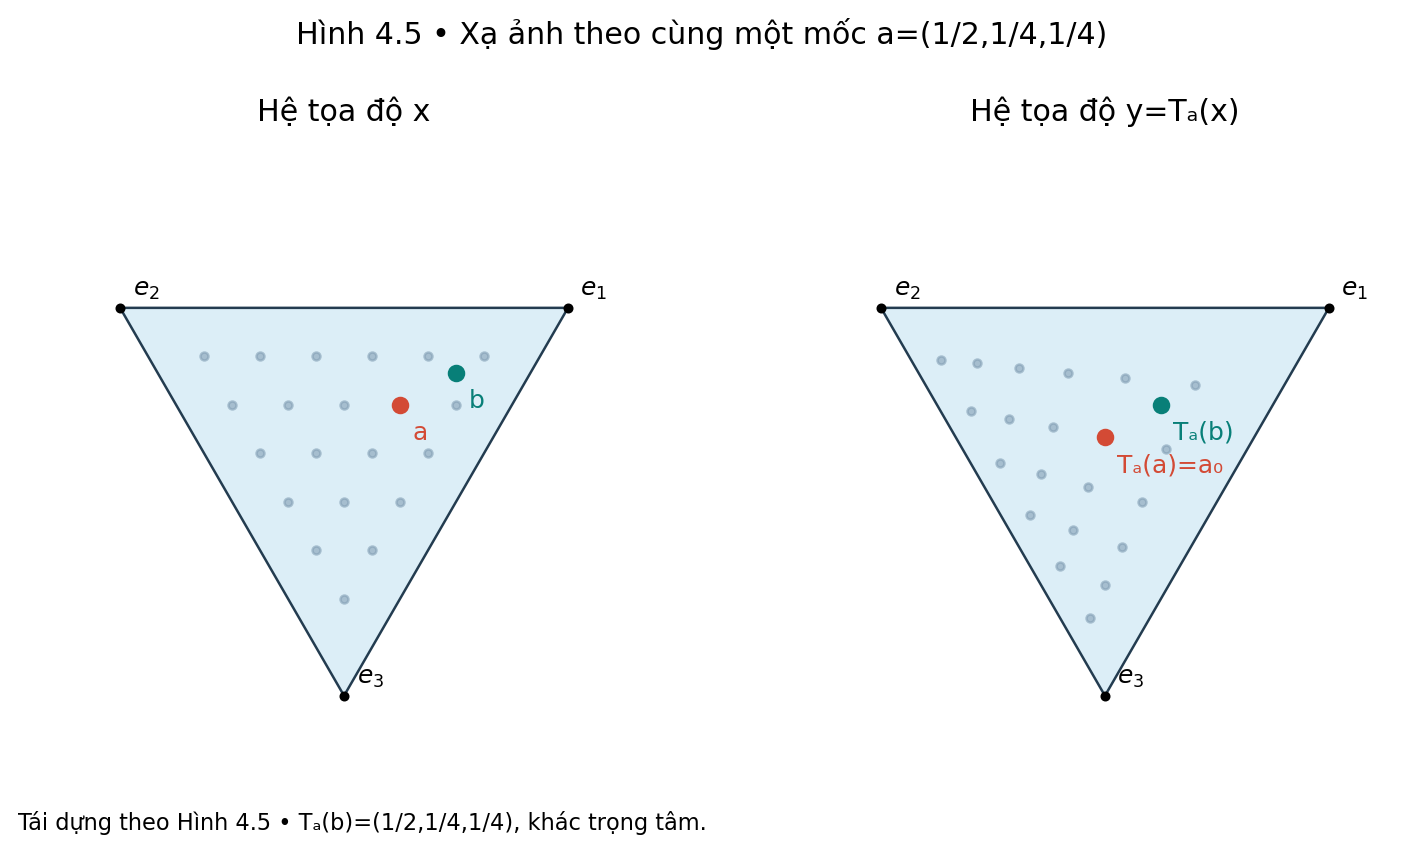

In [22]:
# NB22 | BC 4.2.4; Hình 4.5 | MasterSpec C04/C10, section 5.2
show(plots.plot_figure_4_5(a), 'figure_4_5')


#### Kết luận dễ hiểu sau NB22

**Điều cần nhớ:** Vẽ trước và sau khi đổi cách nhìn để thấy các điểm đổi vị trí trên hình nhưng vẫn đại diện cho cùng bài toán.

<details><summary>Ghi chú kỹ thuật — chỉ cần mở khi muốn xem sâu hơn</summary>

**Dấu hiệu kiểm tra:** Chỉ a về tâm; b vẫn ở vị trí riêng.

Đây là cách biểu diễn mới của các điểm trong đơn giác; không phải phép quay, tịnh tiến hay phép đồng dạng.

</details>

### NB23 · ✅ KIỂM TRA · 4.2.4; (4.22)–(4.23)

> **Vị trí trong tài liệu:** BC 4.2.4; (4.22)–(4.23); MasterSpec C04/C06, §5.2 (NB23).

**Mục đích / Vì sao cần (nói ngắn gọn):** Phát hiện sớm kết quả sai bằng cách so với một điều kiện hoặc kết quả đã biết.

**Cách hiểu đơn giản:** Kiểm tra giá trị mục tiêu gốc vẫn được tính đúng sau khi đổi tọa độ; công thức phụ chỉ dùng để chọn hướng đi.

**Loại nội dung:** Phần này xác nhận kết quả đã tính đúng hoặc phát hiện dữ liệu sai.

**Input — dữ liệu đưa vào (tên dùng trong code/PDF):** x=b; y=Tₐ(b); c.  
*Hiểu đơn giản:* Kết quả vừa tính cùng điều kiện đúng dùng làm mốc so sánh.

**Đang làm gì — máy sẽ xử lý:** Đối chiếu mục tiêu phân tuyến tính.

**Output — kết quả nhận được (tên dùng trong code/PDF):** hai giá trị mục tiêu.  
*Hiểu đơn giản:* Sai số, bảng so sánh hoặc thông báo đạt/không đạt để biết bước trước có chạy đúng không.

**Input/Output:** đã được tách riêng ở hai dòng trên để dễ theo dõi.

**Nếu chỉ nhớ một ý:** Kiểm tra giá trị mục tiêu gốc vẫn được tính đúng sau khi đổi tọa độ; công thức phụ chỉ dùng để chọn hướng đi.

<details><summary>Dấu hiệu kỹ thuật để kiểm tra — có thể bỏ qua ở lần đọc đầu</summary>

**Lý do kỹ thuật của bước này:** Không nhầm hệ số phụ Dc với mục tiêu gốc sau đổi tọa độ.

**Cần nhìn kết quả nào:** cᵀx=(Dc)ᵀy/(eᵀDy), thường khác (Dc)ᵀy.

</details>

🧑‍💻 **Nếu bạn không học code:** có thể bỏ qua ô code ngay bên dưới, xem kết quả rồi đọc phần kết luận.

In [23]:
# NB23 | BC 4.2.4; (4.22)–(4.23) | MasterSpec C04/C06, section 5.2
y_b=to_projective(a,b)
display({'original':problem.c@b, 'fractional':(a*problem.c)@y_b/(a@y_b), 'linear_surrogate':(a*problem.c)@y_b})


{'original': np.float64(0.3333333333333333),
 'fractional': np.float64(0.3333333333333333),
 'linear_surrogate': np.float64(0.125)}

#### Kết luận dễ hiểu sau NB23

**Điều cần nhớ:** Kiểm tra giá trị mục tiêu gốc vẫn được tính đúng sau khi đổi tọa độ; công thức phụ chỉ dùng để chọn hướng đi.

<details><summary>Ghi chú kỹ thuật — chỉ cần mở khi muốn xem sâu hơn</summary>

**Dấu hiệu kiểm tra:** cᵀx=(Dc)ᵀy/(eᵀDy), thường khác (Dc)ᵀy.

Hàm tuyến tính phụ được tối thiểu trên quả cầu để chọn bước. Sự tiến triển của thuật toán được phân tích bằng hàm thế, không suy ra chỉ từ việc giảm tử số.

</details>

### NB24 · 📘 Ý TƯỞNG / THUẬT TOÁN · 4.2.5; (4.24)–(4.28)

> **Vị trí trong tài liệu:** BC 4.2.5; (4.24)–(4.28); MasterSpec C05/C07, §5.2 (NB24).

**Mục đích / Vì sao cần (nói ngắn gọn):** Giải thích hoặc thực hiện một bước giúp Karmarkar tìm phương án tốt dần mà vẫn tuân thủ các điều kiện.

**Cách hiểu đơn giản:** Từ điểm ở tâm, chương trình tìm hướng hợp lệ rồi đi một đoạn ngắn trong vùng an toàn.

**Loại nội dung:** Phần này giúp hiểu thuật toán làm gì. Code chỉ là cách máy thực hiện ý tưởng đó.

**Input — dữ liệu đưa vào (tên dùng trong code/PDF):** problem, center, alpha.  
*Hiểu đơn giản:* Bài toán, điểm hiện tại và các nút điều chỉnh mà bước thuật toán này cần.

**Đang làm gì — máy sẽ xử lý:** Tính bước mẫu trên quả cầu.

**Output — kết quả nhận được (tên dùng trong code/PDF):** B,p,d,y.  
*Hiểu đơn giản:* Một hướng đi, điểm mới hoặc các con số trung gian để tiếp tục vòng Karmarkar.

**Input/Output:** đã được tách riêng ở hai dòng trên để dễ theo dõi.

**Nếu chỉ nhớ một ý:** Từ điểm ở tâm, chương trình tìm hướng hợp lệ rồi đi một đoạn ngắn trong vùng an toàn.

<details><summary>Dấu hiệu kỹ thuật để kiểm tra — có thể bỏ qua ở lần đọc đầu</summary>

**Lý do kỹ thuật của bước này:** Dùng Cauchy–Schwarz để chọn hướng tối thiểu tuyến tính phụ.

**Cần nhìn kết quả nào:** Bd≈0; ‖d‖≈1; (Dc)ᵀh≥−αr‖p‖.

</details>

🧑‍💻 **Nếu bạn không học code:** có thể bỏ qua ô code ngay bên dưới, xem kết quả rồi đọc phần kết luận.

In [24]:
# NB24 | BC 4.2.5; (4.24)–(4.28) | MasterSpec C05/C07, section 5.2
demo_step=karmarkar_step(problem,center,config)
display(show_step_table(demo_step))
assert np.linalg.norm(demo_step.B@demo_step.d)<1e-12


,Đại lượng,Giá trị
0,k,0
1,x_before,[0.333333333 0.333333333 0.333333333]
2,D,[[0.333333333 0. 0. ]\n [0. ...
3,B,[[1. 1. 1.]]
4,v,[0. 0.333333333 0.333333333]
5,p,[-0.222222222 0.111111111 0.111111111]
6,d,[ 0.816496581 -0.40824829 -0.40824829 ]
7,y,[0.416666667 0.291666667 0.291666667]
8,x_after,[0.416666667 0.291666667 0.291666667]
9,f_before,0.666667


#### Kết luận dễ hiểu sau NB24

**Điều cần nhớ:** Từ điểm ở tâm, chương trình tìm hướng hợp lệ rồi đi một đoạn ngắn trong vùng an toàn.

<details><summary>Ghi chú kỹ thuật — chỉ cần mở khi muốn xem sâu hơn</summary>

**Dấu hiệu kiểm tra:** Bd≈0; ‖d‖≈1; (Dc)ᵀh≥−αr‖p‖.

Với h thuộc Ker B, (Dc)ᵀh=pᵀh≥−‖p‖‖h‖. Chọn h=−αrp/‖p‖ đạt dấu bằng và vẫn nằm trong đơn giác.

</details>

### NB25 · 🎨 VẼ HÌNH · 4.2.5; Hình 4.6

> **Vị trí trong tài liệu:** BC 4.2.5; Hình 4.6; MasterSpec C07/C10, §5.2 (NB25).

**Mục đích / Vì sao cần (nói ngắn gọn):** Biến các con số thành hình để người đọc nhìn ra ý chính mà không phải đọc công thức.

**Cách hiểu đơn giản:** Vẽ riêng bước đi vừa tính để thấy điểm mới chưa chạm biên và vẫn nằm trong vùng an toàn.

**Loại nội dung:** Phần này dùng code để tạo hình minh họa. Bạn có thể bỏ qua code và xem hình.

**Input — dữ liệu đưa vào (tên dùng trong code/PDF):** demo_step.  
*Hiểu đơn giản:* Các điểm hoặc số liệu đã được tính ở bước trước; chúng được đưa vào để đặt lên hình.

**Đang làm gì — máy sẽ xử lý:** Vẽ bước thật trong quả cầu.

**Output — kết quả nhận được (tên dùng trong code/PDF):** figure_4_6.  
*Hiểu đơn giản:* Một hình minh họa. Bạn chỉ cần quan sát hình và đọc chú thích, không cần đọc lệnh vẽ.

**Input/Output:** đã được tách riêng ở hai dòng trên để dễ theo dõi.

**Nếu chỉ nhớ một ý:** Vẽ riêng bước đi vừa tính để thấy điểm mới chưa chạm biên và vẫn nằm trong vùng an toàn.

<details><summary>Dấu hiệu kỹ thuật để kiểm tra — có thể bỏ qua ở lần đọc đầu</summary>

**Lý do kỹ thuật của bước này:** Thấy αr<r giữ tọa độ dương.

**Cần nhìn kết quả nào:** Điểm y nằm trên đường tròn αr, bên trong đường tròn r.

</details>

🧑‍💻 **Nếu bạn không học code:** có thể bỏ qua ô code ngay bên dưới, xem kết quả rồi đọc phần kết luận.

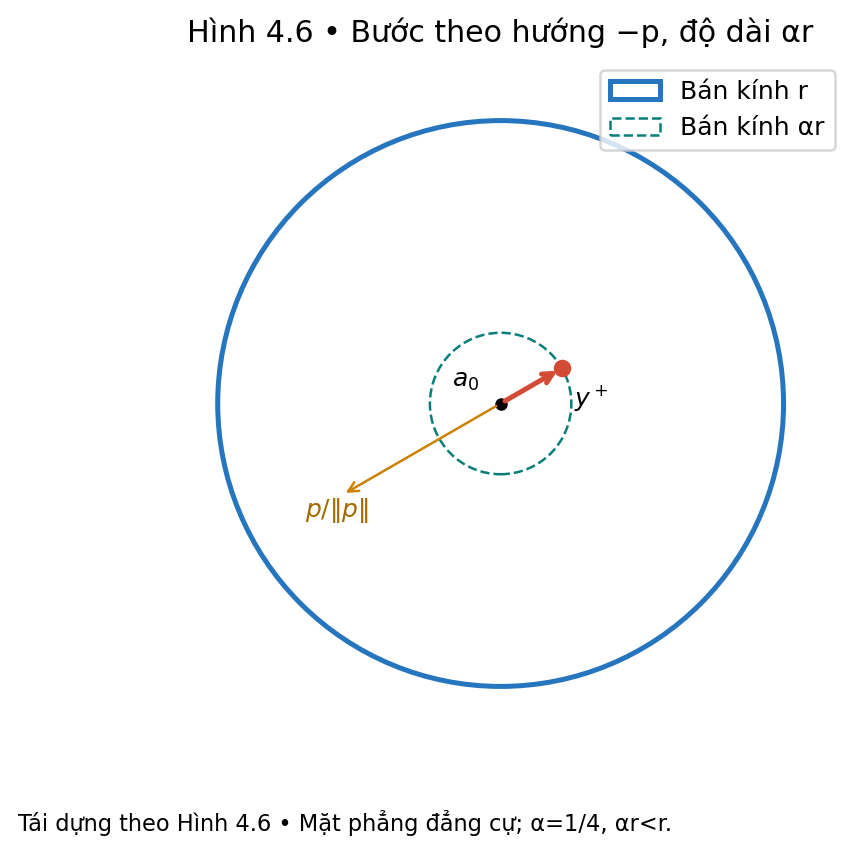

In [25]:
# NB25 | BC 4.2.5; Hình 4.6 | MasterSpec C07/C10, section 5.2
show(plots.plot_figure_4_6(demo_step), 'figure_4_6')


#### Kết luận dễ hiểu sau NB25

**Điều cần nhớ:** Vẽ riêng bước đi vừa tính để thấy điểm mới chưa chạm biên và vẫn nằm trong vùng an toàn.

<details><summary>Ghi chú kỹ thuật — chỉ cần mở khi muốn xem sâu hơn</summary>

**Dấu hiệu kiểm tra:** Điểm y nằm trên đường tròn αr, bên trong đường tròn r.

Quả cầu giữ tính dương; phép chiếu giữ ràng buộc đẳng thức. Hai điều kiện đều cần thiết.

</details>

### NB26 · 📘 Ý TƯỞNG / THUẬT TOÁN · 4.2.6; (4.29)–(4.31)

> **Vị trí trong tài liệu:** BC 4.2.6; (4.29)–(4.31); MasterSpec C06, §5.2 (NB26).

**Mục đích / Vì sao cần (nói ngắn gọn):** Giải thích hoặc thực hiện một bước giúp Karmarkar tìm phương án tốt dần mà vẫn tuân thủ các điều kiện.

**Cách hiểu đơn giản:** Tính thước đo tiến triển ở hai hệ tọa độ; hai con số có thể lệch nhau một hằng số nhưng mức thay đổi phải giống nhau.

**Loại nội dung:** Phần này giúp hiểu thuật toán làm gì. Code chỉ là cách máy thực hiện ý tưởng đó.

**Input — dữ liệu đưa vào (tên dùng trong code/PDF):** a,y,c.  
*Hiểu đơn giản:* Bài toán, điểm hiện tại và các nút điều chỉnh mà bước thuật toán này cần.

**Đang làm gì — máy sẽ xử lý:** Tính hai hàm thế với D cố định.

**Output — kết quả nhận được (tên dùng trong code/PDF):** Phi(x), Phi_tilde(y), hằng số.  
*Hiểu đơn giản:* Một hướng đi, điểm mới hoặc các con số trung gian để tiếp tục vòng Karmarkar.

**Input/Output:** đã được tách riêng ở hai dòng trên để dễ theo dõi.

**Nếu chỉ nhớ một ý:** Tính thước đo tiến triển ở hai hệ tọa độ; hai con số có thể lệch nhau một hằng số nhưng mức thay đổi phải giống nhau.

<details><summary>Dấu hiệu kỹ thuật để kiểm tra — có thể bỏ qua ở lần đọc đầu</summary>

**Lý do kỹ thuật của bước này:** Bất biến hiệu không có nghĩa giá trị tuyệt đối bằng nhau.

**Cần nhìn kết quả nào:** Phi(x)−Phi_tilde(y)=−Σln(ai).

</details>

🧑‍💻 **Nếu bạn không học code:** có thể bỏ qua ô code ngay bên dưới, xem kết quả rồi đọc phần kết luận.

In [26]:
# NB26 | BC 4.2.6; (4.29)–(4.31) | MasterSpec C06, section 5.2
y0=center.copy(); y1=np.array([.4,.3,.3]); x0=from_projective(a,y0); x1=from_projective(a,y1)
display({'Phi(x1)':potential(x1,problem.c),'Phi_tilde(y1)':transformed_potential(a,y1,problem.c),
         'offset':-np.log(a).sum()})


{'Phi(x1)': 1.09861228866811,
 'Phi_tilde(y1)': -2.367123614131617,
 'offset': np.float64(3.465735902799726)}

#### Kết luận dễ hiểu sau NB26

**Điều cần nhớ:** Tính thước đo tiến triển ở hai hệ tọa độ; hai con số có thể lệch nhau một hằng số nhưng mức thay đổi phải giống nhau.

<details><summary>Ghi chú kỹ thuật — chỉ cần mở khi muốn xem sâu hơn</summary>

**Dấu hiệu kiểm tra:** Phi(x)−Phi_tilde(y)=−Σln(ai).

Khi thay x=Dy/(eᵀDy), các số hạng chứa n ln(eᵀDy) triệt tiêu. Chỉ còn hằng số phụ thuộc mốc a.

</details>

### NB27 · ✅ KIỂM TRA · 4.2.6; Mệnh đề 4.2.5

> **Vị trí trong tài liệu:** BC 4.2.6; Mệnh đề 4.2.5; MasterSpec C06, §5.2 (NB27).

**Mục đích / Vì sao cần (nói ngắn gọn):** Phát hiện sớm kết quả sai bằng cách so với một điều kiện hoặc kết quả đã biết.

**Cách hiểu đơn giản:** So mức thay đổi trước và sau đổi tọa độ để xác nhận thước đo tiến triển không bị bóp méo.

**Loại nội dung:** Phần này xác nhận kết quả đã tính đúng hoặc phát hiện dữ liệu sai.

**Input — dữ liệu đưa vào (tên dùng trong code/PDF):** Hai điểm tương ứng cùng D.  
*Hiểu đơn giản:* Kết quả vừa tính cùng điều kiện đúng dùng làm mốc so sánh.

**Đang làm gì — máy sẽ xử lý:** Kiểm tra hiệu hàm thế.

**Output — kết quả nhận được (tên dùng trong code/PDF):** delta_old,delta_new.  
*Hiểu đơn giản:* Sai số, bảng so sánh hoặc thông báo đạt/không đạt để biết bước trước có chạy đúng không.

**Input/Output:** đã được tách riêng ở hai dòng trên để dễ theo dõi.

**Nếu chỉ nhớ một ý:** So mức thay đổi trước và sau đổi tọa độ để xác nhận thước đo tiến triển không bị bóp méo.

<details><summary>Dấu hiệu kỹ thuật để kiểm tra — có thể bỏ qua ở lần đọc đầu</summary>

**Lý do kỹ thuật của bước này:** Theo dõi tiến triển qua hai hệ tọa độ.

**Cần nhìn kết quả nào:** Sai số chênh lệch dưới tolerance.

</details>

🧑‍💻 **Nếu bạn không học code:** có thể bỏ qua ô code ngay bên dưới, xem kết quả rồi đọc phần kết luận.

In [27]:
# NB27 | BC 4.2.6; Mệnh đề 4.2.5 | MasterSpec C06, section 5.2
delta_old=potential(x1,problem.c)-potential(x0,problem.c)
delta_new=transformed_potential(a,y1,problem.c)-transformed_potential(a,y0,problem.c)
display({'delta_original':delta_old,'delta_transformed':delta_new,'error':abs(delta_old-delta_new)})
assert abs(delta_old-delta_new)<1e-12


{'delta_original': -0.28768207245178035,
 'delta_transformed': -0.2876820724517808,
 'error': 4.440892098500626e-16}

#### Kết luận dễ hiểu sau NB27

**Điều cần nhớ:** So mức thay đổi trước và sau đổi tọa độ để xác nhận thước đo tiến triển không bị bóp méo.

<details><summary>Ghi chú kỹ thuật — chỉ cần mở khi muốn xem sâu hơn</summary>

**Dấu hiệu kiểm tra:** Sai số chênh lệch dưới tolerance.

Hằng số −Σln(ai) bị khử khi lấy hiệu trong cùng vòng. Không so các hệ có D khác nhau mà bỏ qua mốc.

</details>

### NB28 · ✅ KIỂM TRA · 4.2.7; (4.32)

> **Vị trí trong tài liệu:** BC 4.2.7; (4.32); MasterSpec C06/C08, §5.2 (NB28).

**Mục đích / Vì sao cần (nói ngắn gọn):** Phát hiện sớm kết quả sai bằng cách so với một điều kiện hoặc kết quả đã biết.

**Cách hiểu đơn giản:** Kiểm tra trong ví dụ này mỗi vòng làm thước đo tiến triển giảm đủ nhiều so với mốc lý thuyết.

**Loại nội dung:** Phần này xác nhận kết quả đã tính đúng hoặc phát hiện dữ liệu sai.

**Input — dữ liệu đưa vào (tên dùng trong code/PDF):** demo_step.  
*Hiểu đơn giản:* Kết quả vừa tính cùng điều kiện đúng dùng làm mốc so sánh.

**Đang làm gì — máy sẽ xử lý:** So mức giảm mẫu với 1/8.

**Output — kết quả nhận được (tên dùng trong code/PDF):** mức giảm và thông tin giả thiết.  
*Hiểu đơn giản:* Sai số, bảng so sánh hoặc thông báo đạt/không đạt để biết bước trước có chạy đúng không.

**Input/Output:** đã được tách riêng ở hai dòng trên để dễ theo dõi.

**Nếu chỉ nhớ một ý:** Kiểm tra trong ví dụ này mỗi vòng làm thước đo tiến triển giảm đủ nhiều so với mốc lý thuyết.

<details><summary>Dấu hiệu kỹ thuật để kiểm tra — có thể bỏ qua ở lần đọc đầu</summary>

**Lý do kỹ thuật của bước này:** Đánh dấu rõ phạm vi áp dụng định lý.

**Cần nhìn kết quả nào:** Giảm ln(10/7)≈0.356675>1/8 trong ví dụ.

</details>

🧑‍💻 **Nếu bạn không học code:** có thể bỏ qua ô code ngay bên dưới, xem kết quả rồi đọc phần kết luận.

In [28]:
# NB28 | BC 4.2.7; (4.32) | MasterSpec C06/C08, section 5.2
decrease=demo_step.phi_before-demo_step.phi_after
display({'decrease':decrease,'threshold':1/8,'alpha':config.alpha,'nonnegative':validation.nonnegative.value,'zero_optimum_witness_checked':validation.zero_optimum_known})


{'decrease': 0.356674943938732,
 'threshold': 0.125,
 'alpha': 0.25,
 'nonnegative': 'PROVEN',
 'zero_optimum_witness_checked': True}

#### Kết luận dễ hiểu sau NB28

**Điều cần nhớ:** Kiểm tra trong ví dụ này mỗi vòng làm thước đo tiến triển giảm đủ nhiều so với mốc lý thuyết.

<details><summary>Ghi chú kỹ thuật — chỉ cần mở khi muốn xem sâu hơn</summary>

**Dấu hiệu kiểm tra:** Giảm ln(10/7)≈0.356675>1/8 trong ví dụ.

Định lý nguồn phát biểu mức giảm hoặc nhận diện cực tiểu dương dưới các giả thiết/thủ tục gốc. Trong float64, một lần kiểm tra thất bại chỉ là diagnostic, không phải chứng nhận cực tiểu dương.

</details>

### NB29 · 🎨 VẼ HÌNH · 4.2.8; (4.33)–(4.36)

> **Vị trí trong tài liệu:** BC 4.2.8; (4.33)–(4.36); MasterSpec C06/C10, §5.2 (NB29).

**Mục đích / Vì sao cần (nói ngắn gọn):** Biến các con số thành hình để người đọc nhìn ra ý chính mà không phải đọc công thức.

**Cách hiểu đơn giản:** Minh họa ý tưởng rằng số vòng có thể được ước lượng trong lý thuyết; hình này không phải kết quả đo thời gian chạy.

**Loại nội dung:** Phần này dùng code để tạo hình minh họa. Bạn có thể bỏ qua code và xem hình.

**Input — dữ liệu đưa vào (tên dùng trong code/PDF):** n=3, δ=1/8, k.  
*Hiểu đơn giản:* Các điểm hoặc số liệu đã được tính ở bước trước; chúng được đưa vào để đặt lên hình.

**Đang làm gì — máy sẽ xử lý:** Vẽ cận ký hiệu của log tỷ số mục tiêu.

**Output — kết quả nhận được (tên dùng trong code/PDF):** ln(n)−kδ/n.  
*Hiểu đơn giản:* Một hình minh họa. Bạn chỉ cần quan sát hình và đọc chú thích, không cần đọc lệnh vẽ.

**Input/Output:** đã được tách riêng ở hai dòng trên để dễ theo dõi.

**Nếu chỉ nhớ một ý:** Minh họa ý tưởng rằng số vòng có thể được ước lượng trong lý thuyết; hình này không phải kết quả đo thời gian chạy.

<details><summary>Dấu hiệu kỹ thuật để kiểm tra — có thể bỏ qua ở lần đọc đầu</summary>

**Lý do kỹ thuật của bước này:** Phân biệt cận số vòng với thời gian chạy mã.

**Cần nhìn kết quả nào:** Hình chỉ minh họa cận lý thuyết có giả thiết.

</details>

🧑‍💻 **Nếu bạn không học code:** có thể bỏ qua ô code ngay bên dưới, xem kết quả rồi đọc phần kết luận.

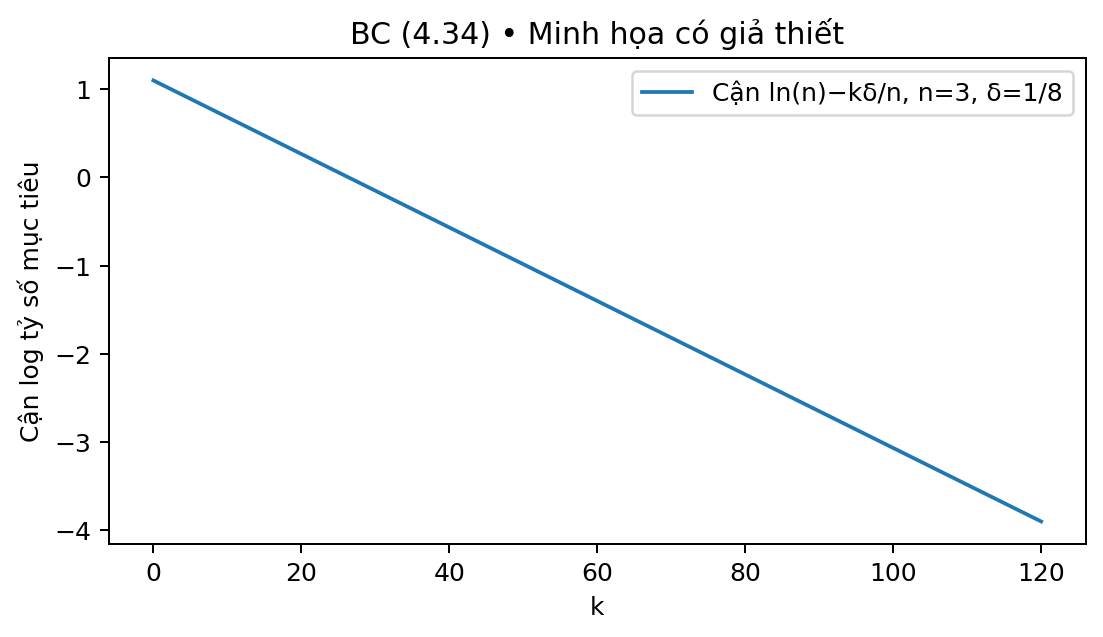

In [29]:
# NB29 | BC 4.2.8; (4.33)–(4.36) | MasterSpec C06/C10, section 5.2
kk=np.arange(121)
fig,ax=plt.subplots(figsize=(7,3.5))
ax.plot(kk,np.log(3)-kk/(8*3),label='Cận ln(n)−kδ/n, n=3, δ=1/8')
ax.set(xlabel='k',ylabel='Cận log tỷ số mục tiêu',title='BC (4.34) • Minh họa có giả thiết')
ax.legend();show(fig,'theoretical_iteration_bound')


#### Kết luận dễ hiểu sau NB29

**Điều cần nhớ:** Minh họa ý tưởng rằng số vòng có thể được ước lượng trong lý thuyết; hình này không phải kết quả đo thời gian chạy.

<details><summary>Ghi chú kỹ thuật — chỉ cần mở khi muốn xem sâu hơn</summary>

**Dấu hiệu kiểm tra:** Hình chỉ minh họa cận lý thuyết có giả thiết.

Từ $\ln(c^Tx^k/c^Ta_0)\le\ln n-k\delta/n$, đạt tỷ số $2^{-q}$ sau $O(n(q+\ln n))$ vòng trong mô hình nguồn. Cận $O(n^{3.5}L)$ phép toán được dẫn cho phiên bản cải tiến, không phải chứng minh runtime của mã SVD này. Nghiệm hữu tỉ chính xác còn cần thủ tục cực biên/chứng nhận riêng.

</details>

## D. Một vòng Karmarkar diễn ra thế nào — BC 4.3

**Phần này giúp bạn hiểu:** Ghép các công cụ ở phần trước thành một quy trình: chuẩn bị dữ liệu, tìm hướng hợp lệ, đi một bước, đổi về tọa độ gốc rồi kiểm tra kết quả.

Nếu gặp công thức khó, hãy đọc phần diễn giải bằng lời và nhìn hình/kết quả trước.

### NB30 · 📘 Ý TƯỞNG / THUẬT TOÁN · 4.3.1

> **Vị trí trong tài liệu:** BC 4.3.1; MasterSpec C01/C02, §5.2 (NB30).

**Mục đích / Vì sao cần (nói ngắn gọn):** Giải thích hoặc thực hiện một bước giúp Karmarkar tìm phương án tốt dần mà vẫn tuân thủ các điều kiện.

**Cách hiểu đơn giản:** Khóa bài toán, điểm xuất phát và các nút điều chỉnh trước khi bắt đầu vòng lặp đầu tiên.

**Loại nội dung:** Phần này giúp hiểu thuật toán làm gì. Code chỉ là cách máy thực hiện ý tưởng đó.

**Input — dữ liệu đưa vào (tên dùng trong code/PDF):** problem, config.  
*Hiểu đơn giản:* Bài toán, điểm hiện tại và các nút điều chỉnh mà bước thuật toán này cần.

**Đang làm gì — máy sẽ xử lý:** Khóa dữ liệu và giả thiết.

**Output — kết quả nhận được (tên dùng trong code/PDF):** input/validation.  
*Hiểu đơn giản:* Một hướng đi, điểm mới hoặc các con số trung gian để tiếp tục vòng Karmarkar.

**Input/Output:** đã được tách riêng ở hai dòng trên để dễ theo dõi.

**Nếu chỉ nhớ một ý:** Khóa bài toán, điểm xuất phát và các nút điều chỉnh trước khi bắt đầu vòng lặp đầu tiên.

<details><summary>Dấu hiệu kỹ thuật để kiểm tra — có thể bỏ qua ở lần đọc đầu</summary>

**Lý do kỹ thuật của bước này:** Xác định rõ điều kiện trước khi chạy solver.

**Cần nhìn kết quả nào:** Ae=0; a0>0; cᵀa0>0; alpha=1/4.

</details>

🧑‍💻 **Nếu bạn không học code:** có thể bỏ qua ô code ngay bên dưới, xem kết quả rồi đọc phần kết luận.

In [30]:
# NB30 | BC 4.3.1 | MasterSpec C01/C02, section 5.2
display({'A':problem.A,'c':problem.c,'center':center,'alpha':config.alpha,'validation':plain(validation)})


{'A': array([], shape=(0, 3), dtype=float64),
 'c': array([0., 1., 1.]),
 'center': array([0.33333333, 0.33333333, 0.33333333]),
 'alpha': 0.25,
 'validation': {'errors': [],
  'warnings': [],
  'nonnegative': 'PROVEN',
  'zero_optimum_known': True,
  'n': 3,
  'm': 0,
  'rank_A': 0}}

#### Kết luận dễ hiểu sau NB30

**Điều cần nhớ:** Khóa bài toán, điểm xuất phát và các nút điều chỉnh trước khi bắt đầu vòng lặp đầu tiên.

<details><summary>Ghi chú kỹ thuật — chỉ cần mở khi muốn xem sâu hơn</summary>

**Dấu hiệu kiểm tra:** Ae=0; a0>0; cᵀa0>0; alpha=1/4.

Chọn e/n làm điểm đầu chỉ hợp lệ cho dữ liệu đã chuẩn hóa và có Ae=0.

</details>

### NB31 · 📘 Ý TƯỞNG / THUẬT TOÁN · 4.3.2; (4.37)

> **Vị trí trong tài liệu:** BC 4.3.2; (4.37); MasterSpec C07, §5.2 (NB31).

**Mục đích / Vì sao cần (nói ngắn gọn):** Giải thích hoặc thực hiện một bước giúp Karmarkar tìm phương án tốt dần mà vẫn tuân thủ các điều kiện.

**Cách hiểu đơn giản:** Tạo ba đối tượng trung gian từ điểm hiện tại: cách co giãn tọa độ, điều kiện được phép và hướng muốn giảm.

**Loại nội dung:** Phần này giúp hiểu thuật toán làm gì. Code chỉ là cách máy thực hiện ý tưởng đó.

**Input — dữ liệu đưa vào (tên dùng trong code/PDF):** demo_step.  
*Hiểu đơn giản:* Bài toán, điểm hiện tại và các nút điều chỉnh mà bước thuật toán này cần.

**Đang làm gì — máy sẽ xử lý:** In D,B,v từ bước thực.

**Output — kết quả nhận được (tên dùng trong code/PDF):** ba ma trận/vectơ.  
*Hiểu đơn giản:* Một hướng đi, điểm mới hoặc các con số trung gian để tiếp tục vòng Karmarkar.

**Input/Output:** đã được tách riêng ở hai dòng trên để dễ theo dõi.

**Nếu chỉ nhớ một ý:** Tạo ba đối tượng trung gian từ điểm hiện tại: cách co giãn tọa độ, điều kiện được phép và hướng muốn giảm.

<details><summary>Dấu hiệu kỹ thuật để kiểm tra — có thể bỏ qua ở lần đọc đầu</summary>

**Lý do kỹ thuật của bước này:** Theo dõi AD thay vì A trong hệ mới.

**Cần nhìn kết quả nào:** B=[AD;eᵀ], v=Dc.

</details>

🧑‍💻 **Nếu bạn không học code:** có thể bỏ qua ô code ngay bên dưới, xem kết quả rồi đọc phần kết luận.

In [31]:
# NB31 | BC 4.3.2; (4.37) | MasterSpec C07, section 5.2
display({'x':demo_step.x_before,'D':demo_step.D,'B':demo_step.B,'v':demo_step.v})


{'x': array([0.33333333, 0.33333333, 0.33333333]),
 'D': array([[0.33333333, 0.        , 0.        ],
        [0.        , 0.33333333, 0.        ],
        [0.        , 0.        , 0.33333333]]),
 'B': array([[1., 1., 1.]]),
 'v': array([0.        , 0.33333333, 0.33333333])}

#### Kết luận dễ hiểu sau NB31

**Điều cần nhớ:** Tạo ba đối tượng trung gian từ điểm hiện tại: cách co giãn tọa độ, điều kiện được phép và hướng muốn giảm.

<details><summary>Ghi chú kỹ thuật — chỉ cần mở khi muốn xem sâu hơn</summary>

**Dấu hiệu kiểm tra:** B=[AD;eᵀ], v=Dc.

Ma trận D được lập lại từ điểm hiện tại mỗi vòng; với ví dụ ban đầu D0=I/3.

</details>

### NB32 · ✅ KIỂM TRA · 4.3.2; (4.38)–(4.39)

> **Vị trí trong tài liệu:** BC 4.3.2; (4.38)–(4.39); MasterSpec C05/C07, §5.2 (NB32).

**Mục đích / Vì sao cần (nói ngắn gọn):** Phát hiện sớm kết quả sai bằng cách so với một điều kiện hoặc kết quả đã biết.

**Cách hiểu đơn giản:** Biến hướng muốn giảm thành hướng vừa giảm được mục tiêu vừa không phá điều kiện.

**Loại nội dung:** Phần này xác nhận kết quả đã tính đúng hoặc phát hiện dữ liệu sai.

**Input — dữ liệu đưa vào (tên dùng trong code/PDF):** demo_step.  
*Hiểu đơn giản:* Kết quả vừa tính cùng điều kiện đúng dùng làm mốc so sánh.

**Đang làm gì — máy sẽ xử lý:** Kiểm p,d và các chuẩn.

**Output — kết quả nhận được (tên dùng trong code/PDF):** p,d,Bp,Bd,‖d‖.  
*Hiểu đơn giản:* Sai số, bảng so sánh hoặc thông báo đạt/không đạt để biết bước trước có chạy đúng không.

**Input/Output:** đã được tách riêng ở hai dòng trên để dễ theo dõi.

**Nếu chỉ nhớ một ý:** Biến hướng muốn giảm thành hướng vừa giảm được mục tiêu vừa không phá điều kiện.

<details><summary>Dấu hiệu kỹ thuật để kiểm tra — có thể bỏ qua ở lần đọc đầu</summary>

**Lý do kỹ thuật của bước này:** Không chuẩn hóa khi p bằng 0 hoặc quá nhỏ.

**Cần nhìn kết quả nào:** ‖d‖=1; Bp,Bd≈0.

</details>

🧑‍💻 **Nếu bạn không học code:** có thể bỏ qua ô code ngay bên dưới, xem kết quả rồi đọc phần kết luận.

In [32]:
# NB32 | BC 4.3.2; (4.38)–(4.39) | MasterSpec C05/C07, section 5.2
display({'p':demo_step.p,'d':demo_step.d,'Bp':demo_step.B@demo_step.p,'Bd':demo_step.B@demo_step.d,'norm(d)':np.linalg.norm(demo_step.d)})


{'p': array([-0.22222222,  0.11111111,  0.11111111]),
 'd': array([ 0.81649658, -0.40824829, -0.40824829]),
 'Bp': array([2.77555756e-17]),
 'Bd': array([0.]),
 'norm(d)': np.float64(0.9999999999999999)}

#### Kết luận dễ hiểu sau NB32

**Điều cần nhớ:** Biến hướng muốn giảm thành hướng vừa giảm được mục tiêu vừa không phá điều kiện.

<details><summary>Ghi chú kỹ thuật — chỉ cần mở khi muốn xem sâu hơn</summary>

**Dấu hiệu kiểm tra:** ‖d‖=1; Bp,Bd≈0.

SVD xử lý hàng phụ thuộc; nullspace rỗng và p quá nhỏ được đưa về trạng thái riêng, không tự gọi là tối ưu.

</details>

### NB33 · 📘 Ý TƯỞNG / THUẬT TOÁN · 4.3.2; (4.40)–(4.41)

> **Vị trí trong tài liệu:** BC 4.3.2; (4.40)–(4.41); MasterSpec C04/C07, §5.2 (NB33).

**Mục đích / Vì sao cần (nói ngắn gọn):** Giải thích hoặc thực hiện một bước giúp Karmarkar tìm phương án tốt dần mà vẫn tuân thủ các điều kiện.

**Cách hiểu đơn giản:** Đi một bước trong hệ tọa độ dễ tính rồi đổi kết quả về hệ tọa độ ban đầu.

**Loại nội dung:** Phần này giúp hiểu thuật toán làm gì. Code chỉ là cách máy thực hiện ý tưởng đó.

**Input — dữ liệu đưa vào (tên dùng trong code/PDF):** D,y.  
*Hiểu đơn giản:* Bài toán, điểm hiện tại và các nút điều chỉnh mà bước thuật toán này cần.

**Đang làm gì — máy sẽ xử lý:** Theo dõi y và x_next.

**Output — kết quả nhận được (tên dùng trong code/PDF):** mẫu số, x_next.  
*Hiểu đơn giản:* Một hướng đi, điểm mới hoặc các con số trung gian để tiếp tục vòng Karmarkar.

**Input/Output:** đã được tách riêng ở hai dòng trên để dễ theo dõi.

**Nếu chỉ nhớ một ý:** Đi một bước trong hệ tọa độ dễ tính rồi đổi kết quả về hệ tọa độ ban đầu.

<details><summary>Dấu hiệu kỹ thuật để kiểm tra — có thể bỏ qua ở lần đọc đầu</summary>

**Lý do kỹ thuật của bước này:** Không dùng tọa độ mới làm nghiệm gốc cho mọi vòng.

**Cần nhìn kết quả nào:** Mẫu số dương, x_next=Dy/sum(Dy).

</details>

🧑‍💻 **Nếu bạn không học code:** có thể bỏ qua ô code ngay bên dưới, xem kết quả rồi đọc phần kết luận.

In [33]:
# NB33 | BC 4.3.2; (4.40)–(4.41) | MasterSpec C04/C07, section 5.2
display({'y':demo_step.y,'D@y':demo_step.D@demo_step.y,'denominator':demo_step.diagnostics['denominator'],'x_next':demo_step.x_after})


{'y': array([0.41666667, 0.29166667, 0.29166667]),
 'D@y': array([0.13888889, 0.09722222, 0.09722222]),
 'denominator': 0.33333333333333326,
 'x_next': array([0.41666667, 0.29166667, 0.29166667])}

#### Kết luận dễ hiểu sau NB33

**Điều cần nhớ:** Đi một bước trong hệ tọa độ dễ tính rồi đổi kết quả về hệ tọa độ ban đầu.

<details><summary>Ghi chú kỹ thuật — chỉ cần mở khi muốn xem sâu hơn</summary>

**Dấu hiệu kiểm tra:** Mẫu số dương, x_next=Dy/sum(Dy).

Ở vòng đầu D0 có các phần tử bằng nhau nên phép đổi ngược triệt tiêu hệ số chung. Sự trùng số giữa y và x_next không đúng cho mọi vòng.

</details>

### NB34 · 📘 Ý TƯỞNG / THUẬT TOÁN · 4.3.2; Mệnh đề 4.3.1

> **Vị trí trong tài liệu:** BC 4.3.2; Mệnh đề 4.3.1; MasterSpec C07, §5.2 (NB34).

**Mục đích / Vì sao cần (nói ngắn gọn):** Giải thích hoặc thực hiện một bước giúp Karmarkar tìm phương án tốt dần mà vẫn tuân thủ các điều kiện.

**Cách hiểu đơn giản:** Kiểm tra điểm mới vẫn dương, tổng vẫn bằng 1 và các điều kiện vẫn được giữ trong sai số máy tính.

**Loại nội dung:** Phần này giúp hiểu thuật toán làm gì. Code chỉ là cách máy thực hiện ý tưởng đó.

**Input — dữ liệu đưa vào (tên dùng trong code/PDF):** StepRecord.  
*Hiểu đơn giản:* Bài toán, điểm hiện tại và các nút điều chỉnh mà bước thuật toán này cần.

**Đang làm gì — máy sẽ xử lý:** In bảng bất biến và hàm thế.

**Output — kết quả nhận được (tên dùng trong code/PDF):** bảng diagnostics.  
*Hiểu đơn giản:* Một hướng đi, điểm mới hoặc các con số trung gian để tiếp tục vòng Karmarkar.

**Input/Output:** đã được tách riêng ở hai dòng trên để dễ theo dõi.

**Nếu chỉ nhớ một ý:** Kiểm tra điểm mới vẫn dương, tổng vẫn bằng 1 và các điều kiện vẫn được giữ trong sai số máy tính.

<details><summary>Dấu hiệu kỹ thuật để kiểm tra — có thể bỏ qua ở lần đọc đầu</summary>

**Lý do kỹ thuật của bước này:** Kiểm cả tính dương, tổng tọa độ và đẳng thức.

**Cần nhìn kết quả nào:** Residual nhỏ; bước αr; mục tiêu và Phi được ghi riêng.

</details>

🧑‍💻 **Nếu bạn không học code:** có thể bỏ qua ô code ngay bên dưới, xem kết quả rồi đọc phần kết luận.

In [34]:
# NB34 | BC 4.3.2; Mệnh đề 4.3.1 | MasterSpec C07, section 5.2
display(show_step_table(demo_step,include_matrices=False))


,Đại lượng,Giá trị
0,k,0
1,x_before,[0.333333333 0.333333333 0.333333333]
2,D,"{'shape': (3, 3), 'norm': 0.5773502691896257, ..."
3,B,"{'shape': (1, 3), 'norm': 1.7320508075688772, ..."
4,v,[0. 0.333333333 0.333333333]
5,p,[-0.222222222 0.111111111 0.111111111]
6,d,[ 0.816496581 -0.40824829 -0.40824829 ]
7,y,[0.416666667 0.291666667 0.291666667]
8,x_after,[0.416666667 0.291666667 0.291666667]
9,f_before,0.666667


#### Kết luận dễ hiểu sau NB34

**Điều cần nhớ:** Kiểm tra điểm mới vẫn dương, tổng vẫn bằng 1 và các điều kiện vẫn được giữ trong sai số máy tính.

<details><summary>Ghi chú kỹ thuật — chỉ cần mở khi muốn xem sâu hơn</summary>

**Dấu hiệu kiểm tra:** Residual nhỏ; bước αr; mục tiêu và Phi được ghi riêng.

Đây là kiểm chứng số trong tolerance; chứng minh toán học dùng ADa0=0, Bd=0 và αr<r, rồi dùng mẫu số dương của phép đổi ngược.

</details>

### NB35 · 📘 Ý TƯỞNG / THUẬT TOÁN · 4.3.3; Thuật toán 4.1

> **Vị trí trong tài liệu:** BC 4.3.3; Thuật toán 4.1; MasterSpec C08, §5.2 (NB35).

**Mục đích / Vì sao cần (nói ngắn gọn):** Giải thích hoặc thực hiện một bước giúp Karmarkar tìm phương án tốt dần mà vẫn tuân thủ các điều kiện.

**Cách hiểu đơn giản:** Lặp lại quy trình 20 lần và lưu toàn bộ lịch sử để xem điểm thay đổi dần như thế nào.

**Loại nội dung:** Phần này giúp hiểu thuật toán làm gì. Code chỉ là cách máy thực hiện ý tưởng đó.

**Input — dữ liệu đưa vào (tên dùng trong code/PDF):** max_iter=20.  
*Hiểu đơn giản:* Bài toán, điểm hiện tại và các nút điều chỉnh mà bước thuật toán này cần.

**Đang làm gì — máy sẽ xử lý:** Chạy solver 20 vòng thực.

**Output — kết quả nhận được (tên dùng trong code/PDF):** source_run20.  
*Hiểu đơn giản:* Một hướng đi, điểm mới hoặc các con số trung gian để tiếp tục vòng Karmarkar.

**Input/Output:** đã được tách riêng ở hai dòng trên để dễ theo dõi.

**Nếu chỉ nhớ một ý:** Lặp lại quy trình 20 lần và lưu toàn bộ lịch sử để xem điểm thay đổi dần như thế nào.

<details><summary>Dấu hiệu kỹ thuật để kiểm tra — có thể bỏ qua ở lần đọc đầu</summary>

**Lý do kỹ thuật của bước này:** Tạo trace để đối chiếu công thức và hình.

**Cần nhìn kết quả nào:** 20 bước và MAX_ITERATIONS vì chưa đạt epsilon.

</details>

🧑‍💻 **Nếu bạn không học code:** có thể bỏ qua ô code ngay bên dưới, xem kết quả rồi đọc phần kết luận.

In [35]:
# NB35 | BC 4.3.3; Thuật toán 4.1 | MasterSpec C08, section 5.2
source_run20=solve_karmarkar(problem,replace(config,max_iter=20))
display({'iterations':source_run20.iterations,'status':source_run20.status.value,'w':source_run20.objective,'z':2*source_run20.objective})
history20=example_history(source_run20)
display(history20.tail())


{'iterations': 20,
 'status': 'max_iterations',
 'w': 0.0015933026613473014,
 'z': 0.0031866053226946027}

,k,x1,x2,w,z,phi,min_u,eq_residual,sum_residual
16,16,1.986795,0.006603,0.006603,0.013205,-3.627358,0.003301,0.0,0.000000e+00
17,17,1.990738,0.004631,0.004631,0.009262,-3.984033,0.002316,0.0,0.000000e+00
18,18,1.993507,0.003246,0.003246,0.006493,-4.340707,0.001623,0.0,0.000000e+00
19,19,1.995451,0.002275,0.002275,0.004549,-4.697382,0.001137,0.0,0.000000e+00
20,20,1.996813,0.001593,0.001593,0.003187,-5.054057,0.000797,0.0,2.220446e-16


#### Kết luận dễ hiểu sau NB35

**Điều cần nhớ:** Lặp lại quy trình 20 lần và lưu toàn bộ lịch sử để xem điểm thay đổi dần như thế nào.

<details><summary>Ghi chú kỹ thuật — chỉ cần mở khi muốn xem sâu hơn</summary>

**Dấu hiệu kiểm tra:** 20 bước và MAX_ITERATIONS vì chưa đạt epsilon.

MAX_ITERATIONS không phải lỗi toán học hay thành công gần tối ưu; nó nói đúng rằng ngân sách này chưa đạt ngưỡng đã đặt.

</details>

### NB36 · 🎨 VẼ HÌNH · 4.3.4; Hình 4.7

> **Vị trí trong tài liệu:** BC 4.3.4; Hình 4.7; MasterSpec C10, §5.2 (NB36).

**Mục đích / Vì sao cần (nói ngắn gọn):** Biến các con số thành hình để người đọc nhìn ra ý chính mà không phải đọc công thức.

**Cách hiểu đơn giản:** Vẽ sơ đồ luồng của một vòng lặp để bạn theo dõi thứ tự các bước mà không cần đọc code.

**Loại nội dung:** Phần này dùng code để tạo hình minh họa. Bạn có thể bỏ qua code và xem hình.

**Input — dữ liệu đưa vào (tên dùng trong code/PDF):** Thứ tự thực thi.  
*Hiểu đơn giản:* Các điểm hoặc số liệu đã được tính ở bước trước; chúng được đưa vào để đặt lên hình.

**Đang làm gì — máy sẽ xử lý:** Vẽ sơ đồ sáu bước điều phối.

**Output — kết quả nhận được (tên dùng trong code/PDF):** figure_4_7.  
*Hiểu đơn giản:* Một hình minh họa. Bạn chỉ cần quan sát hình và đọc chú thích, không cần đọc lệnh vẽ.

**Input/Output:** đã được tách riêng ở hai dòng trên để dễ theo dõi.

**Nếu chỉ nhớ một ý:** Vẽ sơ đồ luồng của một vòng lặp để bạn theo dõi thứ tự các bước mà không cần đọc code.

<details><summary>Dấu hiệu kỹ thuật để kiểm tra — có thể bỏ qua ở lần đọc đầu</summary>

**Lý do kỹ thuật của bước này:** Đối chiếu code với Thuật toán 4.1.

**Cần nhìn kết quả nào:** Đánh giá xong mới quay lại vòng tiếp.

</details>

🧑‍💻 **Nếu bạn không học code:** có thể bỏ qua ô code ngay bên dưới, xem kết quả rồi đọc phần kết luận.

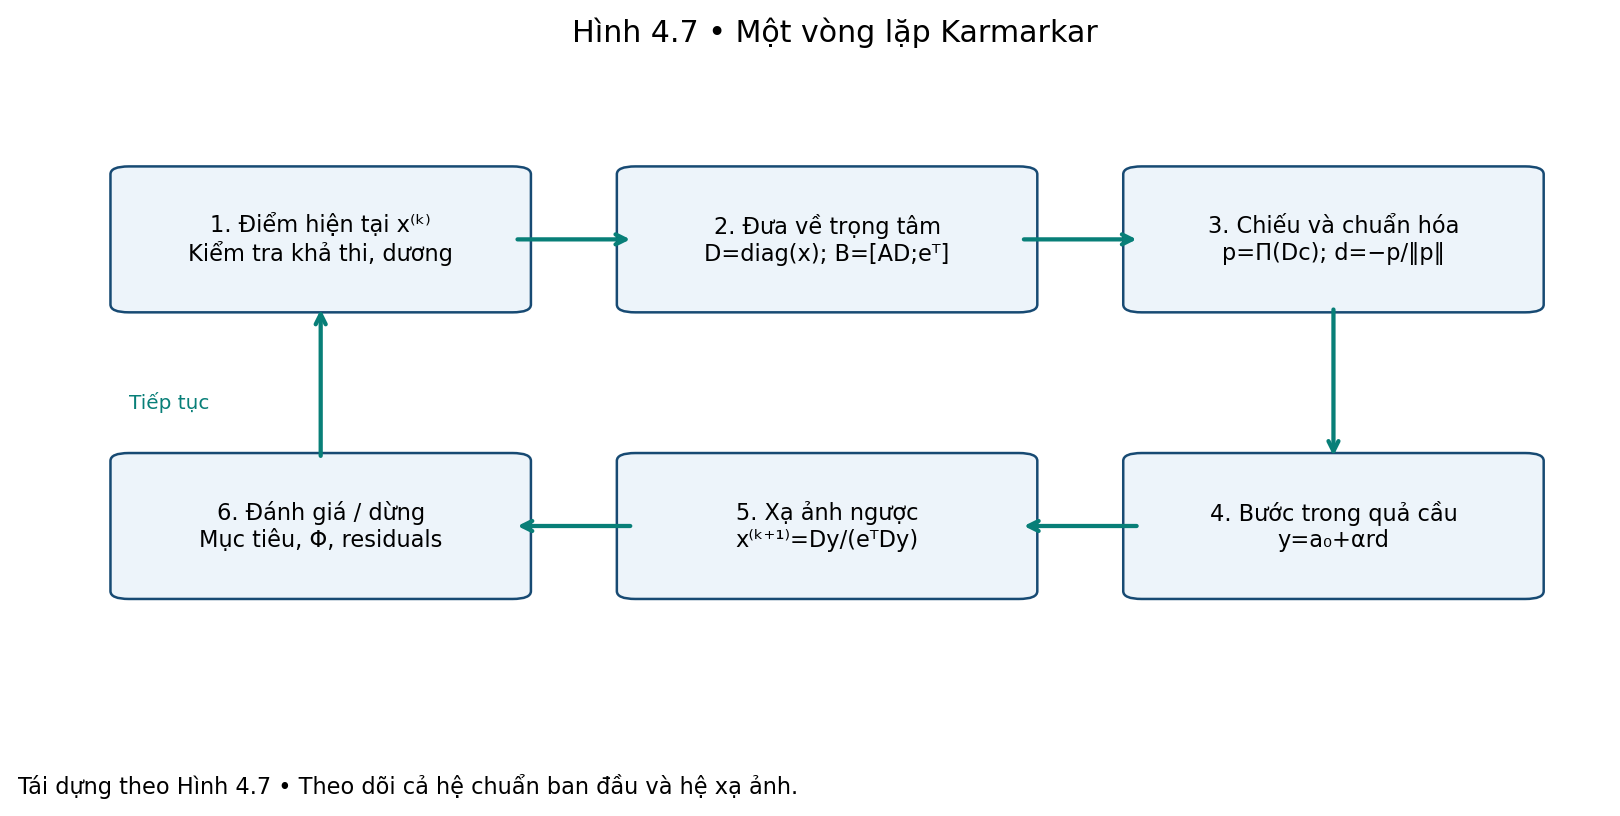

In [36]:
# NB36 | BC 4.3.4; Hình 4.7 | MasterSpec C10, section 5.2
show(plots.plot_figure_4_7(),'figure_4_7')


#### Kết luận dễ hiểu sau NB36

**Điều cần nhớ:** Vẽ sơ đồ luồng của một vòng lặp để bạn theo dõi thứ tự các bước mà không cần đọc code.

<details><summary>Ghi chú kỹ thuật — chỉ cần mở khi muốn xem sâu hơn</summary>

**Dấu hiệu kiểm tra:** Đánh giá xong mới quay lại vòng tiếp.

Năm thao tác hình học và sáu bước điều phối là hai cách mô tả cùng thuật toán; bước đánh giá/dừng thuộc bộ điều phối.

</details>

### NB37 · ✅ KIỂM TRA · 4.3.5

> **Vị trí trong tài liệu:** BC 4.3.5; MasterSpec C02/C08, §5.2 (NB37).

**Mục đích / Vì sao cần (nói ngắn gọn):** Phát hiện sớm kết quả sai bằng cách so với một điều kiện hoặc kết quả đã biết.

**Cách hiểu đơn giản:** Cho xem các lý do chương trình có thể dừng và nhấn mạnh rằng dừng gần đúng không đồng nghĩa với chứng minh tối ưu tuyệt đối.

**Loại nội dung:** Phần này xác nhận kết quả đã tính đúng hoặc phát hiện dữ liệu sai.

**Input — dữ liệu đưa vào (tên dùng trong code/PDF):** Ba bài/cấu hình.  
*Hiểu đơn giản:* Kết quả vừa tính cùng điều kiện đúng dùng làm mốc so sánh.

**Đang làm gì — máy sẽ xử lý:** Thử các trạng thái kết thúc.

**Output — kết quả nhận được (tên dùng trong code/PDF):** bảng status.  
*Hiểu đơn giản:* Sai số, bảng so sánh hoặc thông báo đạt/không đạt để biết bước trước có chạy đúng không.

**Input/Output:** đã được tách riêng ở hai dòng trên để dễ theo dõi.

**Nếu chỉ nhớ một ý:** Cho xem các lý do chương trình có thể dừng và nhấn mạnh rằng dừng gần đúng không đồng nghĩa với chứng minh tối ưu tuyệt đối.

<details><summary>Dấu hiệu kỹ thuật để kiểm tra — có thể bỏ qua ở lần đọc đầu</summary>

**Lý do kỹ thuật của bước này:** Tách không có hướng, không đủ ngân sách và dừng gần đúng.

**Cần nhìn kết quả nào:** Không có trạng thái OPTIMAL trong core.

</details>

🧑‍💻 **Nếu bạn không học code:** có thể bỏ qua ô code ngay bên dưới, xem kết quả rồi đọc phần kết luận.

In [37]:
# NB37 | BC 4.3.5 | MasterSpec C02/C08, section 5.2
no_move=CanonicalLP(np.array([[1.,-1.]]),np.array([0.,1.]),'singleton')
status_runs=[solve_karmarkar(no_move,config), source_run20, solve_karmarkar(problem,replace(config,epsilon=.05))]
display(pd.DataFrame([{'status':r0.status.value,'iterations':r0.iterations,'objective':r0.objective,'message':r0.message} for r0 in status_runs]))


,status,iterations,objective,message
0,no_projected_direction,0,0.500000,Projected direction is absent or numerically t...
1,max_iterations,20,0.001593,Maximum iterations reached without the request...
2,approx_tol_reached,11,0.038042,Canonical objective threshold reached; no exac...


#### Kết luận dễ hiểu sau NB37

**Điều cần nhớ:** Cho xem các lý do chương trình có thể dừng và nhấn mạnh rằng dừng gần đúng không đồng nghĩa với chứng minh tối ưu tuyệt đối.

<details><summary>Ghi chú kỹ thuật — chỉ cần mở khi muốn xem sâu hơn</summary>

**Dấu hiệu kiểm tra:** Không có trạng thái OPTIMAL trong core.

p=0, kernel rỗng hoặc p gần 0 không cho phép tự kết luận optimum 0. Đạt epsilon cũng chỉ là ngưỡng gần đúng trong ngữ cảnh đã xác minh.

</details>

## E. Theo dõi một ví dụ từ đầu đến cuối — BC 4.4

**Phần này giúp bạn hiểu:** Xem một điểm được cải thiện qua từng vòng cho tới khi tiến gần đỉnh tốt nhất. Phần này luôn đổi kết quả về hai biến gốc để bạn dễ nhìn trên hình.

Nếu gặp công thức khó, hãy đọc phần diễn giải bằng lời và nhìn hình/kết quả trước.

### NB38 · 📘 Ý TƯỞNG / THUẬT TOÁN · 4.4.1; (4.42)

> **Vị trí trong tài liệu:** BC 4.4.1; (4.42); MasterSpec C09, §5.2 (NB38).

**Mục đích / Vì sao cần (nói ngắn gọn):** Giải thích hoặc thực hiện một bước giúp Karmarkar tìm phương án tốt dần mà vẫn tuân thủ các điều kiện.

**Cách hiểu đơn giản:** Nhắc lại đề bài gốc bằng lời và bảng trước khi thực hiện các phép đổi biến.

**Loại nội dung:** Phần này giúp hiểu thuật toán làm gì. Code chỉ là cách máy thực hiện ý tưởng đó.

**Input — dữ liệu đưa vào (tên dùng trong code/PDF):** Mô hình.  
*Hiểu đơn giản:* Bài toán, điểm hiện tại và các nút điều chỉnh mà bước thuật toán này cần.

**Đang làm gì — máy sẽ xử lý:** Hiển thị đề bài gốc.

**Output — kết quả nhận được (tên dùng trong code/PDF):** mục tiêu và ràng buộc.  
*Hiểu đơn giản:* Một hướng đi, điểm mới hoặc các con số trung gian để tiếp tục vòng Karmarkar.

**Input/Output:** đã được tách riêng ở hai dòng trên để dễ theo dõi.

**Nếu chỉ nhớ một ý:** Nhắc lại đề bài gốc bằng lời và bảng trước khi thực hiện các phép đổi biến.

<details><summary>Dấu hiệu kỹ thuật để kiểm tra — có thể bỏ qua ở lần đọc đầu</summary>

**Lý do kỹ thuật của bước này:** Đọc bài trước khi xem kết quả chuẩn hóa.

**Cần nhìn kết quả nào:** min z=2−x1, x1+x2≤2, x1,x2≥0.

</details>

🧑‍💻 **Nếu bạn không học code:** có thể bỏ qua ô code ngay bên dưới, xem kết quả rồi đọc phần kết luận.

In [38]:
# NB38 | BC 4.4.1; (4.42) | MasterSpec C09, section 5.2
display(pd.DataFrame({'Thành phần':['Mục tiêu','Ràng buộc 1','Ràng buộc 2,3'],'Biểu thức':['min z=2−x1','x1+x2≤2','x1≥0; x2≥0']}))


,Thành phần,Biểu thức
0,Mục tiêu,min z=2−x1
1,Ràng buộc 1,x1+x2≤2
2,"Ràng buộc 2,3",x1≥0; x2≥0


#### Kết luận dễ hiểu sau NB38

**Điều cần nhớ:** Nhắc lại đề bài gốc bằng lời và bảng trước khi thực hiện các phép đổi biến.

<details><summary>Ghi chú kỹ thuật — chỉ cần mở khi muốn xem sâu hơn</summary>

**Dấu hiệu kiểm tra:** min z=2−x1, x1+x2≤2, x1,x2≥0.

Miền compact nên có nghiệm tối ưu. Hình học cho nghiệm tại A, làm mốc kiểm tra thuật toán.

</details>

### NB39 · 🎨 VẼ HÌNH · 4.4.2; hình không đánh số

> **Vị trí trong tài liệu:** BC 4.4.2; hình không đánh số; MasterSpec C10, §5.2 (NB39).

**Mục đích / Vì sao cần (nói ngắn gọn):** Biến các con số thành hình để người đọc nhìn ra ý chính mà không phải đọc công thức.

**Cách hiểu đơn giản:** Vẽ tam giác nghiệm để thấy trực quan các phương án được phép và đỉnh tốt nhất.

**Loại nội dung:** Phần này dùng code để tạo hình minh họa. Bạn có thể bỏ qua code và xem hình.

**Input — dữ liệu đưa vào (tên dùng trong code/PDF):** Miền OAB.  
*Hiểu đơn giản:* Các điểm hoặc số liệu đã được tính ở bước trước; chúng được đưa vào để đặt lên hình.

**Đang làm gì — máy sẽ xử lý:** Vẽ ba đường biên và chiều nửa mặt phẳng.

**Output — kết quả nhận được (tên dùng trong code/PDF):** geometry_4_4_2.  
*Hiểu đơn giản:* Một hình minh họa. Bạn chỉ cần quan sát hình và đọc chú thích, không cần đọc lệnh vẽ.

**Input/Output:** đã được tách riêng ở hai dòng trên để dễ theo dõi.

**Nếu chỉ nhớ một ý:** Vẽ tam giác nghiệm để thấy trực quan các phương án được phép và đỉnh tốt nhất.

<details><summary>Dấu hiệu kỹ thuật để kiểm tra — có thể bỏ qua ở lần đọc đầu</summary>

**Lý do kỹ thuật của bước này:** Tái hiện cả hình không mang số 4.x.

**Cần nhìn kết quả nào:** A=(2,0) là đỉnh tối ưu.

</details>

🧑‍💻 **Nếu bạn không học code:** có thể bỏ qua ô code ngay bên dưới, xem kết quả rồi đọc phần kết luận.

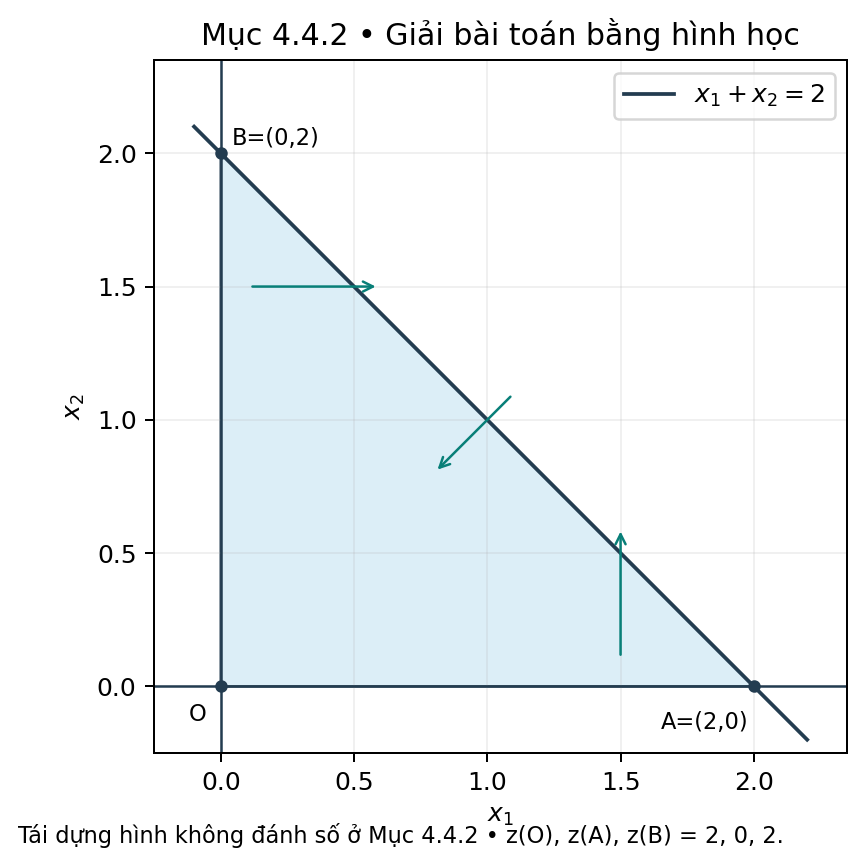

In [39]:
# NB39 | BC 4.4.2; hình không đánh số | MasterSpec C10, section 5.2
show(plots.plot_original_geometry(),'geometry_4_4_2')


#### Kết luận dễ hiểu sau NB39

**Điều cần nhớ:** Vẽ tam giác nghiệm để thấy trực quan các phương án được phép và đỉnh tốt nhất.

<details><summary>Ghi chú kỹ thuật — chỉ cần mở khi muốn xem sâu hơn</summary>

**Dấu hiệu kiểm tra:** A=(2,0) là đỉnh tối ưu.

Ba mũi tên chọn phía thỏa từng ràng buộc; giao ba phía cho miền tam giác.

</details>

### NB40 · 🛠️ CÀI ĐẶT / TỔ CHỨC · 4.4.2; Bảng 4.1; (4.43)

> **Vị trí trong tài liệu:** BC 4.4.2; Bảng 4.1; (4.43); MasterSpec C09/C12, §5.2 (NB40).

**Mục đích / Vì sao cần (nói ngắn gọn):** Chuẩn bị môi trường, dữ liệu hoặc nơi lưu kết quả để các phần sau chạy ổn định và có thể kiểm tra lại.

**Cách hiểu đơn giản:** Lưu bảng giá trị ở ba đỉnh; đây là lời giải hình học đơn giản dùng để đối chiếu với thuật toán.

**Loại nội dung:** Phần này phục vụ chương trình và việc lưu kết quả, không phải bước toán học của Karmarkar.

**Input — dữ liệu đưa vào (tên dùng trong code/PDF):** vertices.  
*Hiểu đơn giản:* File, thư viện hoặc tùy chọn chương trình cần có sẵn trước khi tính toán.

**Đang làm gì — máy sẽ xử lý:** Xuất bảng đỉnh.

**Output — kết quả nhận được (tên dùng trong code/PDF):** table_4_1_vertices.csv.  
*Hiểu đơn giản:* Một bảng, thư mục hoặc thông báo xác nhận rằng phần chuẩn bị đã hoàn tất.

**Input/Output:** đã được tách riêng ở hai dòng trên để dễ theo dõi.

**Nếu chỉ nhớ một ý:** Lưu bảng giá trị ở ba đỉnh; đây là lời giải hình học đơn giản dùng để đối chiếu với thuật toán.

<details><summary>Dấu hiệu kỹ thuật để kiểm tra — có thể bỏ qua ở lần đọc đầu</summary>

**Lý do kỹ thuật của bước này:** Giữ bảng gốc tách khỏi dữ liệu thực nghiệm.

**Cần nhìn kết quả nào:** Giá trị z=2,0,2.

</details>

🧑‍💻 **Nếu bạn không học code:** có thể bỏ qua ô code ngay bên dưới, xem kết quả rồi đọc phần kết luận.

In [40]:
# NB40 | BC 4.4.2; Bảng 4.1; (4.43) | MasterSpec C09/C12, section 5.2
display(vertices)
vertices.to_csv(OUT/'tables/table_4_1_vertices.csv',index=False,encoding='utf-8-sig')


,vertex,x1,x2,z
0,O,0.0,0.0,2.0
1,A,2.0,0.0,0.0
2,B,0.0,2.0,2.0


#### Kết luận dễ hiểu sau NB40

**Điều cần nhớ:** Lưu bảng giá trị ở ba đỉnh; đây là lời giải hình học đơn giản dùng để đối chiếu với thuật toán.

<details><summary>Ghi chú kỹ thuật — chỉ cần mở khi muốn xem sâu hơn</summary>

**Dấu hiệu kiểm tra:** Giá trị z=2,0,2.

Chỉ A có giá trị 0; hàm tuyến tính đạt cực tiểu trên một mặt, ở đây mặt tối ưu chỉ có một đỉnh.

</details>

### NB41 · 📘 Ý TƯỞNG / THUẬT TOÁN · 4.4.3; (4.44)

> **Vị trí trong tài liệu:** BC 4.4.3; (4.44); MasterSpec C09, §5.2 (NB41).

**Mục đích / Vì sao cần (nói ngắn gọn):** Giải thích hoặc thực hiện một bước giúp Karmarkar tìm phương án tốt dần mà vẫn tuân thủ các điều kiện.

**Cách hiểu đơn giản:** Chuyển một điểm cụ thể sang ba trọng số và kiểm tra ba trọng số cộng lại bằng 1.

**Loại nội dung:** Phần này giúp hiểu thuật toán làm gì. Code chỉ là cách máy thực hiện ý tưởng đó.

**Input — dữ liệu đưa vào (tên dùng trong code/PDF):** (x1,x2)=(2/3,2/3).  
*Hiểu đơn giản:* Bài toán, điểm hiện tại và các nút điều chỉnh mà bước thuật toán này cần.

**Đang làm gì — máy sẽ xử lý:** Tính biến bù và tọa độ u.

**Output — kết quả nhận được (tên dùng trong code/PDF):** s,u.  
*Hiểu đơn giản:* Một hướng đi, điểm mới hoặc các con số trung gian để tiếp tục vòng Karmarkar.

**Input/Output:** đã được tách riêng ở hai dòng trên để dễ theo dõi.

**Nếu chỉ nhớ một ý:** Chuyển một điểm cụ thể sang ba trọng số và kiểm tra ba trọng số cộng lại bằng 1.

<details><summary>Dấu hiệu kỹ thuật để kiểm tra — có thể bỏ qua ở lần đọc đầu</summary>

**Lý do kỹ thuật của bước này:** Bảo toàn miền qua chuẩn hóa.

**Cần nhìn kết quả nào:** s=2/3, u=e/3.

</details>

🧑‍💻 **Nếu bạn không học code:** có thể bỏ qua ô code ngay bên dưới, xem kết quả rồi đọc phần kết luận.

In [41]:
# NB41 | BC 4.4.3; (4.44) | MasterSpec C09, section 5.2
s=2-2/3-2/3
u_demo=original_to_u(2/3,2/3)
display({'s':s,'u':u_demo,'sum(u)':u_demo.sum()})


{'s': 0.6666666666666669,
 'u': array([0.33333333, 0.33333333, 0.33333333]),
 'sum(u)': np.float64(1.0)}

#### Kết luận dễ hiểu sau NB41

**Điều cần nhớ:** Chuyển một điểm cụ thể sang ba trọng số và kiểm tra ba trọng số cộng lại bằng 1.

<details><summary>Ghi chú kỹ thuật — chỉ cần mở khi muốn xem sâu hơn</summary>

**Dấu hiệu kiểm tra:** s=2/3, u=e/3.

Mỗi tọa độ u là trọng số của một đỉnh đơn giác; u3 ứng với đỉnh O của miền gốc.

</details>

### NB42 · ✅ KIỂM TRA · 4.4.3; (4.45)–(4.46)

> **Vị trí trong tài liệu:** BC 4.4.3; (4.45)–(4.46); MasterSpec C09, §5.2 (NB42).

**Mục đích / Vì sao cần (nói ngắn gọn):** Phát hiện sớm kết quả sai bằng cách so với một điều kiện hoặc kết quả đã biết.

**Cách hiểu đơn giản:** Xác nhận mục tiêu trong bài toán mới chỉ khác mục tiêu gốc bởi hệ số 2, nên nghiệm tốt nhất không thay đổi.

**Loại nội dung:** Phần này xác nhận kết quả đã tính đúng hoặc phát hiện dữ liệu sai.

**Input — dữ liệu đưa vào (tên dùng trong code/PDF):** Ba điểm gốc.  
*Hiểu đơn giản:* Kết quả vừa tính cùng điều kiện đúng dùng làm mốc so sánh.

**Đang làm gì — máy sẽ xử lý:** Đối chiếu z=2w tại ba điểm.

**Output — kết quả nhận được (tên dùng trong code/PDF):** z,w,2w.  
*Hiểu đơn giản:* Sai số, bảng so sánh hoặc thông báo đạt/không đạt để biết bước trước có chạy đúng không.

**Input/Output:** đã được tách riêng ở hai dòng trên để dễ theo dõi.

**Nếu chỉ nhớ một ý:** Xác nhận mục tiêu trong bài toán mới chỉ khác mục tiêu gốc bởi hệ số 2, nên nghiệm tốt nhất không thay đổi.

<details><summary>Dấu hiệu kỹ thuật để kiểm tra — có thể bỏ qua ở lần đọc đầu</summary>

**Lý do kỹ thuật của bước này:** Không bỏ mất hệ số 2 khi so báo cáo.

**Cần nhìn kết quả nào:** z và 2w trùng nhau.

</details>

🧑‍💻 **Nếu bạn không học code:** có thể bỏ qua ô code ngay bên dưới, xem kết quả rồi đọc phần kết luận.

In [42]:
# NB42 | BC 4.4.3; (4.45)–(4.46) | MasterSpec C09, section 5.2
display(pd.DataFrame([{'x':x,'z':2-x[0],'w':problem.c@original_to_u(*x),'2w':2*problem.c@original_to_u(*x)} for x in points]))


,x,z,w,2w
0,"(0.0, 0.0)",2.0,1.00,2.0
1,"(2.0, 0.0)",0.0,0.00,0.0
2,"(0.5, 0.5)",1.5,0.75,1.5


#### Kết luận dễ hiểu sau NB42

**Điều cần nhớ:** Xác nhận mục tiêu trong bài toán mới chỉ khác mục tiêu gốc bởi hệ số 2, nên nghiệm tốt nhất không thay đổi.

<details><summary>Ghi chú kỹ thuật — chỉ cần mở khi muốn xem sâu hơn</summary>

**Dấu hiệu kiểm tra:** z và 2w trùng nhau.

Nhân mục tiêu với hằng số dương giữ tập nghiệm tối ưu. Ngưỡng epsilon của solver áp dụng cho w; công thức (4.57) trong báo cáo áp dụng cho z.

</details>

### NB43 · 📘 Ý TƯỞNG / THUẬT TOÁN · 4.4.4; (4.47)–(4.48)

> **Vị trí trong tài liệu:** BC 4.4.4; (4.47)–(4.48); MasterSpec C03/C05, §5.2 (NB43).

**Mục đích / Vì sao cần (nói ngắn gọn):** Giải thích hoặc thực hiện một bước giúp Karmarkar tìm phương án tốt dần mà vẫn tuân thủ các điều kiện.

**Cách hiểu đơn giản:** Tạo công cụ chiếu riêng cho ví dụ ba tọa độ và kiểm tra nó thật sự giữ hướng trong mặt phẳng được phép.

**Loại nội dung:** Phần này giúp hiểu thuật toán làm gì. Code chỉ là cách máy thực hiện ý tưởng đó.

**Input — dữ liệu đưa vào (tên dùng trong code/PDF):** e.  
*Hiểu đơn giản:* Bài toán, điểm hiện tại và các nút điều chỉnh mà bước thuật toán này cần.

**Đang làm gì — máy sẽ xử lý:** Lập ma trận chiếu cụ thể 3×3.

**Output — kết quả nhận được (tên dùng trong code/PDF):** P3=I−eeᵀ/3.  
*Hiểu đơn giản:* Một hướng đi, điểm mới hoặc các con số trung gian để tiếp tục vòng Karmarkar.

**Input/Output:** đã được tách riêng ở hai dòng trên để dễ theo dõi.

**Nếu chỉ nhớ một ý:** Tạo công cụ chiếu riêng cho ví dụ ba tọa độ và kiểm tra nó thật sự giữ hướng trong mặt phẳng được phép.

<details><summary>Dấu hiệu kỹ thuật để kiểm tra — có thể bỏ qua ở lần đọc đầu</summary>

**Lý do kỹ thuật của bước này:** Đối chiếu phép chiếu tổng quát với công thức của ví dụ.

**Cần nhìn kết quả nào:** P3²=P3, P3e=0.

</details>

🧑‍💻 **Nếu bạn không học code:** có thể bỏ qua ô code ngay bên dưới, xem kết quả rồi đọc phần kết luận.

In [43]:
# NB43 | BC 4.4.4; (4.47)–(4.48) | MasterSpec C03/C05, section 5.2
P3=np.eye(3)-np.ones((3,3))/3
display({'a0':center,'alpha':config.alpha,'r':r,'P3':P3,'idempotence_error':np.linalg.norm(P3@P3-P3)})


{'a0': array([0.33333333, 0.33333333, 0.33333333]),
 'alpha': 0.25,
 'r': np.float64(0.4082482904638631),
 'P3': array([[ 0.66666667, -0.33333333, -0.33333333],
        [-0.33333333,  0.66666667, -0.33333333],
        [-0.33333333, -0.33333333,  0.66666667]]),
 'idempotence_error': np.float64(1.7554167342883506e-16)}

#### Kết luận dễ hiểu sau NB43

**Điều cần nhớ:** Tạo công cụ chiếu riêng cho ví dụ ba tọa độ và kiểm tra nó thật sự giữ hướng trong mặt phẳng được phép.

<details><summary>Ghi chú kỹ thuật — chỉ cần mở khi muốn xem sâu hơn</summary>

**Dấu hiệu kiểm tra:** P3²=P3, P3e=0.

Đây là trường hợp riêng B=eᵀ. Không dùng riêng P3 thay cho SVD khi A có ràng buộc bổ sung.

</details>

### NB44 · 📘 Ý TƯỞNG / THUẬT TOÁN · 4.4.5; (4.49)–(4.51)

> **Vị trí trong tài liệu:** BC 4.4.5; (4.49)–(4.51); MasterSpec C07/C09, §5.2 (NB44).

**Mục đích / Vì sao cần (nói ngắn gọn):** Giải thích hoặc thực hiện một bước giúp Karmarkar tìm phương án tốt dần mà vẫn tuân thủ các điều kiện.

**Cách hiểu đơn giản:** Chạy vòng đầu tiên từ tâm và in đầy đủ các bước trung gian để đối chiếu với phép tính trong PDF.

**Loại nội dung:** Phần này giúp hiểu thuật toán làm gì. Code chỉ là cách máy thực hiện ý tưởng đó.

**Input — dữ liệu đưa vào (tên dùng trong code/PDF):** u0=e/3.  
*Hiểu đơn giản:* Bài toán, điểm hiện tại và các nút điều chỉnh mà bước thuật toán này cần.

**Đang làm gì — máy sẽ xử lý:** Chạy vòng k=0 với đầy đủ ma trận.

**Output — kết quả nhận được (tên dùng trong code/PDF):** StepRecord.  
*Hiểu đơn giản:* Một hướng đi, điểm mới hoặc các con số trung gian để tiếp tục vòng Karmarkar.

**Input/Output:** đã được tách riêng ở hai dòng trên để dễ theo dõi.

**Nếu chỉ nhớ một ý:** Chạy vòng đầu tiên từ tâm và in đầy đủ các bước trung gian để đối chiếu với phép tính trong PDF.

<details><summary>Dấu hiệu kỹ thuật để kiểm tra — có thể bỏ qua ở lần đọc đầu</summary>

**Lý do kỹ thuật của bước này:** Tái lập p0,d0,y0,u1 bằng code thực.

**Cần nhìn kết quả nào:** p0=(−2,1,1)/9; u1=(10,7,7)/24.

</details>

🧑‍💻 **Nếu bạn không học code:** có thể bỏ qua ô code ngay bên dưới, xem kết quả rồi đọc phần kết luận.

In [44]:
# NB44 | BC 4.4.5; (4.49)–(4.51) | MasterSpec C07/C09, section 5.2
step0=karmarkar_step(problem,center,config,k=0)
display(show_step_table(step0))
np.testing.assert_allclose(step0.x_after,np.array([10,7,7])/24,atol=1e-12)


,Đại lượng,Giá trị
0,k,0
1,x_before,[0.333333333 0.333333333 0.333333333]
2,D,[[0.333333333 0. 0. ]\n [0. ...
3,B,[[1. 1. 1.]]
4,v,[0. 0.333333333 0.333333333]
5,p,[-0.222222222 0.111111111 0.111111111]
6,d,[ 0.816496581 -0.40824829 -0.40824829 ]
7,y,[0.416666667 0.291666667 0.291666667]
8,x_after,[0.416666667 0.291666667 0.291666667]
9,f_before,0.666667


#### Kết luận dễ hiểu sau NB44

**Điều cần nhớ:** Chạy vòng đầu tiên từ tâm và in đầy đủ các bước trung gian để đối chiếu với phép tính trong PDF.

<details><summary>Ghi chú kỹ thuật — chỉ cần mở khi muốn xem sâu hơn</summary>

**Dấu hiệu kiểm tra:** p0=(−2,1,1)/9; u1=(10,7,7)/24.

u1 tăng, u2 và u3 giảm; cả ba vẫn dương. D0=I/3 khiến xạ ảnh ngược không thay các con số của y0.

</details>

### NB45 · 📘 Ý TƯỞNG / THUẬT TOÁN · 4.4.5; sau (4.51)

> **Vị trí trong tài liệu:** BC 4.4.5; sau (4.51); MasterSpec C09, §5.2 (NB45).

**Mục đích / Vì sao cần (nói ngắn gọn):** Giải thích hoặc thực hiện một bước giúp Karmarkar tìm phương án tốt dần mà vẫn tuân thủ các điều kiện.

**Cách hiểu đơn giản:** Đổi kết quả vòng đầu về hai biến gốc để thấy giá trị mục tiêu đã giảm.

**Loại nội dung:** Phần này giúp hiểu thuật toán làm gì. Code chỉ là cách máy thực hiện ý tưởng đó.

**Input — dữ liệu đưa vào (tên dùng trong code/PDF):** u1.  
*Hiểu đơn giản:* Bài toán, điểm hiện tại và các nút điều chỉnh mà bước thuật toán này cần.

**Đang làm gì — máy sẽ xử lý:** Đổi lại tọa độ gốc sau vòng 1.

**Output — kết quả nhận được (tên dùng trong code/PDF):** (x1,x2),z.  
*Hiểu đơn giản:* Một hướng đi, điểm mới hoặc các con số trung gian để tiếp tục vòng Karmarkar.

**Input/Output:** đã được tách riêng ở hai dòng trên để dễ theo dõi.

**Nếu chỉ nhớ một ý:** Đổi kết quả vòng đầu về hai biến gốc để thấy giá trị mục tiêu đã giảm.

<details><summary>Dấu hiệu kỹ thuật để kiểm tra — có thể bỏ qua ở lần đọc đầu</summary>

**Lý do kỹ thuật của bước này:** Kiểm kết quả z và vị trí trên miền OAB.

**Cần nhìn kết quả nào:** (5/6,7/12), z=7/6.

</details>

🧑‍💻 **Nếu bạn không học code:** có thể bỏ qua ô code ngay bên dưới, xem kết quả rồi đọc phần kết luận.

In [45]:
# NB45 | BC 4.4.5; sau (4.51) | MasterSpec C09, section 5.2
display({'x_original':u_to_original(step0.x_after),'z':2*problem.c@step0.x_after})


{'x_original': array([0.83333333, 0.58333333]),
 'z': np.float64(1.1666666666666667)}

#### Kết luận dễ hiểu sau NB45

**Điều cần nhớ:** Đổi kết quả vòng đầu về hai biến gốc để thấy giá trị mục tiêu đã giảm.

<details><summary>Ghi chú kỹ thuật — chỉ cần mở khi muốn xem sâu hơn</summary>

**Dấu hiệu kiểm tra:** (5/6,7/12), z=7/6.

z ban đầu 4/3 giảm thành 7/6; không nhầm w=7/12 với mục tiêu gốc z.

</details>

### NB46 · 📘 Ý TƯỞNG / THUẬT TOÁN · 4.4.6; (4.52)

> **Vị trí trong tài liệu:** BC 4.4.6; (4.52); MasterSpec C07/C09, §5.2 (NB46).

**Mục đích / Vì sao cần (nói ngắn gọn):** Giải thích hoặc thực hiện một bước giúp Karmarkar tìm phương án tốt dần mà vẫn tuân thủ các điều kiện.

**Cách hiểu đơn giản:** Chạy vòng thứ hai từ điểm mới; lần này điểm làm mốc không còn ở tâm nên phép đổi ngược bắt đầu có tác dụng rõ.

**Loại nội dung:** Phần này giúp hiểu thuật toán làm gì. Code chỉ là cách máy thực hiện ý tưởng đó.

**Input — dữ liệu đưa vào (tên dùng trong code/PDF):** step0.x_after.  
*Hiểu đơn giản:* Bài toán, điểm hiện tại và các nút điều chỉnh mà bước thuật toán này cần.

**Đang làm gì — máy sẽ xử lý:** Tính vòng k=1 từ u1 thực.

**Output — kết quả nhận được (tên dùng trong code/PDF):** step1.  
*Hiểu đơn giản:* Một hướng đi, điểm mới hoặc các con số trung gian để tiếp tục vòng Karmarkar.

**Input/Output:** đã được tách riêng ở hai dòng trên để dễ theo dõi.

**Nếu chỉ nhớ một ý:** Chạy vòng thứ hai từ điểm mới; lần này điểm làm mốc không còn ở tâm nên phép đổi ngược bắt đầu có tác dụng rõ.

<details><summary>Dấu hiệu kỹ thuật để kiểm tra — có thể bỏ qua ở lần đọc đầu</summary>

**Lý do kỹ thuật của bước này:** Mốc xạ ảnh mới đã lệch trọng tâm.

**Cần nhìn kết quả nào:** p1=(7/72)(−2,1,1).

</details>

🧑‍💻 **Nếu bạn không học code:** có thể bỏ qua ô code ngay bên dưới, xem kết quả rồi đọc phần kết luận.

In [46]:
# NB46 | BC 4.4.6; (4.52) | MasterSpec C07/C09, section 5.2
step1=karmarkar_step(problem,step0.x_after,config,k=1)
display(show_step_table(step1))
np.testing.assert_allclose(step1.p,7*np.array([-2,1,1])/72,atol=1e-12)


,Đại lượng,Giá trị
0,k,1
1,x_before,[0.416666667 0.291666667 0.291666667]
2,D,[[0.416666667 0. 0. ]\n [0. ...
3,B,[[1. 1. 1.]]
4,v,[0. 0.291666667 0.291666667]
5,p,[-0.194444444 0.097222222 0.097222222]
6,d,[ 0.816496581 -0.40824829 -0.40824829 ]
7,y,[0.416666667 0.291666667 0.291666667]
8,x_after,[0.505050505 0.247474747 0.247474747]
9,f_before,0.583333


#### Kết luận dễ hiểu sau NB46

**Điều cần nhớ:** Chạy vòng thứ hai từ điểm mới; lần này điểm làm mốc không còn ở tâm nên phép đổi ngược bắt đầu có tác dụng rõ.

<details><summary>Ghi chú kỹ thuật — chỉ cần mở khi muốn xem sâu hơn</summary>

**Dấu hiệu kiểm tra:** p1=(7/72)(−2,1,1).

D1 không còn là bội của ma trận đơn vị; bỏ phép đổi ngược từ vòng này sẽ cho kết quả sai.

</details>

### NB47 · 📘 Ý TƯỞNG / THUẬT TOÁN · 4.4.6; (4.52)

> **Vị trí trong tài liệu:** BC 4.4.6; (4.52); MasterSpec C04/C07/C09, §5.2 (NB47).

**Mục đích / Vì sao cần (nói ngắn gọn):** Giải thích hoặc thực hiện một bước giúp Karmarkar tìm phương án tốt dần mà vẫn tuân thủ các điều kiện.

**Cách hiểu đơn giản:** So điểm trong hệ phụ với điểm sau khi đổi về hệ gốc để thấy chúng không còn là cùng một dãy số.

**Loại nội dung:** Phần này giúp hiểu thuật toán làm gì. Code chỉ là cách máy thực hiện ý tưởng đó.

**Input — dữ liệu đưa vào (tên dùng trong code/PDF):** Mốc u1 và y1.  
*Hiểu đơn giản:* Bài toán, điểm hiện tại và các nút điều chỉnh mà bước thuật toán này cần.

**Đang làm gì — máy sẽ xử lý:** In y1,D1y1 và u2 sau chuẩn hóa nghịch đảo.

**Output — kết quả nhận được (tên dùng trong code/PDF):** u2.  
*Hiểu đơn giản:* Một hướng đi, điểm mới hoặc các con số trung gian để tiếp tục vòng Karmarkar.

**Input/Output:** đã được tách riêng ở hai dòng trên để dễ theo dõi.

**Nếu chỉ nhớ một ý:** So điểm trong hệ phụ với điểm sau khi đổi về hệ gốc để thấy chúng không còn là cùng một dãy số.

<details><summary>Dấu hiệu kỹ thuật để kiểm tra — có thể bỏ qua ở lần đọc đầu</summary>

**Lý do kỹ thuật của bước này:** Thấy cùng số y nhưng khác hệ tọa độ.

**Cần nhìn kết quả nào:** u2=(100,49,49)/198, khác y1.

</details>

🧑‍💻 **Nếu bạn không học code:** có thể bỏ qua ô code ngay bên dưới, xem kết quả rồi đọc phần kết luận.

In [47]:
# NB47 | BC 4.4.6; (4.52) | MasterSpec C04/C07/C09, section 5.2
display({'y1':step1.y,'D1@y1':step1.D@step1.y,'u2':step1.x_after,'z2':2*problem.c@step1.x_after})
np.testing.assert_allclose(step1.x_after,np.array([100,49,49])/198,atol=1e-12)


{'y1': array([0.41666667, 0.29166667, 0.29166667]),
 'D1@y1': array([0.17361111, 0.08506944, 0.08506944]),
 'u2': array([0.50505051, 0.24747475, 0.24747475]),
 'z2': np.float64(0.98989898989899)}

#### Kết luận dễ hiểu sau NB47

**Điều cần nhớ:** So điểm trong hệ phụ với điểm sau khi đổi về hệ gốc để thấy chúng không còn là cùng một dãy số.

<details><summary>Ghi chú kỹ thuật — chỉ cần mở khi muốn xem sâu hơn</summary>

**Dấu hiệu kiểm tra:** u2=(100,49,49)/198, khác y1.

Nhân theo mốc rồi chia tổng cho u2; y1 trùng số với y0 chỉ vì tính đối xứng của ví dụ, không phải nghiệm gốc đứng yên.

</details>

### NB48 · 📘 Ý TƯỞNG / THUẬT TOÁN · 4.4.7; (4.53)

> **Vị trí trong tài liệu:** BC 4.4.7; (4.53); MasterSpec C07/C09, §5.2 (NB48).

**Mục đích / Vì sao cần (nói ngắn gọn):** Giải thích hoặc thực hiện một bước giúp Karmarkar tìm phương án tốt dần mà vẫn tuân thủ các điều kiện.

**Cách hiểu đơn giản:** Chạy vòng thứ ba và kiểm tra kết quả tiếp tục tiến gần đỉnh tốt nhất.

**Loại nội dung:** Phần này giúp hiểu thuật toán làm gì. Code chỉ là cách máy thực hiện ý tưởng đó.

**Input — dữ liệu đưa vào (tên dùng trong code/PDF):** u2 thực.  
*Hiểu đơn giản:* Bài toán, điểm hiện tại và các nút điều chỉnh mà bước thuật toán này cần.

**Đang làm gì — máy sẽ xử lý:** Chạy vòng k=2.

**Output — kết quả nhận được (tên dùng trong code/PDF):** step2,u3,z3.  
*Hiểu đơn giản:* Một hướng đi, điểm mới hoặc các con số trung gian để tiếp tục vòng Karmarkar.

**Input/Output:** đã được tách riêng ở hai dòng trên để dễ theo dõi.

**Nếu chỉ nhớ một ý:** Chạy vòng thứ ba và kiểm tra kết quả tiếp tục tiến gần đỉnh tốt nhất.

<details><summary>Dấu hiệu kỹ thuật để kiểm tra — có thể bỏ qua ở lần đọc đầu</summary>

**Lý do kỹ thuật của bước này:** Hoàn tất ba bước tính tay của nguồn.

**Cần nhìn kết quả nào:** u3=(1000,343,343)/1686; z3=686/843.

</details>

🧑‍💻 **Nếu bạn không học code:** có thể bỏ qua ô code ngay bên dưới, xem kết quả rồi đọc phần kết luận.

In [48]:
# NB48 | BC 4.4.7; (4.53) | MasterSpec C07/C09, section 5.2
step2=karmarkar_step(problem,step1.x_after,config,k=2)
display(show_step_table(step2))
np.testing.assert_allclose(step2.x_after,np.array([1000,343,343])/1686,atol=1e-12)


,Đại lượng,Giá trị
0,k,2
1,x_before,[0.505050505 0.247474747 0.247474747]
2,D,[[0.505050505 0. 0. ]\n [0. ...
3,B,[[1. 1. 1.]]
4,v,[0. 0.247474747 0.247474747]
5,p,[-0.164983165 0.082491582 0.082491582]
6,d,[ 0.816496581 -0.40824829 -0.40824829 ]
7,y,[0.416666667 0.291666667 0.291666667]
8,x_after,[0.59311981 0.203440095 0.203440095]
9,f_before,0.494949


#### Kết luận dễ hiểu sau NB48

**Điều cần nhớ:** Chạy vòng thứ ba và kiểm tra kết quả tiếp tục tiến gần đỉnh tốt nhất.

<details><summary>Ghi chú kỹ thuật — chỉ cần mở khi muốn xem sâu hơn</summary>

**Dấu hiệu kiểm tra:** u3=(1000,343,343)/1686; z3=686/843.

Hướng chuẩn hóa vẫn (2,−1,−1)/√6 trong ví dụ đối xứng. Không suy ra hướng bất biến cho LP bất kỳ.

</details>

### NB49 · 📘 Ý TƯỞNG / THUẬT TOÁN · 4.4.8; (4.54)–(4.55)

> **Vị trí trong tài liệu:** BC 4.4.8; (4.54)–(4.55); MasterSpec C09, §5.2 (NB49).

**Mục đích / Vì sao cần (nói ngắn gọn):** Giải thích hoặc thực hiện một bước giúp Karmarkar tìm phương án tốt dần mà vẫn tuân thủ các điều kiện.

**Cách hiểu đơn giản:** Dùng công thức riêng của ví dụ để tính nhanh vị trí ở bất kỳ vòng nào; công thức này chỉ dùng để kiểm tra solver.

**Loại nội dung:** Phần này giúp hiểu thuật toán làm gì. Code chỉ là cách máy thực hiện ý tưởng đó.

**Input — dữ liệu đưa vào (tên dùng trong code/PDF):** t=(0.7)^k.  
*Hiểu đơn giản:* Bài toán, điểm hiện tại và các nút điều chỉnh mà bước thuật toán này cần.

**Đang làm gì — máy sẽ xử lý:** Tính nghiệm đóng theo k bằng dạng ổn định.

**Output — kết quả nhận được (tên dùng trong code/PDF):** u=(1,t,t)/(1+2t).  
*Hiểu đơn giản:* Một hướng đi, điểm mới hoặc các con số trung gian để tiếp tục vòng Karmarkar.

**Input/Output:** đã được tách riêng ở hai dòng trên để dễ theo dõi.

**Nếu chỉ nhớ một ý:** Dùng công thức riêng của ví dụ để tính nhanh vị trí ở bất kỳ vòng nào; công thức này chỉ dùng để kiểm tra solver.

<details><summary>Dấu hiệu kỹ thuật để kiểm tra — có thể bỏ qua ở lần đọc đầu</summary>

**Lý do kỹ thuật của bước này:** Tránh tràn số 10^k khi k lớn.

**Cần nhìn kết quả nào:** Các k=0,1,2,3,10,20.

</details>

🧑‍💻 **Nếu bạn không học code:** có thể bỏ qua ô code ngay bên dưới, xem kết quả rồi đọc phần kết luận.

In [49]:
# NB49 | BC 4.4.8; (4.54)–(4.55) | MasterSpec C09, section 5.2
display(pd.DataFrame([{'k':k,'u_closed':analytic_u(k),'z_closed':analytic_objective(k)} for k in [0,1,2,3,10,20]]))


,k,u_closed,z_closed
0,0,"[0.3333333333333333, 0.3333333333333333, 0.333...",1.333333
1,1,"[0.4166666666666667, 0.2916666666666667, 0.291...",1.166667
2,2,"[0.5050505050505051, 0.24747474747474743, 0.24...",0.989899
3,3,"[0.5931198102016607, 0.2034400948991696, 0.203...",0.813760
4,10,"[0.9465259682847594, 0.026737015857620335, 0.0...",0.106948
5,20,"[0.9984066973386528, 0.0007966513306736498, 0....",0.003187


#### Kết luận dễ hiểu sau NB49

**Điều cần nhớ:** Dùng công thức riêng của ví dụ để tính nhanh vị trí ở bất kỳ vòng nào; công thức này chỉ dùng để kiểm tra solver.

<details><summary>Ghi chú kỹ thuật — chỉ cần mở khi muốn xem sâu hơn</summary>

**Dấu hiệu kiểm tra:** Các k=0,1,2,3,10,20.

Khi k tăng, t→0 nên u→(1,0,0) và tọa độ gốc→(2,0). Dạng đóng là oracle độc lập, không được dùng để sinh trace solver.

</details>

### NB50 · ✅ KIỂM TRA · 4.4.8; Bảng 4.2

> **Vị trí trong tài liệu:** BC 4.4.8; Bảng 4.2; MasterSpec C08/C09, §5.2 (NB50).

**Mục đích / Vì sao cần (nói ngắn gọn):** Phát hiện sớm kết quả sai bằng cách so với một điều kiện hoặc kết quả đã biết.

**Cách hiểu đơn giản:** So từng điểm do solver thật tạo ra với công thức kiểm tra độc lập; sai số rất nhỏ nghĩa là hai cách khớp nhau.

**Loại nội dung:** Phần này xác nhận kết quả đã tính đúng hoặc phát hiện dữ liệu sai.

**Input — dữ liệu đưa vào (tên dùng trong code/PDF):** source_run20.trace và analytic_u.  
*Hiểu đơn giản:* Kết quả vừa tính cùng điều kiện đúng dùng làm mốc so sánh.

**Đang làm gì — máy sẽ xử lý:** So toàn bộ 20 vòng thực với oracle.

**Output — kết quả nhận được (tên dùng trong code/PDF):** sai số.  
*Hiểu đơn giản:* Sai số, bảng so sánh hoặc thông báo đạt/không đạt để biết bước trước có chạy đúng không.

**Input/Output:** đã được tách riêng ở hai dòng trên để dễ theo dõi.

**Nếu chỉ nhớ một ý:** So từng điểm do solver thật tạo ra với công thức kiểm tra độc lập; sai số rất nhỏ nghĩa là hai cách khớp nhau.

<details><summary>Dấu hiệu kỹ thuật để kiểm tra — có thể bỏ qua ở lần đọc đầu</summary>

**Lý do kỹ thuật của bước này:** Phát hiện mã lặp sai dù vài số đầu trông hợp lý.

**Cần nhìn kết quả nào:** max_error<1e−9.

</details>

🧑‍💻 **Nếu bạn không học code:** có thể bỏ qua ô code ngay bên dưới, xem kết quả rồi đọc phần kết luận.

In [50]:
# NB50 | BC 4.4.8; Bảng 4.2 | MasterSpec C08/C09, section 5.2
_,actual_points=plots.trace_arrays(source_run20)
max_error=max(np.max(np.abs(u-analytic_u(k))) for k,u in enumerate(actual_points))
display({'max_error':max_error,'tolerance':1e-9})
assert max_error<1e-9


{'max_error': np.float64(2.220446049250313e-16), 'tolerance': 1e-09}

#### Kết luận dễ hiểu sau NB50

**Điều cần nhớ:** So từng điểm do solver thật tạo ra với công thức kiểm tra độc lập; sai số rất nhỏ nghĩa là hai cách khớp nhau.

<details><summary>Ghi chú kỹ thuật — chỉ cần mở khi muốn xem sâu hơn</summary>

**Dấu hiệu kiểm tra:** max_error<1e−9.

Lịch sử được tạo bởi solver trước, sau đó mới đối chiếu công thức. Đối chiếu không can thiệp quá trình lặp.

</details>

### NB51 · 🛠️ CÀI ĐẶT / TỔ CHỨC · 4.4.8; Bảng 4.2

> **Vị trí trong tài liệu:** BC 4.4.8; Bảng 4.2; MasterSpec C09/C12, §5.2 (NB51).

**Mục đích / Vì sao cần (nói ngắn gọn):** Chuẩn bị môi trường, dữ liệu hoặc nơi lưu kết quả để các phần sau chạy ổn định và có thể kiểm tra lại.

**Cách hiểu đơn giản:** Lấy sáu vòng tiêu biểu từ lịch sử thật và xuất thành bảng giống Bảng 4.2 trong báo cáo.

**Loại nội dung:** Phần này phục vụ chương trình và việc lưu kết quả, không phải bước toán học của Karmarkar.

**Input — dữ liệu đưa vào (tên dùng trong code/PDF):** history20.  
*Hiểu đơn giản:* File, thư viện hoặc tùy chọn chương trình cần có sẵn trước khi tính toán.

**Đang làm gì — máy sẽ xử lý:** Xuất bảng sáu mốc từ lịch sử thực.

**Output — kết quả nhận được (tên dùng trong code/PDF):** CSV.  
*Hiểu đơn giản:* Một bảng, thư mục hoặc thông báo xác nhận rằng phần chuẩn bị đã hoàn tất.

**Input/Output:** đã được tách riêng ở hai dòng trên để dễ theo dõi.

**Nếu chỉ nhớ một ý:** Lấy sáu vòng tiêu biểu từ lịch sử thật và xuất thành bảng giống Bảng 4.2 trong báo cáo.

<details><summary>Dấu hiệu kỹ thuật để kiểm tra — có thể bỏ qua ở lần đọc đầu</summary>

**Lý do kỹ thuật của bước này:** Tái lập Bảng 4.2 cùng residuals bổ sung [DX].

**Cần nhìn kết quả nào:** k=0,1,2,3,10,20 khớp số in sáu chữ số.

</details>

🧑‍💻 **Nếu bạn không học code:** có thể bỏ qua ô code ngay bên dưới, xem kết quả rồi đọc phần kết luận.

In [51]:
# NB51 | BC 4.4.8; Bảng 4.2 | MasterSpec C09/C12, section 5.2
table42=history20[history20.k.isin([0,1,2,3,10,20])]
display(table42)
table42.to_csv(OUT/'tables/table_4_2_iterations.csv',index=False,encoding='utf-8-sig')


,k,x1,x2,w,z,phi,min_u,eq_residual,sum_residual
0,0,0.666667,0.666667,0.666667,1.333333,2.079442,0.333333,0.0,0.000000e+00
1,1,0.833333,0.583333,0.583333,1.166667,1.722767,0.291667,0.0,0.000000e+00
2,2,1.010101,0.494949,0.494949,0.989899,1.366092,0.247475,0.0,0.000000e+00
3,3,1.186240,0.406880,0.406880,0.813760,1.009417,0.203440,0.0,0.000000e+00
10,10,1.893052,0.053474,0.053474,0.106948,-1.487308,0.026737,0.0,1.110223e-16
20,20,1.996813,0.001593,0.001593,0.003187,-5.054057,0.000797,0.0,2.220446e-16


#### Kết luận dễ hiểu sau NB51

**Điều cần nhớ:** Lấy sáu vòng tiêu biểu từ lịch sử thật và xuất thành bảng giống Bảng 4.2 trong báo cáo.

<details><summary>Ghi chú kỹ thuật — chỉ cần mở khi muốn xem sâu hơn</summary>

**Dấu hiệu kiểm tra:** k=0,1,2,3,10,20 khớp số in sáu chữ số.

Các cột w,Phi,min_u và residual là thông tin triển khai bổ sung; ba cột x1,x2,z là số đối chiếu của báo cáo.

</details>

### NB52 · 🎨 VẼ HÌNH · 4.4.9; Hình 4.8

> **Vị trí trong tài liệu:** BC 4.4.9; Hình 4.8; MasterSpec C10, §5.2 (NB52).

**Mục đích / Vì sao cần (nói ngắn gọn):** Biến các con số thành hình để người đọc nhìn ra ý chính mà không phải đọc công thức.

**Cách hiểu đơn giản:** Vẽ đường đi của các điểm lặp để thấy chúng ở trong tam giác và tiến dần về đỉnh A.

**Loại nội dung:** Phần này dùng code để tạo hình minh họa. Bạn có thể bỏ qua code và xem hình.

**Input — dữ liệu đưa vào (tên dùng trong code/PDF):** source_run20.  
*Hiểu đơn giản:* Các điểm hoặc số liệu đã được tính ở bước trước; chúng được đưa vào để đặt lên hình.

**Đang làm gì — máy sẽ xử lý:** Vẽ các điểm lặp thực trong miền gốc.

**Output — kết quả nhận được (tên dùng trong code/PDF):** figure_4_8.  
*Hiểu đơn giản:* Một hình minh họa. Bạn chỉ cần quan sát hình và đọc chú thích, không cần đọc lệnh vẽ.

**Input/Output:** đã được tách riêng ở hai dòng trên để dễ theo dõi.

**Nếu chỉ nhớ một ý:** Vẽ đường đi của các điểm lặp để thấy chúng ở trong tam giác và tiến dần về đỉnh A.

<details><summary>Dấu hiệu kỹ thuật để kiểm tra — có thể bỏ qua ở lần đọc đầu</summary>

**Lý do kỹ thuật của bước này:** Giữ nguồn gốc dữ liệu từ SolverResult.trace.

**Cần nhìn kết quả nào:** Các điểm hữu hạn nằm trong miền và tiến về A.

</details>

🧑‍💻 **Nếu bạn không học code:** có thể bỏ qua ô code ngay bên dưới, xem kết quả rồi đọc phần kết luận.

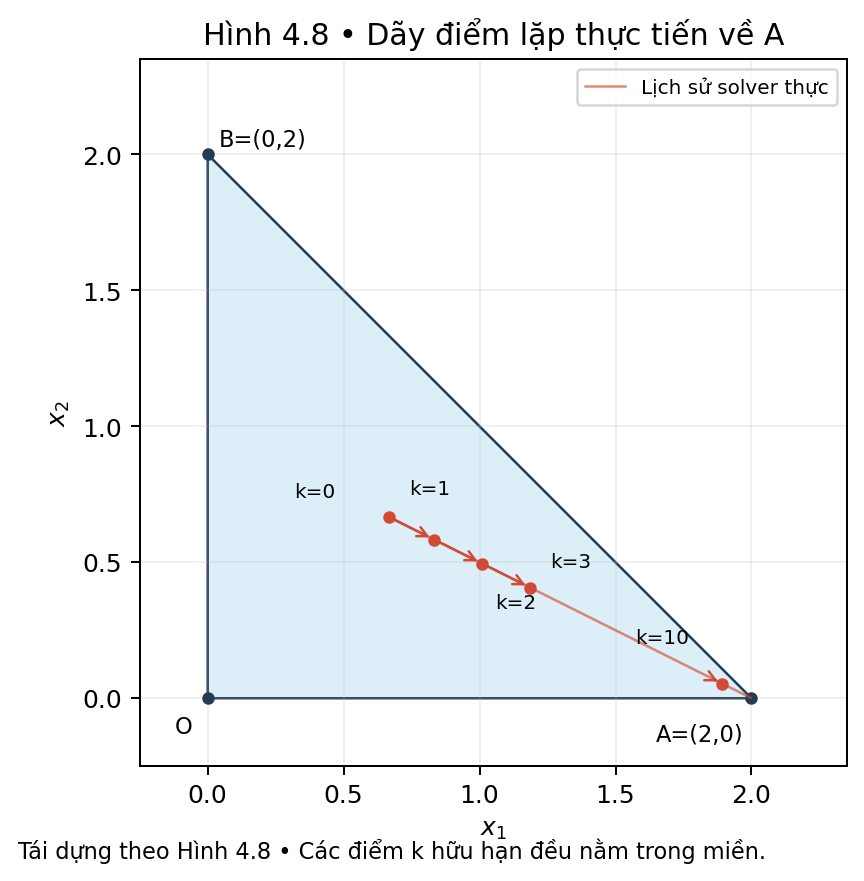

In [52]:
# NB52 | BC 4.4.9; Hình 4.8 | MasterSpec C10, section 5.2
show(plots.plot_figure_4_8(source_run20),'figure_4_8')


#### Kết luận dễ hiểu sau NB52

**Điều cần nhớ:** Vẽ đường đi của các điểm lặp để thấy chúng ở trong tam giác và tiến dần về đỉnh A.

<details><summary>Ghi chú kỹ thuật — chỉ cần mở khi muốn xem sâu hơn</summary>

**Dấu hiệu kiểm tra:** Các điểm hữu hạn nằm trong miền và tiến về A.

Đường nối chỉ mô tả thứ tự các điểm lặp; không có bước hữu hạn nào được đặt sẵn tại nghiệm đỉnh.

</details>

### NB53 · 🎨 VẼ HÌNH · 4.4.10; (4.56)

> **Vị trí trong tài liệu:** BC 4.4.10; (4.56); MasterSpec C06/C10, §5.2 (NB53).

**Mục đích / Vì sao cần (nói ngắn gọn):** Biến các con số thành hình để người đọc nhìn ra ý chính mà không phải đọc công thức.

**Cách hiểu đơn giản:** Vẽ riêng giá trị mục tiêu và thước đo tiến triển để không nhầm hai khái niệm này với nhau.

**Loại nội dung:** Phần này dùng code để tạo hình minh họa. Bạn có thể bỏ qua code và xem hình.

**Input — dữ liệu đưa vào (tên dùng trong code/PDF):** Lịch sử thực.  
*Hiểu đơn giản:* Các điểm hoặc số liệu đã được tính ở bước trước; chúng được đưa vào để đặt lên hình.

**Đang làm gì — máy sẽ xử lý:** Vẽ mục tiêu và hàm thế trên hai hình riêng.

**Output — kết quả nhận được (tên dùng trong code/PDF):** objective_vs_iteration, potential_vs_iteration.  
*Hiểu đơn giản:* Một hình minh họa. Bạn chỉ cần quan sát hình và đọc chú thích, không cần đọc lệnh vẽ.

**Input/Output:** đã được tách riêng ở hai dòng trên để dễ theo dõi.

**Nếu chỉ nhớ một ý:** Vẽ riêng giá trị mục tiêu và thước đo tiến triển để không nhầm hai khái niệm này với nhau.

<details><summary>Dấu hiệu kỹ thuật để kiểm tra — có thể bỏ qua ở lần đọc đầu</summary>

**Lý do kỹ thuật của bước này:** Hai đại lượng có ý nghĩa và thang đo khác nhau.

**Cần nhìn kết quả nào:** z→0; Phi giảm tuyến tính theo k trong ví dụ.

</details>

🧑‍💻 **Nếu bạn không học code:** có thể bỏ qua ô code ngay bên dưới, xem kết quả rồi đọc phần kết luận.

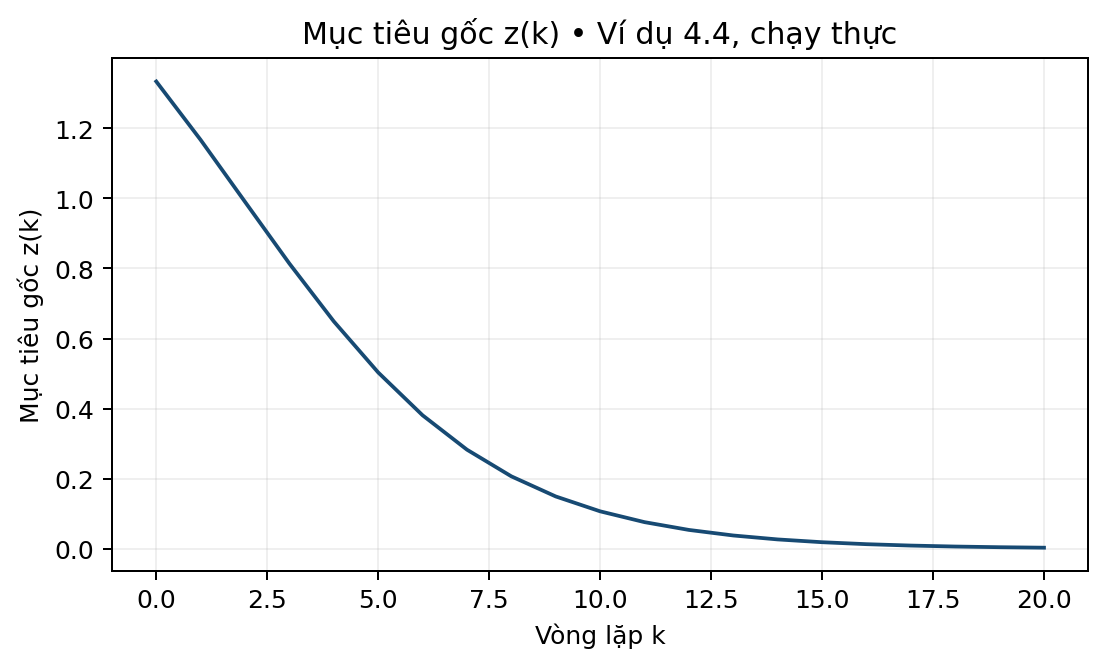

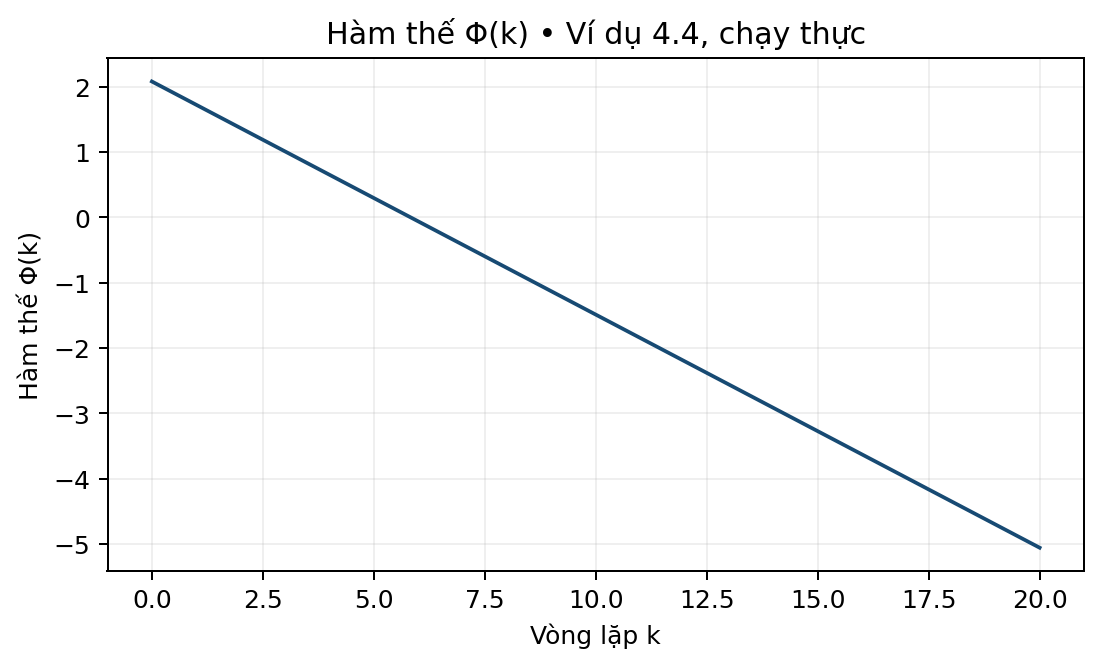

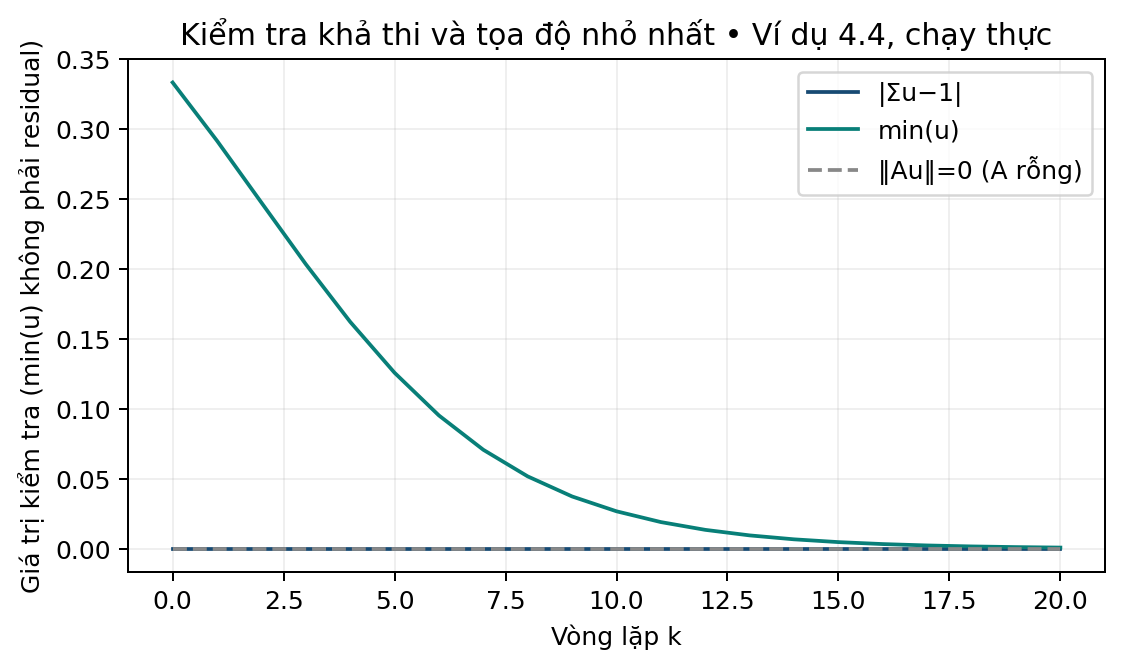

In [53]:
# NB53 | BC 4.4.10; (4.56) | MasterSpec C06/C10, section 5.2
hist_figures=plots.plot_histories(source_run20)
show(hist_figures['objective_vs_iteration'],'objective_vs_iteration')
show(hist_figures['potential_vs_iteration'],'potential_vs_iteration')
show(hist_figures['feasibility_residuals'],'feasibility_residuals')


#### Kết luận dễ hiểu sau NB53

**Điều cần nhớ:** Vẽ riêng giá trị mục tiêu và thước đo tiến triển để không nhầm hai khái niệm này với nhau.

<details><summary>Ghi chú kỹ thuật — chỉ cần mở khi muốn xem sâu hơn</summary>

**Dấu hiệu kiểm tra:** z→0; Phi giảm tuyến tính theo k trong ví dụ.

Phi có thể âm và không phải sai số mục tiêu; trong ví dụ nó giảm đều dù z giảm theo dạng phân thức của lũy thừa.

</details>

### NB54 · ✅ KIỂM TRA · 4.4.10; (4.56)

> **Vị trí trong tài liệu:** BC 4.4.10; (4.56); MasterSpec C06/C09, §5.2 (NB54).

**Mục đích / Vì sao cần (nói ngắn gọn):** Phát hiện sớm kết quả sai bằng cách so với một điều kiện hoặc kết quả đã biết.

**Cách hiểu đơn giản:** Kiểm tra mức giảm của thước đo ở mỗi vòng có đúng bằng con số được suy ra trong báo cáo.

**Loại nội dung:** Phần này xác nhận kết quả đã tính đúng hoặc phát hiện dữ liệu sai.

**Input — dữ liệu đưa vào (tên dùng trong code/PDF):** history20.phi.diff().  
*Hiểu đơn giản:* Kết quả vừa tính cùng điều kiện đúng dùng làm mốc so sánh.

**Đang làm gì — máy sẽ xử lý:** Kiểm tra delta Phi thực.

**Output — kết quả nhận được (tên dùng trong code/PDF):** bảng delta.  
*Hiểu đơn giản:* Sai số, bảng so sánh hoặc thông báo đạt/không đạt để biết bước trước có chạy đúng không.

**Input/Output:** đã được tách riêng ở hai dòng trên để dễ theo dõi.

**Nếu chỉ nhớ một ý:** Kiểm tra mức giảm của thước đo ở mỗi vòng có đúng bằng con số được suy ra trong báo cáo.

<details><summary>Dấu hiệu kỹ thuật để kiểm tra — có thể bỏ qua ở lần đọc đầu</summary>

**Lý do kỹ thuật của bước này:** Đối chiếu ln(7/10) và mức giảm 1/8.

**Cần nhìn kết quả nào:** Delta≈−0.3566749439; mức giảm là đối dấu.

</details>

🧑‍💻 **Nếu bạn không học code:** có thể bỏ qua ô code ngay bên dưới, xem kết quả rồi đọc phần kết luận.

In [54]:
# NB54 | BC 4.4.10; (4.56) | MasterSpec C06/C09, section 5.2
delta_table=pd.DataFrame({'k':history20.k.iloc[1:],'delta_phi':history20.phi.diff().iloc[1:]})
delta_table['error']=delta_table.delta_phi-np.log(.7)
display(delta_table.head())
assert np.max(abs(delta_table.error))<1e-9


,k,delta_phi,error
1,1,-0.356675,4.440892e-16
2,2,-0.356675,0.000000e+00
3,3,-0.356675,0.000000e+00
4,4,-0.356675,0.000000e+00
5,5,-0.356675,0.000000e+00


#### Kết luận dễ hiểu sau NB54

**Điều cần nhớ:** Kiểm tra mức giảm của thước đo ở mỗi vòng có đúng bằng con số được suy ra trong báo cáo.

<details><summary>Ghi chú kỹ thuật — chỉ cần mở khi muốn xem sâu hơn</summary>

**Dấu hiệu kiểm tra:** Delta≈−0.3566749439; mức giảm là đối dấu.

Ở đây ΔPhi=Phi(k+1)−Phi(k)<0; lượng giảm dương là ln(10/7)>1/8. Hai cách ghi dấu phải nhất quán.

</details>

### NB55 · 📘 Ý TƯỞNG / THUẬT TOÁN · 4.4.10; (4.57)

> **Vị trí trong tài liệu:** BC 4.4.10; (4.57); MasterSpec C09, §5.2 (NB55).

**Mục đích / Vì sao cần (nói ngắn gọn):** Giải thích hoặc thực hiện một bước giúp Karmarkar tìm phương án tốt dần mà vẫn tuân thủ các điều kiện.

**Cách hiểu đơn giản:** Tìm vòng đầu tiên mà sai số mục tiêu nhỏ hơn 0.1 và kiểm tra cả vòng ngay trước đó.

**Loại nội dung:** Phần này giúp hiểu thuật toán làm gì. Code chỉ là cách máy thực hiện ý tưởng đó.

**Input — dữ liệu đưa vào (tên dùng trong code/PDF):** epsilon_z=0.1.  
*Hiểu đơn giản:* Bài toán, điểm hiện tại và các nút điều chỉnh mà bước thuật toán này cần.

**Đang làm gì — máy sẽ xử lý:** Tính số vòng nhỏ nhất với epsilon của z.

**Output — kết quả nhận được (tên dùng trong code/PDF):** k_min,z(k−1),z(k).  
*Hiểu đơn giản:* Một hướng đi, điểm mới hoặc các con số trung gian để tiếp tục vòng Karmarkar.

**Input/Output:** đã được tách riêng ở hai dòng trên để dễ theo dõi.

**Nếu chỉ nhớ một ý:** Tìm vòng đầu tiên mà sai số mục tiêu nhỏ hơn 0.1 và kiểm tra cả vòng ngay trước đó.

<details><summary>Dấu hiệu kỹ thuật để kiểm tra — có thể bỏ qua ở lần đọc đầu</summary>

**Lý do kỹ thuật của bước này:** Kiểm cả k−1 và k thay vì chỉ thay công thức.

**Cần nhìn kết quả nào:** k=11; z10>0.1; z11≤0.1.

</details>

🧑‍💻 **Nếu bạn không học code:** có thể bỏ qua ô code ngay bên dưới, xem kết quả rồi đọc phần kết luận.

In [55]:
# NB55 | BC 4.4.10; (4.57) | MasterSpec C09, section 5.2
epsilon_z=.1
k_min=minimum_example_iterations(epsilon_z)
display({'epsilon_z':epsilon_z,'k_min':k_min,'z(k-1)':analytic_objective(k_min-1),'z(k)':analytic_objective(k_min)})
assert k_min==11 and analytic_objective(10)>.1 and analytic_objective(11)<=.1


{'epsilon_z': 0.1,
 'k_min': 11,
 'z(k-1)': 0.10694806343048134,
 'z(k)': 0.07608420312867642}

#### Kết luận dễ hiểu sau NB55

**Điều cần nhớ:** Tìm vòng đầu tiên mà sai số mục tiêu nhỏ hơn 0.1 và kiểm tra cả vòng ngay trước đó.

<details><summary>Ghi chú kỹ thuật — chỉ cần mở khi muốn xem sâu hơn</summary>

**Dấu hiệu kiểm tra:** k=11; z10>0.1; z11≤0.1.

Công thức chỉ dùng cho ví dụ có dạng đóng (4.54). Không dùng số vòng này để dự đoán LP khác.

</details>

### NB56 · ✅ KIỂM TRA · 4.4.11; Bảng 4.3

> **Vị trí trong tài liệu:** BC 4.4.11; Bảng 4.3; MasterSpec C09/C12, §5.2 (NB56).

**Mục đích / Vì sao cần (nói ngắn gọn):** Phát hiện sớm kết quả sai bằng cách so với một điều kiện hoặc kết quả đã biết.

**Cách hiểu đơn giản:** So sánh lời giải bằng hình học với Karmarkar theo cách làm, kết quả và phạm vi sử dụng.

**Loại nội dung:** Phần này xác nhận kết quả đã tính đúng hoặc phát hiện dữ liệu sai.

**Input — dữ liệu đưa vào (tên dùng trong code/PDF):** Nội dung nguồn.  
*Hiểu đơn giản:* Kết quả vừa tính cùng điều kiện đúng dùng làm mốc so sánh.

**Đang làm gì — máy sẽ xử lý:** Tái lập bảng so sánh hai cách giải.

**Output — kết quả nhận được (tên dùng trong code/PDF):** table_4_3_methods.csv.  
*Hiểu đơn giản:* Sai số, bảng so sánh hoặc thông báo đạt/không đạt để biết bước trước có chạy đúng không.

**Input/Output:** đã được tách riêng ở hai dòng trên để dễ theo dõi.

**Nếu chỉ nhớ một ý:** So sánh lời giải bằng hình học với Karmarkar theo cách làm, kết quả và phạm vi sử dụng.

<details><summary>Dấu hiệu kỹ thuật để kiểm tra — có thể bỏ qua ở lần đọc đầu</summary>

**Lý do kỹ thuật của bước này:** So phạm vi và kết quả, không bịa thời gian chạy hình học.

**Cần nhìn kết quả nào:** Hai phương pháp cùng nghiệm giới hạn; cách tiếp cận khác nhau.

</details>

🧑‍💻 **Nếu bạn không học code:** có thể bỏ qua ô code ngay bên dưới, xem kết quả rồi đọc phần kết luận.

In [56]:
# NB56 | BC 4.4.11; Bảng 4.3 | MasterSpec C09/C12, section 5.2
display(methods_table())
methods_table().to_csv(OUT/'tables/table_4_3_methods.csv',index=False,encoding='utf-8-sig')


,criterion,geometry_method,karmarkar_method
0,Bài toán xét,"Hai biến, miền tam giác OAB","Cùng bài toán, sau khi thêm biến bù và chuẩn hóa"
1,Cách giải,Vẽ miền chấp nhận được; so sánh mục tiêu tại c...,Tạo dãy điểm trong bằng phép chiếu và biến đổi...
2,Kết quả,"(x1*,x2*)=(2,0), z*=0","(x1(k),x2(k))→(2,0), z(k)→0"
3,Phạm vi,Thuận lợi khi có hai biến,Áp dụng cho bài toán nhiều biến ở dạng chuẩn


#### Kết luận dễ hiểu sau NB56

**Điều cần nhớ:** So sánh lời giải bằng hình học với Karmarkar theo cách làm, kết quả và phạm vi sử dụng.

<details><summary>Ghi chú kỹ thuật — chỉ cần mở khi muốn xem sâu hơn</summary>

**Dấu hiệu kiểm tra:** Hai phương pháp cùng nghiệm giới hạn; cách tiếp cận khác nhau.

Hình học tiện cho hai biến; Karmarkar có công thức n biến ở dạng chuẩn. Bảng này không khẳng định thuật toán nào nhanh hơn.

</details>

## F. Giới hạn, kiểm tra và chạy thử — BC 4.5 và [DX]

**Phần này giúp bạn hiểu:** Phân biệt điều đã thấy từ kết quả chạy máy với điều có thể khẳng định bằng lý thuyết; các bài thất bại cũng được giữ lại để báo cáo trung thực.

Nếu gặp công thức khó, hãy đọc phần diễn giải bằng lời và nhìn hình/kết quả trước.

### NB57 · ✅ KIỂM TRA · 4.5.1

> **Vị trí trong tài liệu:** BC 4.5.1; MasterSpec C07/C09, §5.2 (NB57).

**Mục đích / Vì sao cần (nói ngắn gọn):** Phát hiện sớm kết quả sai bằng cách so với một điều kiện hoặc kết quả đã biết.

**Cách hiểu đơn giản:** Kiểm tra mọi điểm hữu hạn vẫn nằm trong miền; chỉ giới hạn của dãy mới tiến sát biên.

**Loại nội dung:** Phần này xác nhận kết quả đã tính đúng hoặc phát hiện dữ liệu sai.

**Input — dữ liệu đưa vào (tên dùng trong code/PDF):** Lịch sử thực.  
*Hiểu đơn giản:* Kết quả vừa tính cùng điều kiện đúng dùng làm mốc so sánh.

**Đang làm gì — máy sẽ xử lý:** Kiểm tọa độ nhỏ nhất ở các vòng hữu hạn.

**Output — kết quả nhận được (tên dùng trong code/PDF):** min(u).  
*Hiểu đơn giản:* Sai số, bảng so sánh hoặc thông báo đạt/không đạt để biết bước trước có chạy đúng không.

**Input/Output:** đã được tách riêng ở hai dòng trên để dễ theo dõi.

**Nếu chỉ nhớ một ý:** Kiểm tra mọi điểm hữu hạn vẫn nằm trong miền; chỉ giới hạn của dãy mới tiến sát biên.

<details><summary>Dấu hiệu kỹ thuật để kiểm tra — có thể bỏ qua ở lần đọc đầu</summary>

**Lý do kỹ thuật của bước này:** Phân biệt điểm trong với giới hạn nằm trên biên.

**Cần nhìn kết quả nào:** Mọi giá trị đã chạy đều dương.

</details>

🧑‍💻 **Nếu bạn không học code:** có thể bỏ qua ô code ngay bên dưới, xem kết quả rồi đọc phần kết luận.

In [57]:
# NB57 | BC 4.5.1 | MasterSpec C07/C09, section 5.2
display(history20[['k','min_u']].iloc[[0,1,2,3,10,20]])
assert np.all(actual_points>0)


,k,min_u
0,0,0.333333
1,1,0.291667
2,2,0.247475
3,3,0.203440
10,10,0.026737
20,20,0.000797


#### Kết luận dễ hiểu sau NB57

**Điều cần nhớ:** Kiểm tra mọi điểm hữu hạn vẫn nằm trong miền; chỉ giới hạn của dãy mới tiến sát biên.

<details><summary>Ghi chú kỹ thuật — chỉ cần mở khi muốn xem sâu hơn</summary>

**Dấu hiệu kiểm tra:** Mọi giá trị đã chạy đều dương.

u2,u3 tiến về 0 trong giới hạn; điều đó không đồng nghĩa đã bằng 0 ở một bước hữu hạn trong mô hình toán học.

</details>

### NB58 · ✅ KIỂM TRA · 4.5.2

> **Vị trí trong tài liệu:** BC 4.5.2; MasterSpec C04/C05, §5.2 (NB58).

**Mục đích / Vì sao cần (nói ngắn gọn):** Phát hiện sớm kết quả sai bằng cách so với một điều kiện hoặc kết quả đã biết.

**Cách hiểu đơn giản:** Tách rõ ba vai trò: đổi điểm về tâm, giữ đúng điều kiện và giới hạn độ dài bước đi.

**Loại nội dung:** Phần này xác nhận kết quả đã tính đúng hoặc phát hiện dữ liệu sai.

**Input — dữ liệu đưa vào (tên dùng trong code/PDF):** Tₐ(a), Bp.  
*Hiểu đơn giản:* Kết quả vừa tính cùng điều kiện đúng dùng làm mốc so sánh.

**Đang làm gì — máy sẽ xử lý:** Đối chiếu vai trò xạ ảnh và chiếu.

**Output — kết quả nhận được (tên dùng trong code/PDF):** bảng vai trò.  
*Hiểu đơn giản:* Sai số, bảng so sánh hoặc thông báo đạt/không đạt để biết bước trước có chạy đúng không.

**Input/Output:** đã được tách riêng ở hai dòng trên để dễ theo dõi.

**Nếu chỉ nhớ một ý:** Tách rõ ba vai trò: đổi điểm về tâm, giữ đúng điều kiện và giới hạn độ dài bước đi.

<details><summary>Dấu hiệu kỹ thuật để kiểm tra — có thể bỏ qua ở lần đọc đầu</summary>

**Lý do kỹ thuật của bước này:** Hai phép giải quyết hai khó khăn khác nhau.

**Cần nhìn kết quả nào:** Xạ ảnh đưa về tâm; chiếu giữ đẳng thức.

</details>

🧑‍💻 **Nếu bạn không học code:** có thể bỏ qua ô code ngay bên dưới, xem kết quả rồi đọc phần kết luận.

In [58]:
# NB58 | BC 4.5.2 | MasterSpec C04/C05, section 5.2
display(pd.DataFrame({'Phép':['Xạ ảnh','Chiếu trực giao','Giới hạn bước'],'Vai trò':['Đưa điểm mốc về tâm để dùng cùng bán kính','Giữ hướng trong Ker[AD;eᵀ]','Giữ điểm mới trong đơn giác'],'Kiểm tra':[str(to_projective(a,a)),str(demo_step.B@demo_step.p),'alpha*r<r']}))


,Phép,Vai trò,Kiểm tra
0,Xạ ảnh,Đưa điểm mốc về tâm để dùng cùng bán kính,[0.33333333 0.33333333 0.33333333]
1,Chiếu trực giao,Giữ hướng trong Ker[AD;eᵀ],[2.77555756e-17]
2,Giới hạn bước,Giữ điểm mới trong đơn giác,alpha*r<r


#### Kết luận dễ hiểu sau NB58

**Điều cần nhớ:** Tách rõ ba vai trò: đổi điểm về tâm, giữ đúng điều kiện và giới hạn độ dài bước đi.

<details><summary>Ghi chú kỹ thuật — chỉ cần mở khi muốn xem sâu hơn</summary>

**Dấu hiệu kiểm tra:** Xạ ảnh đưa về tâm; chiếu giữ đẳng thức.

Cần ghép cả ba cơ chế để bảo toàn tính chấp nhận được; không thay cơ chế này bằng cơ chế kia.

</details>

### NB59 · 📘 Ý TƯỞNG / THUẬT TOÁN · 4.5.3

> **Vị trí trong tài liệu:** BC 4.5.3; MasterSpec C08/C12, §5.2 (NB59).

**Mục đích / Vì sao cần (nói ngắn gọn):** Giải thích hoặc thực hiện một bước giúp Karmarkar tìm phương án tốt dần mà vẫn tuân thủ các điều kiện.

**Cách hiểu đơn giản:** Liệt kê điều dự án đã chứng minh bằng chạy máy và điều chưa được phép khẳng định.

**Loại nội dung:** Phần này giúp hiểu thuật toán làm gì. Code chỉ là cách máy thực hiện ý tưởng đó.

**Input — dữ liệu đưa vào (tên dùng trong code/PDF):** Bằng chứng hiện có.  
*Hiểu đơn giản:* Bài toán, điểm hiện tại và các nút điều chỉnh mà bước thuật toán này cần.

**Đang làm gì — máy sẽ xử lý:** Hiển thị giới hạn các kết luận.

**Output — kết quả nhận được (tên dùng trong code/PDF):** claims checklist.  
*Hiểu đơn giản:* Một hướng đi, điểm mới hoặc các con số trung gian để tiếp tục vòng Karmarkar.

**Input/Output:** đã được tách riêng ở hai dòng trên để dễ theo dõi.

**Nếu chỉ nhớ một ý:** Liệt kê điều dự án đã chứng minh bằng chạy máy và điều chưa được phép khẳng định.

<details><summary>Dấu hiệu kỹ thuật để kiểm tra — có thể bỏ qua ở lần đọc đầu</summary>

**Lý do kỹ thuật của bước này:** Ngăn diễn giải quá mức dữ liệu mẫu.

**Cần nhìn kết quả nào:** Không chứng nhận exact optimality, complexity hay hỗ trợ LP tổng quát.

</details>

🧑‍💻 **Nếu bạn không học code:** có thể bỏ qua ô code ngay bên dưới, xem kết quả rồi đọc phần kết luận.

In [59]:
# NB59 | BC 4.5.3 | MasterSpec C08/C12, section 5.2
claims=pd.DataFrame({'Kết luận':['Khớp ví dụ 4.4','Chứng nhận tối ưu chính xác','Chứng minh runtime đa thức cho NumPy','Tiền xử lý LP tổng quát'],'Đã cung cấp':[True,False,False,False]})
display(claims)


,Kết luận,Đã cung cấp
0,Khớp ví dụ 4.4,True
1,Chứng nhận tối ưu chính xác,False
2,Chứng minh runtime đa thức cho NumPy,False
3,Tiền xử lý LP tổng quát,False


#### Kết luận dễ hiểu sau NB59

**Điều cần nhớ:** Liệt kê điều dự án đã chứng minh bằng chạy máy và điều chưa được phép khẳng định.

<details><summary>Ghi chú kỹ thuật — chỉ cần mở khi muốn xem sâu hơn</summary>

**Dấu hiệu kiểm tra:** Không chứng nhận exact optimality, complexity hay hỗ trợ LP tổng quát.

Ví dụ kiểm chứng công thức, tính khả thi, hàm thế và giới hạn; phần còn lại chỉ được tuyên bố khi có thủ tục/chứng minh riêng.

</details>

### NB60 · 🧪 THỰC NGHIỆM · 4.5.3 [DX]; MasterSpec 8.2

> **Vị trí trong tài liệu:** BC 4.5.3 [DX]; MasterSpec 8.2; MasterSpec C11, §5.2 (NB60).

**Mục đích / Vì sao cần (nói ngắn gọn):** Chạy thử trên nhiều tình huống để quan sát chương trình hoạt động ra sao trong thực tế.

**Cách hiểu đơn giản:** Tạo nhiều bài thử có chủ đích: bài bình thường, bài có điều kiện phụ, bài sai và bài khó về số học.

**Loại nội dung:** Phần này chạy thử bằng máy để kiểm tra chương trình; không thay thế chứng minh toán học.

**Input — dữ liệu đưa vào (tên dùng trong code/PDF):** Seed cố định.  
*Hiểu đơn giản:* Danh sách bài thử cùng các tùy chọn chạy; đây không phải dữ liệu bạn phải nhập bằng tay.

**Đang làm gì — máy sẽ xử lý:** Sinh các nhóm bài F1–F8 có kiểm soát.

**Output — kết quả nhận được (tên dùng trong code/PDF):** danh sách bài và chứng cứ giả thiết.  
*Hiểu đơn giản:* Bảng hoặc hình thống kê được tạo từ các lần chạy thật trên máy.

**Input/Output:** đã được tách riêng ở hai dòng trên để dễ theo dõi.

**Nếu chỉ nhớ một ý:** Tạo nhiều bài thử có chủ đích: bài bình thường, bài có điều kiện phụ, bài sai và bài khó về số học.

<details><summary>Dấu hiệu kỹ thuật để kiểm tra — có thể bỏ qua ở lần đọc đầu</summary>

**Lý do kỹ thuật của bước này:** Ví dụ A rỗng không kiểm hết nhánh AD.

**Cần nhìn kết quả nào:** Có bài ràng buộc phụ, hàng phụ thuộc, cực tiểu dương, sai dữ liệu và stress.

</details>

🧑‍💻 **Nếu bạn không học code:** có thể bỏ qua ô code ngay bên dưới, xem kết quả rồi đọc phần kết luận.

In [60]:
# NB60 | BC 4.5.3 [DX]; MasterSpec 8.2 | MasterSpec C11, section 5.2
cases=dataset_cases(raw_config['seed'])
display(pd.DataFrame([{'case':p.name,'A.shape':p.A.shape,'c.shape':p.c.shape,
                      'valid':validate_canonical(p,config).valid,'zero_known':validate_canonical(p,config).zero_optimum_known} for p in cases]))
write_json(OUT/'dataset_manifest.json',{'seed':raw_config['seed'],'cases':cases})


,case,A.shape,c.shape,valid,zero_known
0,F1_source,"(0, 3)","(3,)",True,True
1,F2_n4,"(0, 4)","(4,)",True,True
2,F2_n8,"(0, 8)","(8,)",True,True
3,F2_n16,"(0, 16)","(16,)",True,True
4,F2_n32,"(0, 32)","(32,)",True,True
5,F3_equality,"(1, 4)","(4,)",True,True
6,F4_dependent,"(3, 4)","(4,)",True,True
7,F5_no_movement,"(1, 2)","(2,)",True,False
8,F6_positive_optimum,"(0, 4)","(4,)",True,False
9,F6_constant_positive,"(0, 3)","(3,)",True,False


#### Kết luận dễ hiểu sau NB60

**Điều cần nhớ:** Tạo nhiều bài thử có chủ đích: bài bình thường, bài có điều kiện phụ, bài sai và bài khó về số học.

<details><summary>Ghi chú kỹ thuật — chỉ cần mở khi muốn xem sâu hơn</summary>

**Dấu hiệu kiểm tra:** Có bài ràng buộc phụ, hàng phụ thuộc, cực tiểu dương, sai dữ liệu và stress.

F2 có c≥0 và tọa độ chi phí 0; F3 có nghiệm biên (1/2,1/2,0,0). F7 là dữ liệu sai được giữ trong kết quả.

</details>

### NB61 · 🧪 THỰC NGHIỆM · 4.5.3 [DX]; MasterSpec 8.4

> **Vị trí trong tài liệu:** BC 4.5.3 [DX]; MasterSpec 8.4; MasterSpec C11, §5.2 (NB61).

**Mục đích / Vì sao cần (nói ngắn gọn):** Chạy thử trên nhiều tình huống để quan sát chương trình hoạt động ra sao trong thực tế.

**Cách hiểu đơn giản:** Chạy thuật toán nhiều lần trên toàn bộ bộ bài thử và giữ lại cả các lần thất bại.

**Loại nội dung:** Phần này chạy thử bằng máy để kiểm tra chương trình; không thay thế chứng minh toán học.

**Input — dữ liệu đưa vào (tên dùng trong code/PDF):** 16 bài, 5 lần/bài.  
*Hiểu đơn giản:* Danh sách bài thử cùng các tùy chọn chạy; đây không phải dữ liệu bạn phải nhập bằng tay.

**Đang làm gì — máy sẽ xử lý:** Chạy batch thật với trace.

**Output — kết quả nhận được (tên dùng trong code/PDF):** benchmark_results, traces, manifest.  
*Hiểu đơn giản:* Bảng hoặc hình thống kê được tạo từ các lần chạy thật trên máy.

**Input/Output:** đã được tách riêng ở hai dòng trên để dễ theo dõi.

**Nếu chỉ nhớ một ý:** Chạy thuật toán nhiều lần trên toàn bộ bộ bài thử và giữ lại cả các lần thất bại.

<details><summary>Dấu hiệu kỹ thuật để kiểm tra — có thể bỏ qua ở lần đọc đầu</summary>

**Lý do kỹ thuật của bước này:** Sinh số liệu thực thay vì chép bảng expected.

**Cần nhìn kết quả nào:** Giữ nguyên mọi status, không lọc ca lỗi.

</details>

🧑‍💻 **Nếu bạn không học code:** có thể bỏ qua ô code ngay bên dưới, xem kết quả rồi đọc phần kết luận.

In [61]:
# NB61 | BC 4.5.3 [DX]; MasterSpec 8.4 | MasterSpec C11, section 5.2
benchmark_data,benchmark_summary=run_benchmark(cases,config,raw_config['repetitions'],raw_config['seed'],OUT)
display(benchmark_summary)


,case,n,status,repetitions,median_ms,min_ms,max_ms,std_ms,median_iter,reference_median_ms,reference_median_iter,objective,reference_gap
0,F1_source,3,approx_tol_reached,5,21.4062,17.8680,38.3358,8.069441,41.0,2.7959,0.0,8.913520e-07,8.913520e-07
1,F2_n16,16,approx_tol_reached,5,32.2951,24.2484,37.2070,6.009589,73.0,2.6345,0.0,8.348856e-07,8.348856e-07
2,F2_n32,32,approx_tol_reached,5,38.4591,32.3366,42.1243,4.496105,80.0,2.1434,0.0,9.224799e-07,9.224799e-07
3,F2_n4,4,approx_tol_reached,5,26.2667,22.3576,32.9113,4.988356,48.0,2.2137,0.0,7.984140e-07,7.984140e-07
4,F2_n8,8,approx_tol_reached,5,28.1295,27.1163,34.2137,2.933182,62.0,2.2062,0.0,9.669349e-07,9.669349e-07
5,F3_equality,4,approx_tol_reached,5,22.1089,16.9688,31.7785,5.977176,48.0,2.4753,0.0,8.708001e-07,8.708001e-07
6,F4_dependent,4,approx_tol_reached,5,21.3068,18.9811,26.5492,2.789975,48.0,2.1602,0.0,8.708001e-07,8.708001e-07
7,F5_no_movement,2,no_projected_direction,5,0.4617,0.2419,0.5007,0.115639,0.0,2.1623,0.0,5.000000e-01,0.000000e+00
8,F6_constant_positive,3,no_projected_direction,5,0.5133,0.3433,1.7277,0.577819,0.0,1.9820,0.0,1.000000e+00,0.000000e+00
9,F6_positive_optimum,4,max_iterations,5,440.5705,414.2442,483.5208,25.420662,1000.0,2.4894,0.0,1.978808e+00,9.788084e-01


#### Kết luận dễ hiểu sau NB61

**Điều cần nhớ:** Chạy thuật toán nhiều lần trên toàn bộ bộ bài thử và giữ lại cả các lần thất bại.

<details><summary>Ghi chú kỹ thuật — chỉ cần mở khi muốn xem sâu hơn</summary>

**Dấu hiệu kiểm tra:** Giữ nguyên mọi status, không lọc ca lỗi.

Timer của Karmarkar chỉ bao phần gọi solver; reference chạy sau với timer riêng. Import, xuất file và vẽ hình nằm ngoài timer.

</details>

### NB62 · 🧪 THỰC NGHIỆM · 4.5.3 [DX]; MasterSpec 8.3

> **Vị trí trong tài liệu:** BC 4.5.3 [DX]; MasterSpec 8.3; MasterSpec C11, §5.2 (NB62).

**Mục đích / Vì sao cần (nói ngắn gọn):** Chạy thử trên nhiều tình huống để quan sát chương trình hoạt động ra sao trong thực tế.

**Cách hiểu đơn giản:** Dùng một bộ giải độc lập làm thước tham khảo sau khi Karmarkar đã chạy xong; bộ giải này không tham gia tạo các bước Karmarkar.

**Loại nội dung:** Phần này chạy thử bằng máy để kiểm tra chương trình; không thay thế chứng minh toán học.

**Input — dữ liệu đưa vào (tên dùng trong code/PDF):** CanonicalLP.  
*Hiểu đơn giản:* Danh sách bài thử cùng các tùy chọn chạy; đây không phải dữ liệu bạn phải nhập bằng tay.

**Đang làm gì — máy sẽ xử lý:** Xem đối chứng HiGHS và gọi độc lập một bài.

**Output — kết quả nhận được (tên dùng trong code/PDF):** reference objective/status.  
*Hiểu đơn giản:* Bảng hoặc hình thống kê được tạo từ các lần chạy thật trên máy.

**Input/Output:** đã được tách riêng ở hai dòng trên để dễ theo dõi.

**Nếu chỉ nhớ một ý:** Dùng một bộ giải độc lập làm thước tham khảo sau khi Karmarkar đã chạy xong; bộ giải này không tham gia tạo các bước Karmarkar.

<details><summary>Dấu hiệu kỹ thuật để kiểm tra — có thể bỏ qua ở lần đọc đầu</summary>

**Lý do kỹ thuật của bước này:** So cùng mục tiêu/ràng buộc, không dùng nghiệm tham chiếu sinh bước.

**Cần nhìn kết quả nào:** Source reference w*=0; Aeq=[A;eᵀ], beq=[0;1].

</details>

🧑‍💻 **Nếu bạn không học code:** có thể bỏ qua ô code ngay bên dưới, xem kết quả rồi đọc phần kết luận.

In [62]:
# NB62 | BC 4.5.3 [DX]; MasterSpec 8.3 | MasterSpec C11, section 5.2
reference=solve_reference_with_highs(problem)
display(plain(reference))
display(benchmark_data[['case','status','objective','z_ref','reference_gap','reference_status']].drop_duplicates('case'))


{'success': True,
 'status': 0,
 'message': 'Optimization terminated successfully. (HiGHS Status 7: Optimal)',
 'method': 'highs-ds',
 'elapsed_ms': 1.6132999444380403,
 'iterations': 0,
 'objective': 0.0,
 'x': [1.0, 0.0, 0.0],
 'equality_residual': 0.0}

,case,status,objective,z_ref,reference_gap,reference_status
0,F1_source,approx_tol_reached,8.913520e-07,0.0,8.913520e-07,0
5,F2_n4,approx_tol_reached,7.984140e-07,0.0,7.984140e-07,0
10,F2_n8,approx_tol_reached,9.669349e-07,0.0,9.669349e-07,0
15,F2_n16,approx_tol_reached,8.348856e-07,0.0,8.348856e-07,0
20,F2_n32,approx_tol_reached,9.224799e-07,0.0,9.224799e-07,0
25,F3_equality,approx_tol_reached,8.708001e-07,0.0,8.708001e-07,0
30,F4_dependent,approx_tol_reached,8.708001e-07,0.0,8.708001e-07,0
35,F5_no_movement,no_projected_direction,5.000000e-01,0.5,0.000000e+00,0
40,F6_positive_optimum,max_iterations,1.978808e+00,1.0,9.788084e-01,0
45,F6_constant_positive,no_projected_direction,1.000000e+00,1.0,0.000000e+00,0


#### Kết luận dễ hiểu sau NB62

**Điều cần nhớ:** Dùng một bộ giải độc lập làm thước tham khảo sau khi Karmarkar đã chạy xong; bộ giải này không tham gia tạo các bước Karmarkar.

<details><summary>Ghi chú kỹ thuật — chỉ cần mở khi muốn xem sâu hơn</summary>

**Dấu hiệu kiểm tra:** Source reference w*=0; Aeq=[A;eᵀ], beq=[0;1].

reference_gap là khoảng cách tới kết quả HiGHS thành công, không phải chứng nhận do Karmarkar tự cung cấp. Nghiệm đỉnh và điểm trong có thể khác tọa độ dù mục tiêu gần nhau.

</details>

### NB63 · 🧪 THỰC NGHIỆM · 4.5.3 [DX]; MasterSpec 8.4

> **Vị trí trong tài liệu:** BC 4.5.3 [DX]; MasterSpec 8.4; MasterSpec C11, §5.2 (NB63).

**Mục đích / Vì sao cần (nói ngắn gọn):** Chạy thử trên nhiều tình huống để quan sát chương trình hoạt động ra sao trong thực tế.

**Cách hiểu đơn giản:** Tổng hợp thời gian và số vòng từ các lần chạy thật để người đọc biết kết quả đến từ môi trường nào.

**Loại nội dung:** Phần này chạy thử bằng máy để kiểm tra chương trình; không thay thế chứng minh toán học.

**Input — dữ liệu đưa vào (tên dùng trong code/PDF):** 5 lần/bài.  
*Hiểu đơn giản:* Danh sách bài thử cùng các tùy chọn chạy; đây không phải dữ liệu bạn phải nhập bằng tay.

**Đang làm gì — máy sẽ xử lý:** Tổng hợp thời gian thực và môi trường.

**Output — kết quả nhận được (tên dùng trong code/PDF):** median/min/max/std.  
*Hiểu đơn giản:* Bảng hoặc hình thống kê được tạo từ các lần chạy thật trên máy.

**Input/Output:** đã được tách riêng ở hai dòng trên để dễ theo dõi.

**Nếu chỉ nhớ một ý:** Tổng hợp thời gian và số vòng từ các lần chạy thật để người đọc biết kết quả đến từ môi trường nào.

<details><summary>Dấu hiệu kỹ thuật để kiểm tra — có thể bỏ qua ở lần đọc đầu</summary>

**Lý do kỹ thuật của bước này:** Một lần đo không đủ để khẳng định ưu thế tốc độ.

**Cần nhìn kết quả nào:** Ghi rõ memory chưa đo; tolerance reference khác stopping rule của core.

</details>

🧑‍💻 **Nếu bạn không học code:** có thể bỏ qua ô code ngay bên dưới, xem kết quả rồi đọc phần kết luận.

In [63]:
# NB63 | BC 4.5.3 [DX]; MasterSpec 8.4 | MasterSpec C11, section 5.2
display(benchmark_summary[['case','status','repetitions','median_ms','min_ms','max_ms','std_ms','reference_median_ms']])
display(environment_manifest(config,raw_config['seed']))


,case,status,repetitions,median_ms,min_ms,max_ms,std_ms,reference_median_ms
0,F1_source,approx_tol_reached,5,21.4062,17.8680,38.3358,8.069441,2.7959
1,F2_n16,approx_tol_reached,5,32.2951,24.2484,37.2070,6.009589,2.6345
2,F2_n32,approx_tol_reached,5,38.4591,32.3366,42.1243,4.496105,2.1434
3,F2_n4,approx_tol_reached,5,26.2667,22.3576,32.9113,4.988356,2.2137
4,F2_n8,approx_tol_reached,5,28.1295,27.1163,34.2137,2.933182,2.2062
5,F3_equality,approx_tol_reached,5,22.1089,16.9688,31.7785,5.977176,2.4753
6,F4_dependent,approx_tol_reached,5,21.3068,18.9811,26.5492,2.789975,2.1602
7,F5_no_movement,no_projected_direction,5,0.4617,0.2419,0.5007,0.115639,2.1623
8,F6_constant_positive,no_projected_direction,5,0.5133,0.3433,1.7277,0.577819,1.9820
9,F6_positive_optimum,max_iterations,5,440.5705,414.2442,483.5208,25.420662,2.4894


{'timestamp': '2026-10-30T15:37:30.059181+07:00',
 'timezone': 'Asia/Saigon',
 'python': '3.14.0rc2 (tags/v3.14.0rc2:31967d8, Aug 14 2025, 13:21:13) [MSC v.1944 64 bit (AMD64)]',
 'executable': 'D:\\Quy hoạch tuyến tính\\Karmarkar\\karmarkar-project\\.venv\\Scripts\\python.exe',
 'versions': {'numpy': '2.4.4',
  'scipy': '1.17.1',
  'matplotlib': '3.10.8',
  'pandas': '3.0.2',
  'pytest': '9.2.0',
  'nbformat': '5.11.1',
  'nbclient': '0.11.0'},
 'machine': 'Windows-11-10.0.26200-SP0',
 'processor': 'Intel64 Family 6 Model 170 Stepping 4, GenuineIntel',
 'seed': 20261028,
 'config': {'alpha': 0.25,
  'epsilon': 1e-06,
  'max_iter': 1000,
  'feas_tol': 1e-10,
  'positive_tol': 0.0,
  'projection_abs_tol': 1e-14,
  'projection_rel_tol': 1e-12,
  'potential_tol': 1e-09,
  'svd_rtol': 1e-14,
  'svd_atol': 0.0,
  'require_nonnegative_certificate': True,
  'allow_unverified_demo': False,
  'monitor_potential': False,
  'verbose': False,
  'store_trajectory': True},
 'config_hash': '819f19d97

#### Kết luận dễ hiểu sau NB63

**Điều cần nhớ:** Tổng hợp thời gian và số vòng từ các lần chạy thật để người đọc biết kết quả đến từ môi trường nào.

<details><summary>Ghi chú kỹ thuật — chỉ cần mở khi muốn xem sâu hơn</summary>

**Dấu hiệu kiểm tra:** Ghi rõ memory chưa đo; tolerance reference khác stopping rule của core.

Thời gian chỉ là quan sát trên máy này. Hai backend và tiêu chí dừng khác nhau nên bảng không phải so sánh công bằng tuyệt đối về thuật toán.

</details>

### NB64 · 🎨 VẼ HÌNH · 4.5.3 [DX]; MasterSpec 8.5

> **Vị trí trong tài liệu:** BC 4.5.3 [DX]; MasterSpec 8.5; MasterSpec C10/C11, §5.2 (NB64).

**Mục đích / Vì sao cần (nói ngắn gọn):** Biến các con số thành hình để người đọc nhìn ra ý chính mà không phải đọc công thức.

**Cách hiểu đơn giản:** Vẽ xu hướng thời gian và số vòng khi kích thước bài tăng; đây chỉ là quan sát thực nghiệm.

**Loại nội dung:** Phần này dùng code để tạo hình minh họa. Bạn có thể bỏ qua code và xem hình.

**Input — dữ liệu đưa vào (tên dùng trong code/PDF):** Nhóm F2.  
*Hiểu đơn giản:* Các điểm hoặc số liệu đã được tính ở bước trước; chúng được đưa vào để đặt lên hình.

**Đang làm gì — máy sẽ xử lý:** Vẽ runtime và số vòng theo n riêng.

**Output — kết quả nhận được (tên dùng trong code/PDF):** hai hình so sánh.  
*Hiểu đơn giản:* Một hình minh họa. Bạn chỉ cần quan sát hình và đọc chú thích, không cần đọc lệnh vẽ.

**Input/Output:** đã được tách riêng ở hai dòng trên để dễ theo dõi.

**Nếu chỉ nhớ một ý:** Vẽ xu hướng thời gian và số vòng khi kích thước bài tăng; đây chỉ là quan sát thực nghiệm.

<details><summary>Dấu hiệu kỹ thuật để kiểm tra — có thể bỏ qua ở lần đọc đầu</summary>

**Lý do kỹ thuật của bước này:** Không trộn số vòng với chi phí mỗi vòng.

**Cần nhìn kết quả nào:** Điểm dữ liệu từ benchmark thực, không diễn giải thành cận đa thức.

</details>

🧑‍💻 **Nếu bạn không học code:** có thể bỏ qua ô code ngay bên dưới, xem kết quả rồi đọc phần kết luận.

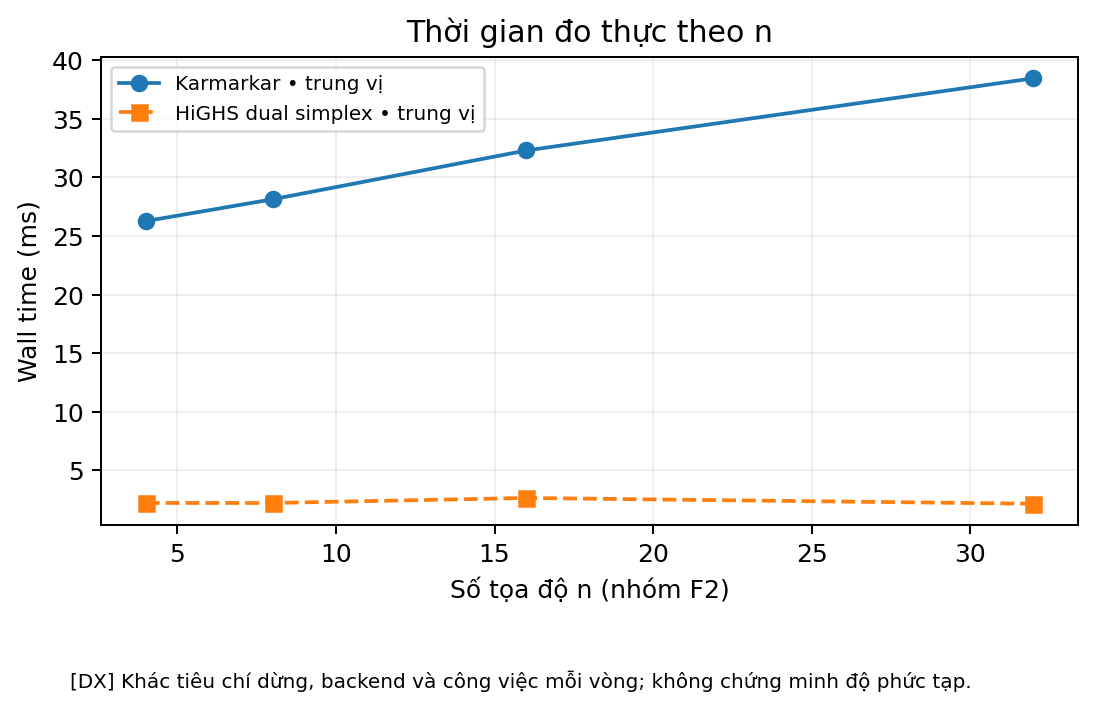

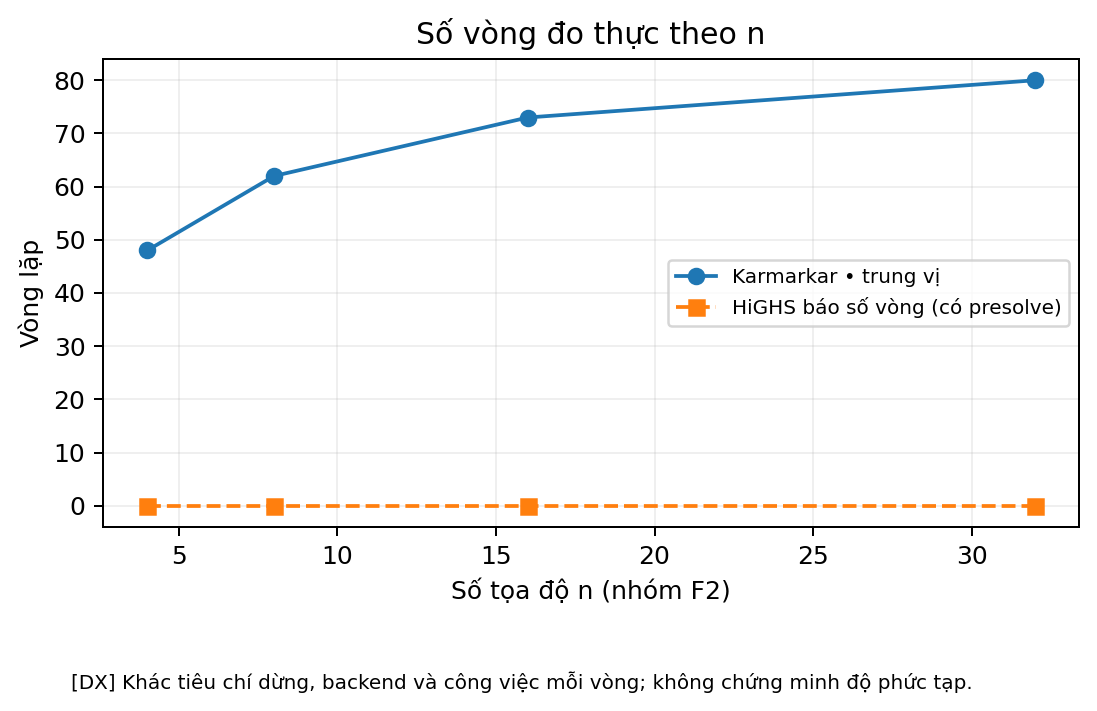

In [64]:
# NB64 | BC 4.5.3 [DX]; MasterSpec 8.5 | MasterSpec C10/C11, section 5.2
benchmark_figs=plots.plot_benchmark(benchmark_data,benchmark_summary)
show(benchmark_figs['runtime_vs_n'],'runtime_vs_n')
show(benchmark_figs['iterations_vs_n'],'iterations_vs_n')


#### Kết luận dễ hiểu sau NB64

**Điều cần nhớ:** Vẽ xu hướng thời gian và số vòng khi kích thước bài tăng; đây chỉ là quan sát thực nghiệm.

<details><summary>Ghi chú kỹ thuật — chỉ cần mở khi muốn xem sâu hơn</summary>

**Dấu hiệu kiểm tra:** Điểm dữ liệu từ benchmark thực, không diễn giải thành cận đa thức.

Các đồ thị phụ thuộc SVD, kích thước, tolerance và phần ghi trace. Không suy ra O(n^3.5 L) cho mã từ bốn điểm thực nghiệm.

</details>

### NB65 · 🧪 THỰC NGHIỆM · 4.5.3 [DX]; MasterSpec 8.5

> **Vị trí trong tài liệu:** BC 4.5.3 [DX]; MasterSpec 8.5; MasterSpec C08/C11, §5.2 (NB65).

**Mục đích / Vì sao cần (nói ngắn gọn):** Chạy thử trên nhiều tình huống để quan sát chương trình hoạt động ra sao trong thực tế.

**Cách hiểu đơn giản:** Đếm các kiểu kết thúc và xem sai số ràng buộc, kể cả các bài bị từ chối hoặc chưa hội tụ.

**Loại nội dung:** Phần này chạy thử bằng máy để kiểm tra chương trình; không thay thế chứng minh toán học.

**Input — dữ liệu đưa vào (tên dùng trong code/PDF):** Toàn bộ benchmark.  
*Hiểu đơn giản:* Danh sách bài thử cùng các tùy chọn chạy; đây không phải dữ liệu bạn phải nhập bằng tay.

**Đang làm gì — máy sẽ xử lý:** Tổng hợp thất bại và residual.

**Output — kết quả nhận được (tên dùng trong code/PDF):** status histogram, residual table.  
*Hiểu đơn giản:* Bảng hoặc hình thống kê được tạo từ các lần chạy thật trên máy.

**Input/Output:** đã được tách riêng ở hai dòng trên để dễ theo dõi.

**Nếu chỉ nhớ một ý:** Đếm các kiểu kết thúc và xem sai số ràng buộc, kể cả các bài bị từ chối hoặc chưa hội tụ.

<details><summary>Dấu hiệu kỹ thuật để kiểm tra — có thể bỏ qua ở lần đọc đầu</summary>

**Lý do kỹ thuật của bước này:** Không chỉ báo các run hội tụ.

**Cần nhìn kết quả nào:** F7 bị từ chối, ca không hướng/cực tiểu dương vẫn có dòng.

</details>

🧑‍💻 **Nếu bạn không học code:** có thể bỏ qua ô code ngay bên dưới, xem kết quả rồi đọc phần kết luận.

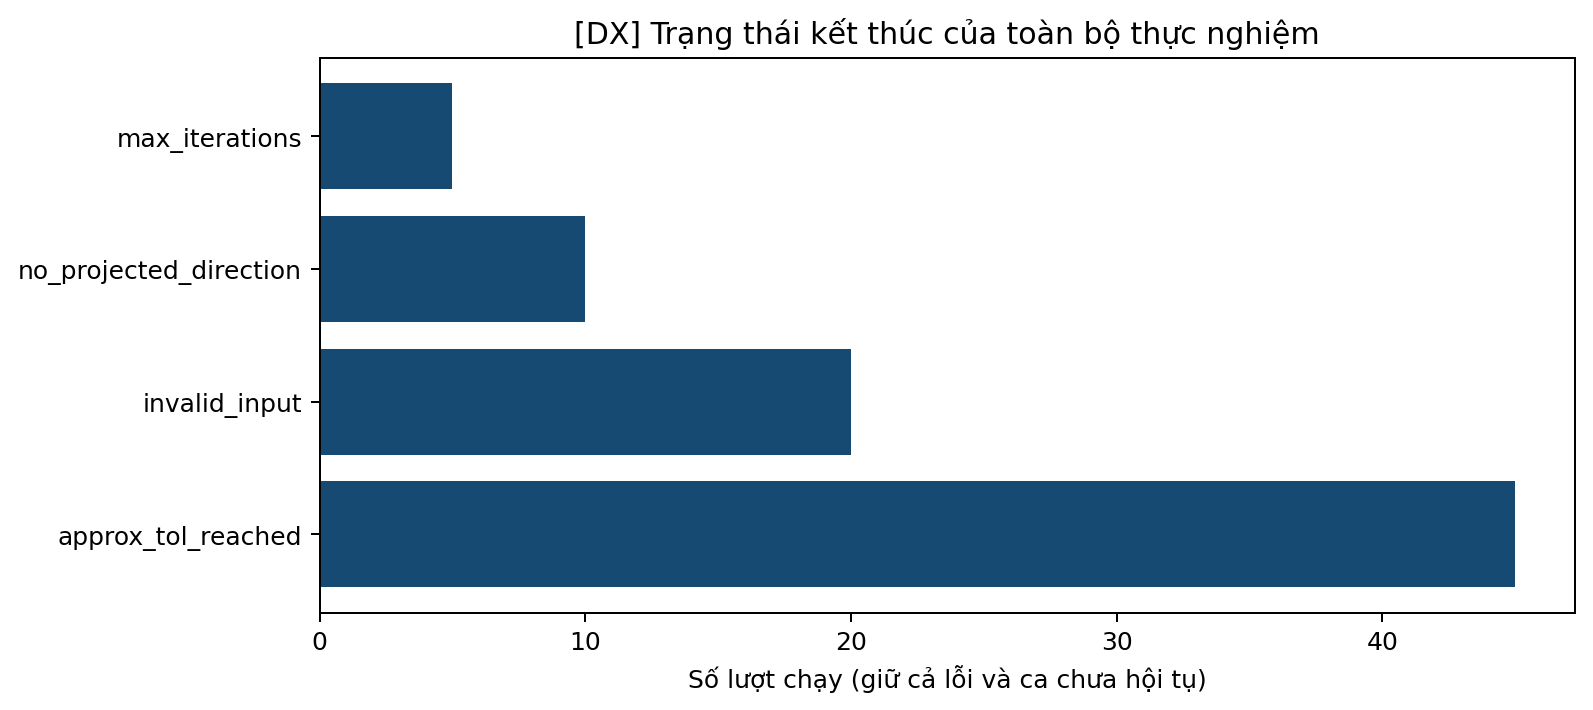

,feas,sum_residual,min_x
case,,,
F1_source,0.000000e+00,2.220446e-16,4.456760e-07
F2_n16,0.000000e+00,0.000000e+00,2.802683e-08
F2_n32,0.000000e+00,1.110223e-16,1.499968e-08
F2_n4,0.000000e+00,0.000000e+00,1.931133e-07
F2_n8,0.000000e+00,0.000000e+00,8.288658e-08
F3_equality,0.000000e+00,0.000000e+00,4.354001e-07
F4_dependent,1.110223e-16,0.000000e+00,4.354001e-07
F5_no_movement,0.000000e+00,0.000000e+00,5.000000e-01
F6_constant_positive,0.000000e+00,0.000000e+00,3.333333e-01


In [65]:
# NB65 | BC 4.5.3 [DX]; MasterSpec 8.5 | MasterSpec C08/C11, section 5.2
show(benchmark_figs['termination_statuses'],'termination_statuses')
display(benchmark_data.groupby('case')[['feas','sum_residual','min_x']].max())


#### Kết luận dễ hiểu sau NB65

**Điều cần nhớ:** Đếm các kiểu kết thúc và xem sai số ràng buộc, kể cả các bài bị từ chối hoặc chưa hội tụ.

<details><summary>Ghi chú kỹ thuật — chỉ cần mở khi muốn xem sâu hơn</summary>

**Dấu hiệu kiểm tra:** F7 bị từ chối, ca không hướng/cực tiểu dương vẫn có dòng.

INVALID_INPUT là kết quả mong đợi của dữ liệu sai; MAX_ITERATIONS và uncertainty phải được đọc theo từng bài, không đổi thành thành công.

</details>

### NB66 · 🛠️ CÀI ĐẶT / TỔ CHỨC · 4.1–4.5 [GD/DX]; MasterSpec 7.2

> **Vị trí trong tài liệu:** BC 4.1–4.5 [GD/DX]; MasterSpec 7.2; MasterSpec C12, §5.2 (NB66).

**Mục đích / Vì sao cần (nói ngắn gọn):** Chuẩn bị môi trường, dữ liệu hoặc nơi lưu kết quả để các phần sau chạy ổn định và có thể kiểm tra lại.

**Cách hiểu đơn giản:** Sinh lại toàn bộ hình, bảng và lịch sử bằng một lệnh để bảo đảm kết quả không được chép tay.

**Loại nội dung:** Phần này phục vụ chương trình và việc lưu kết quả, không phải bước toán học của Karmarkar.

**Input — dữ liệu đưa vào (tên dùng trong code/PDF):** config.  
*Hiểu đơn giản:* File, thư viện hoặc tùy chọn chương trình cần có sẵn trước khi tính toán.

**Đang làm gì — máy sẽ xử lý:** Tái sinh toàn bộ bộ hình/bảng nguồn.

**Output — kết quả nhận được (tên dùng trong code/PDF):** 8 hình, 3 bảng, JSON trace, history.  
*Hiểu đơn giản:* Một bảng, thư mục hoặc thông báo xác nhận rằng phần chuẩn bị đã hoàn tất.

**Input/Output:** đã được tách riêng ở hai dòng trên để dễ theo dõi.

**Nếu chỉ nhớ một ý:** Sinh lại toàn bộ hình, bảng và lịch sử bằng một lệnh để bảo đảm kết quả không được chép tay.

<details><summary>Dấu hiệu kỹ thuật để kiểm tra — có thể bỏ qua ở lần đọc đầu</summary>

**Lý do kỹ thuật của bước này:** Bảo đảm output có thể được tạo lại từ một lệnh.

**Cần nhìn kết quả nào:** Các file có dữ liệu thực và tên ổn định.

</details>

🧑‍💻 **Nếu bạn không học code:** có thể bỏ qua ô code ngay bên dưới, xem kết quả rồi đọc phần kết luận.

In [66]:
# NB66 | BC 4.1–4.5 [GD/DX]; MasterSpec 7.2 | MasterSpec C12, section 5.2
source_final,history_final=export_example_artifacts(OUT,config)
write_json(OUT/'source_run_summary.json',{'status':source_final.status,'iterations':source_final.iterations,'w':source_final.objective,'z':2*source_final.objective})
display(pd.DataFrame({'file':[str(p.relative_to(OUT)) for p in sorted(OUT.rglob('*')) if p.is_file() and 'pytest' not in str(p) and 'jupyter' not in str(p)]}).head(40))


,file
0,coverage_audit.json
1,dataset_manifest.json
2,figures\feasibility_residuals.png
3,figures\feasibility_residuals.svg
4,figures\figure_4_1.png
5,figures\figure_4_1.svg
6,figures\figure_4_2.png
7,figures\figure_4_2.svg
8,figures\figure_4_3.png
9,figures\figure_4_3.svg


#### Kết luận dễ hiểu sau NB66

**Điều cần nhớ:** Sinh lại toàn bộ hình, bảng và lịch sử bằng một lệnh để bảo đảm kết quả không được chép tay.

<details><summary>Ghi chú kỹ thuật — chỉ cần mở khi muốn xem sâu hơn</summary>

**Dấu hiệu kiểm tra:** Các file có dữ liệu thực và tên ổn định.

Các hình 4.8 và bảng bước lặp được lấy từ solver thực. Mọi ma trận nằm trong JSON; hình nguồn được ghi là tái dựng.

</details>

### NB67 · 🛠️ CÀI ĐẶT / TỔ CHỨC · 4.1–4.5; MasterSpec 11.1

> **Vị trí trong tài liệu:** BC 4.1–4.5; MasterSpec 11.1; MasterSpec C12, §5.2 (NB67).

**Mục đích / Vì sao cần (nói ngắn gọn):** Chuẩn bị môi trường, dữ liệu hoặc nơi lưu kết quả để các phần sau chạy ổn định và có thể kiểm tra lại.

**Cách hiểu đơn giản:** Tự kiểm tra notebook có đủ mục, đủ hình, đủ bảng và đủ 68 mã NB hay chưa.

**Loại nội dung:** Phần này phục vụ chương trình và việc lưu kết quả, không phải bước toán học của Karmarkar.

**Input — dữ liệu đưa vào (tên dùng trong code/PDF):** Source notebook + artifacts.  
*Hiểu đơn giản:* File, thư viện hoặc tùy chọn chương trình cần có sẵn trước khi tính toán.

**Đang làm gì — máy sẽ xử lý:** Tự kiểm coverage và notebook IDs.

**Output — kết quả nhận được (tên dùng trong code/PDF):** audit.  
*Hiểu đơn giản:* Một bảng, thư mục hoặc thông báo xác nhận rằng phần chuẩn bị đã hoàn tất.

**Input/Output:** đã được tách riêng ở hai dòng trên để dễ theo dõi.

**Nếu chỉ nhớ một ý:** Tự kiểm tra notebook có đủ mục, đủ hình, đủ bảng và đủ 68 mã NB hay chưa.

<details><summary>Dấu hiệu kỹ thuật để kiểm tra — có thể bỏ qua ở lần đọc đầu</summary>

**Lý do kỹ thuật của bước này:** Không bỏ mục khó hoặc thiếu diễn giải từng block.

**Cần nhìn kết quả nào:** 68 ID, 30 tiểu mục, hình/bảng tồn tại.

</details>

🧑‍💻 **Nếu bạn không học code:** có thể bỏ qua ô code ngay bên dưới, xem kết quả rồi đọc phần kết luận.

In [67]:
# NB67 | BC 4.1–4.5; MasterSpec 11.1 | MasterSpec C12, section 5.2
coverage=audit_project(ROOT)
display(coverage)
write_json(OUT/'coverage_audit.json',coverage)


{'notebook_ids': 68,
 'source_subsections': 30,
 'artifacts_checked': 20,
 'executed': False,
 'execution_counts': [],
 'status': 'PASS'}

#### Kết luận dễ hiểu sau NB67

**Điều cần nhớ:** Tự kiểm tra notebook có đủ mục, đủ hình, đủ bảng và đủ 68 mã NB hay chưa.

<details><summary>Ghi chú kỹ thuật — chỉ cần mở khi muốn xem sâu hơn</summary>

**Dấu hiệu kiểm tra:** 68 ID, 30 tiểu mục, hình/bảng tồn tại.

Cell hiện tại kiểm cấu trúc và artifact. Sau khi lưu notebook executed, script run_notebook còn kiểm đủ execution_count và không có output lỗi.

</details>

### NB68 · 🛠️ CÀI ĐẶT / TỔ CHỨC · 4.5.3; MasterSpec 11.2–11.3

> **Vị trí trong tài liệu:** BC 4.5.3; MasterSpec 11.2–11.3; MasterSpec C12, §5.2 (NB68).

**Mục đích / Vì sao cần (nói ngắn gọn):** Chuẩn bị môi trường, dữ liệu hoặc nơi lưu kết quả để các phần sau chạy ổn định và có thể kiểm tra lại.

**Cách hiểu đơn giản:** Tóm tắt kết quả cuối cùng cùng những giới hạn cần nhớ để không diễn giải quá mức.

**Loại nội dung:** Phần này phục vụ chương trình và việc lưu kết quả, không phải bước toán học của Karmarkar.

**Input — dữ liệu đưa vào (tên dùng trong code/PDF):** source_final,benchmark_summary,manifest.  
*Hiểu đơn giản:* File, thư viện hoặc tùy chọn chương trình cần có sẵn trước khi tính toán.

**Đang làm gì — máy sẽ xử lý:** In kết luận có giới hạn và thông tin lần chạy.

**Output — kết quả nhận được (tên dùng trong code/PDF):** kết luận.  
*Hiểu đơn giản:* Một bảng, thư mục hoặc thông báo xác nhận rằng phần chuẩn bị đã hoàn tất.

**Input/Output:** đã được tách riêng ở hai dòng trên để dễ theo dõi.

**Nếu chỉ nhớ một ý:** Tóm tắt kết quả cuối cùng cùng những giới hạn cần nhớ để không diễn giải quá mức.

<details><summary>Dấu hiệu kỹ thuật để kiểm tra — có thể bỏ qua ở lần đọc đầu</summary>

**Lý do kỹ thuật của bước này:** Tách kết quả máy với chứng minh toán học.

**Cần nhìn kết quả nào:** Đã chạy, đạt ngưỡng gần đúng; không có chứng nhận exact optimality.

</details>

🧑‍💻 **Nếu bạn không học code:** có thể bỏ qua ô code ngay bên dưới, xem kết quả rồi đọc phần kết luận.

In [68]:
# NB68 | BC 4.5.3; MasterSpec 11.2–11.3 | MasterSpec C12, section 5.2
display({'source_status':source_final.status.value,'source_iterations':source_final.iterations,
         'w_final':source_final.objective,'z_final':2*source_final.objective,
         'benchmark_rows':len(benchmark_data),'coverage':coverage,
         'timestamp':environment_manifest()['timestamp'],'config_hash':environment_manifest(config)['config_hash']})
display(claims)


{'source_status': 'approx_tol_reached',
 'source_iterations': 41,
 'w_final': 8.91352012018145e-07,
 'z_final': 1.78270402403629e-06,
 'benchmark_rows': 80,
 'coverage': {'notebook_ids': 68,
  'source_subsections': 30,
  'artifacts_checked': 20,
  'executed': False,
  'execution_counts': [],
  'status': 'PASS'},
 'timestamp': '2026-10-30T15:37:34.247541+07:00',
 'config_hash': '819f19d973a5f465b47b23334d002f2798ebf802c2b73cb5b1eec52a093dd8d2'}

,Kết luận,Đã cung cấp
0,Khớp ví dụ 4.4,True
1,Chứng nhận tối ưu chính xác,False
2,Chứng minh runtime đa thức cho NumPy,False
3,Tiền xử lý LP tổng quát,False


#### Kết luận dễ hiểu sau NB68

**Điều cần nhớ:** Tóm tắt kết quả cuối cùng cùng những giới hạn cần nhớ để không diễn giải quá mức.

<details><summary>Ghi chú kỹ thuật — chỉ cần mở khi muốn xem sâu hơn</summary>

**Dấu hiệu kiểm tra:** Đã chạy, đạt ngưỡng gần đúng; không có chứng nhận exact optimality.

Hoàn tất notebook nghĩa là các phép tính và file được tạo lại; không mở rộng kết luận sang LP chưa chuẩn hóa, chứng nhận tối ưu chính xác hoặc cận runtime tổng quát.

</details>